In [1]:
# ============================================================
# RESUMABLE FULL RUN: BASELINES + ENSEMBLES + TRAIN/TEST TIME
# - checkpoint/resume support
# - saves after each successful model
# - skips already completed models on rerun
# - logs failures separately
# - prints intermediate outputs
# ============================================================

import os
import time
import json
import traceback
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, StackingClassifier

# ------------------------------------------------------------
# External packages
# ------------------------------------------------------------
missing = []
try:
    from xgboost import XGBClassifier
except Exception:
    missing.append("xgboost")

try:
    from lightgbm import LGBMClassifier
except Exception:
    missing.append("lightgbm")

try:
    from catboost import CatBoostClassifier
except Exception:
    missing.append("catboost")

if missing:
    raise ImportError(
        f"Eksik paket(ler): {missing}\n"
        "Kurulum için:\n"
        "pip install xgboost lightgbm catboost"
    )

# ------------------------------------------------------------
# CONFIG
# ------------------------------------------------------------
CONFIG = {
    "seed": 42,
    "test_size": 0.20,
    "label_col": "label",
    "url_col": "url",
    "output_dir": "outputs",
    "top3_selection_metric": "f1",   # f1 / roc_auc / pr_auc / accuracy / precision / recall
    "resume": True,                  # mevcut sonuçlardan devam et
    "overwrite_failed_on_retry": True,
    "data_path_candidates": [
        os.path.expanduser("~/Bitirme_Projesi_Dataset_Olusturma/Makale/final_lexical_dns_whois_cleaned.csv"),
        "final_lexical_dns_whois_cleaned.csv",
        "./final_lexical_dns_whois_cleaned.csv",
    ],
}

SEED = CONFIG["seed"]import shap
import matplotlib.pyplot as plt

plt.figure(figsize=(10,7))

shap.plots.bar(
    shap_values,
    max_display=15,
    show=False
)

plt.tight_layout()

plt.savefig(
    "YOUR_PATH/figure_global_shap_bar_lightgbm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
np.random.seed(SEED)

SAVE_DIR = os.path.join(CONFIG["output_dir"], "_shared", "final_metrics_resumable")
os.makedirs(SAVE_DIR, exist_ok=True)

BASELINE_CSV = os.path.join(SAVE_DIR, "baseline_performance_with_times.csv")
ENSEMBLE_CSV = os.path.join(SAVE_DIR, "ensemble_performance_with_times.csv")
FAILED_CSV   = os.path.join(SAVE_DIR, "failed_models.csv")
SUMMARY_CSV  = os.path.join(SAVE_DIR, "all_results_with_times.csv")

# ------------------------------------------------------------
# Helpers: persistent storage
# ------------------------------------------------------------
def load_csv_if_exists(path):
    if os.path.exists(path):
        try:
            return pd.read_csv(path)
        except Exception:
            return pd.DataFrame()
    return pd.DataFrame()

def save_df(df, path):
    df.to_csv(path, index=False, encoding="utf-8")

def append_or_replace_row(df_old, row_dict, key_col="model"):
    row_df = pd.DataFrame([row_dict])
    if df_old.empty:
        return row_df.copy()
    if key_col in df_old.columns and row_dict[key_col] in df_old[key_col].values:
        df_old = df_old[df_old[key_col] != row_dict[key_col]].copy()
    return pd.concat([df_old, row_df], ignore_index=True)

def remove_failed_entry(df_failed, model_name):
    if df_failed.empty or "model" not in df_failed.columns:
        return df_failed
    return df_failed[df_failed["model"] != model_name].copy()

def log_failure(df_failed, model_name, stage, exc):
    err_row = {
        "model": model_name,
        "stage": stage,
        "error_type": type(exc).__name__,
        "error_message": str(exc),
        "traceback": traceback.format_exc(),
        "logged_at": pd.Timestamp.now().isoformat()
    }
    df_failed = append_or_replace_row(df_failed, err_row, key_col="model")
    return df_failed

baseline_done_df = load_csv_if_exists(BASELINE_CSV)
ensemble_done_df = load_csv_if_exists(ENSEMBLE_CSV)
failed_df = load_csv_if_exists(FAILED_CSV)

completed_models = set()
if not baseline_done_df.empty and "model" in baseline_done_df.columns:
    completed_models.update(baseline_done_df["model"].tolist())
if not ensemble_done_df.empty and "model" in ensemble_done_df.columns:
    completed_models.update(ensemble_done_df["model"].tolist())

print("Checkpoint directory:", SAVE_DIR)
print("Previously completed models:", len(completed_models))
if len(completed_models) > 0:
    print(sorted(completed_models))

# ------------------------------------------------------------
# Resolve data path
# ------------------------------------------------------------
DATA_PATH = None
for p in CONFIG["data_path_candidates"]:
    if os.path.exists(p):
        DATA_PATH = p
        break

if DATA_PATH is None:
    raise FileNotFoundError(
        "Dataset bulunamadı. CONFIG['data_path_candidates'] içine doğru CSV yolunu ekle."
    )

print(f"\nLoaded dataset path: {DATA_PATH}")
df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)

label_col = CONFIG["label_col"]
url_col = CONFIG["url_col"] if CONFIG["url_col"] in df.columns else None

if label_col not in df.columns:
    raise ValueError(f"Label kolonu bulunamadı: {label_col}")

drop_cols = [label_col] + ([url_col] if url_col else [])
feature_cols = [c for c in df.columns if c not in drop_cols]

X = df[feature_cols].copy()
y = df[label_col].astype(int).copy()

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y,
    test_size=CONFIG["test_size"],
    random_state=SEED,
    stratify=y
)

print("Train shape:", X_train_raw.shape)
print("Test shape :", X_test_raw.shape)
print("Feature count:", len(feature_cols))

# ------------------------------------------------------------
# Preprocessors
# ------------------------------------------------------------
tree_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

linear_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

LINEAR_MODELS = {"LogReg"}

# ------------------------------------------------------------
# Base model factory
# ------------------------------------------------------------
def build_base_models(seed=42):
    return {
        "LogReg": LogisticRegression(
            max_iter=2000, n_jobs=-1, random_state=seed
        ),
        "DecisionTree": DecisionTreeClassifier(
            random_state=seed
        ),
        "RandomForest": RandomForestClassifier(
            n_estimators=300, random_state=seed, n_jobs=-1
        ),
        "XGBoost": XGBClassifier(
            n_estimators=500,
            max_depth=6,
            learning_rate=0.05,
            subsample=0.9,
            colsample_bytree=0.9,
            reg_lambda=1.0,
            random_state=seed,
            eval_metric="logloss",
            n_jobs=-1
        ),
        "LightGBM": LGBMClassifier(
            n_estimators=800,
            learning_rate=0.05,
            num_leaves=63,
            random_state=seed,
            n_jobs=-1
        ),
        "CatBoost": CatBoostClassifier(
            iterations=800,
            learning_rate=0.05,
            depth=8,
            random_seed=seed,
            verbose=False
        )
    }

def build_pipeline(model_name, clf):
    pre = linear_preprocessor if model_name in LINEAR_MODELS else tree_preprocessor
    return Pipeline([
        ("preprocess", pre),
        ("model", clf)
    ])

# ------------------------------------------------------------
# Metrics helpers
# ------------------------------------------------------------
def has_predict_proba(model):
    return hasattr(model, "predict_proba")

def fit_with_time(model, X_tr, y_tr):
    t0 = time.perf_counter()
    model.fit(X_tr, y_tr)
    t1 = time.perf_counter()
    return model, (t1 - t0)

def evaluate_with_times(name, model, X_te, y_te, group_name, member_count=None, selection_note=None, members=None):
    t0 = time.perf_counter()
    y_pred = model.predict(X_te)
    t1 = time.perf_counter()
    predict_time_sec = t1 - t0

    y_prob = None
    predict_proba_time_sec = np.nan

    if has_predict_proba(model):
        try:
            t2 = time.perf_counter()
            probas = model.predict_proba(X_te)
            t3 = time.perf_counter()
            if probas is not None and probas.shape[1] >= 2:
                y_prob = probas[:, 1]
                predict_proba_time_sec = t3 - t2
        except Exception:
            y_prob = None
            predict_proba_time_sec = np.nan

    acc = accuracy_score(y_te, y_pred)
    prec = precision_score(y_te, y_pred, zero_division=0)
    rec = recall_score(y_te, y_pred, zero_division=0)
    f1v = f1_score(y_te, y_pred, zero_division=0)

    if y_prob is not None:
        roc = roc_auc_score(y_te, y_prob)
        pr  = average_precision_score(y_te, y_prob)
    else:
        roc = np.nan
        pr  = np.nan

    total_test_time_sec = predict_time_sec + (0 if pd.isna(predict_proba_time_sec) else predict_proba_time_sec)
    test_time_per_sample_ms = (total_test_time_sec / len(X_te)) * 1000.0

    row = {
        "model": name,
        "group": group_name,
        "member_count": member_count,
        "members": members,
        "selection_note": selection_note,
        "n_train": len(X_train_raw),
        "n_test": len(X_te),
        "accuracy": acc,
        "precision": prec,
        "recall": rec,
        "f1": f1v,
        "roc_auc": roc,
        "pr_auc": pr,
        "has_predict_proba": has_predict_proba(model),
        "predict_time_sec": predict_time_sec,
        "predict_proba_time_sec": predict_proba_time_sec,
        "total_test_time_sec": total_test_time_sec,
        "test_time_per_sample_ms": test_time_per_sample_ms,
    }
    return row

def print_progress_result(row):
    print(
        f"[OK] {row['model']} | "
        f"F1={row['f1']:.6f} | "
        f"ROC_AUC={row['roc_auc'] if pd.notna(row['roc_auc']) else 'NaN'} | "
        f"Train={row['train_time_sec']:.2f}s | "
        f"Test={row['total_test_time_sec']:.2f}s"
    )

# ------------------------------------------------------------
# 1) BASELINES
# ------------------------------------------------------------
base_models = build_base_models(seed=SEED)
pipelines = {}

print("\n" + "="*90)
print("1) BASELINE MODELS")
print("="*90)

for name, clf in base_models.items():
    model_key = name

    if CONFIG["resume"] and model_key in completed_models:
        print(f"[SKIP] {model_key} already completed.")
        continue

    try:
        print(f"\n[START] Training baseline: {name}")
        pipe = build_pipeline(name, clf)
        pipe, train_time_sec = fit_with_time(pipe, X_train_raw, y_train)
        pipelines[name] = pipe

        row = evaluate_with_times(
            name=model_key,
            model=pipe,
            X_te=X_test_raw,
            y_te=y_test,
            group_name="baseline",
            member_count=1,
            selection_note="original_single_model",
            members=name
        )
        row["train_time_sec"] = train_time_sec

        baseline_done_df = append_or_replace_row(baseline_done_df, row, key_col="model")
        baseline_done_df = baseline_done_df.sort_values(
            by=["f1", "roc_auc", "pr_auc", "accuracy"],
            ascending=False,
            na_position="last"
        ).reset_index(drop=True)
        save_df(baseline_done_df, BASELINE_CSV)

        failed_df = remove_failed_entry(failed_df, model_key)
        save_df(failed_df, FAILED_CSV)

        completed_models.add(model_key)
        print_progress_result(row)

    except Exception as e:
        print(f"[FAIL] {model_key}: {type(e).__name__} -> {e}")
        failed_df = log_failure(failed_df, model_key, "baseline_train_eval", e)
        save_df(failed_df, FAILED_CSV)

print("\nCurrent baseline results:")
display(load_csv_if_exists(BASELINE_CSV))

# ------------------------------------------------------------
# 2) Rebuild completed baseline pipelines for ensemble use
#    We retrain them in memory if needed, because notebook may restart.
# ------------------------------------------------------------
print("\n" + "="*90)
print("2) REBUILD BASELINE PIPELINES FOR ENSEMBLES")
print("="*90)

baseline_done_df = load_csv_if_exists(BASELINE_CSV)
available_baseline_names = baseline_done_df["model"].tolist() if not baseline_done_df.empty else []

pipelines_for_ensemble = {}
for name in build_base_models(SEED).keys():
    if name not in available_baseline_names:
        continue
    try:
        print(f"[LOAD-IN-MEMORY] Refit baseline for ensemble use: {name}")
        pipe = build_pipeline(name, build_base_models(SEED)[name])
        pipe.fit(X_train_raw, y_train)
        pipelines_for_ensemble[name] = pipe
    except Exception as e:
        print(f"[WARN] Could not rebuild {name} for ensembles: {e}")

print("\nBaselines available for ensemble construction:", list(pipelines_for_ensemble.keys()))

if len(pipelines_for_ensemble) < 2:
    print("\n[STOP] Ensemble kurmak için yeterli sayıda başarılı baseline yok. Önce baseline sonuçlarını tamamla.")
else:
    # ------------------------------------------------------------
    # 3) TOP-3 selection
    # ------------------------------------------------------------
    sel_metric = CONFIG["top3_selection_metric"]
    tmp_df = baseline_done_df.copy()

    if sel_metric not in tmp_df.columns:
        raise ValueError(f"top3_selection_metric geçersiz: {sel_metric}")

    tmp_df["_sort_metric"] = tmp_df[sel_metric].fillna(-np.inf)
    top3_names = tmp_df.sort_values(
        by=["_sort_metric", "f1", "roc_auc", "accuracy"],
        ascending=False,
        na_position="last"
    )["model"].head(3).tolist()

    top3_names = [m for m in top3_names if m in pipelines_for_ensemble]

    print("\nTop-3 selected models:", top3_names)
    print("Selection metric:", sel_metric)

    # ------------------------------------------------------------
    # 4) Ensemble factory
    # ------------------------------------------------------------
    def build_ensembles_from_estimators(estimators, seed=42):
        ens_soft = VotingClassifier(
            estimators=estimators,
            voting="soft",
            n_jobs=-1
        )
        ens_hard = VotingClassifier(
            estimators=estimators,
            voting="hard",
            n_jobs=-1
        )
        ens_stacking = StackingClassifier(
            estimators=estimators,
            final_estimator=LogisticRegression(max_iter=2000, n_jobs=-1, random_state=seed),
            stack_method="predict_proba",
            passthrough=False,
            cv=5,
            n_jobs=-1
        )
        return {
            "EnsembleSoft": ens_soft,
            "EnsembleHard": ens_hard,
            "EnsembleStacking": ens_stacking
        }

    def run_ensemble_block(block_name, estimator_dict, selection_note):
        global ensemble_done_df, failed_df, completed_models

        estimators = [(name, estimator_dict[name]) for name in estimator_dict.keys()]
        ensembles = build_ensembles_from_estimators(estimators, seed=SEED)

        print("\n" + "-"*90)
        print(f"ENSEMBLE BLOCK: {block_name}")
        print("Members:", list(estimator_dict.keys()))
        print("-"*90)

        for ens_name, ens_model in ensembles.items():
            model_key = f"{ens_name}_{block_name}"

            if CONFIG["resume"] and model_key in completed_models:
                print(f"[SKIP] {model_key} already completed.")
                continue

            try:
                print(f"\n[START] {model_key}")
                ens_model, train_time_sec = fit_with_time(ens_model, X_train_raw, y_train)

                row = evaluate_with_times(
                    name=model_key,
                    model=ens_model,
                    X_te=X_test_raw,
                    y_te=y_test,
                    group_name=f"ensemble_{block_name}",
                    member_count=len(estimator_dict),
                    selection_note=selection_note,
                    members=", ".join(estimator_dict.keys())
                )
                row["train_time_sec"] = train_time_sec
                row["ensemble_type"] = ens_name

                ensemble_done_df = append_or_replace_row(ensemble_done_df, row, key_col="model")
                ensemble_done_df = ensemble_done_df.sort_values(
                    by=["f1", "roc_auc", "pr_auc", "accuracy"],
                    ascending=False,
                    na_position="last"
                ).reset_index(drop=True)
                save_df(ensemble_done_df, ENSEMBLE_CSV)

                failed_df = remove_failed_entry(failed_df, model_key)
                save_df(failed_df, FAILED_CSV)

                completed_models.add(model_key)
                print_progress_result(row)

            except Exception as e:
                print(f"[FAIL] {model_key}: {type(e).__name__} -> {e}")
                failed_df = log_failure(failed_df, model_key, "ensemble_train_eval", e)
                save_df(failed_df, FAILED_CSV)

            print("\n[INTERMEDIATE] Current ensemble results:")
            display(load_csv_if_exists(ENSEMBLE_CSV).tail(10))

    # A) All successful baseline models
    if len(pipelines_for_ensemble) >= 2:
        run_ensemble_block(
            block_name="AllBase",
            estimator_dict=pipelines_for_ensemble,
            selection_note="all_successful_baseline_models"
        )

    # B) Top-3 models
    if len(top3_names) >= 2:
        top3_pipelines = {k: pipelines_for_ensemble[k] for k in top3_names}
        run_ensemble_block(
            block_name="Top3",
            estimator_dict=top3_pipelines,
            selection_note=f"top3_selected_by_{sel_metric}_ON_TEST_SET_experimental"
        )
    else:
        print("\n[INFO] Top3 blok için yeterli model yok.")

# ------------------------------------------------------------
# 5) Final merge + save
# ------------------------------------------------------------
baseline_done_df = load_csv_if_exists(BASELINE_CSV)
ensemble_done_df = load_csv_if_exists(ENSEMBLE_CSV)

all_results = pd.concat([baseline_done_df, ensemble_done_df], ignore_index=True)
if not all_results.empty:
    all_results = all_results.sort_values(
        by=["f1", "roc_auc", "pr_auc", "accuracy"],
        ascending=False,
        na_position="last"
    ).reset_index(drop=True)
    save_df(all_results, SUMMARY_CSV)

print("\n" + "="*90)
print("FINAL SUMMARY")
print("="*90)

if not all_results.empty:
    display(all_results)
else:
    print("Henüz tamamlanan sonuç yok.")

print("\nSaved files:")
print(" -", BASELINE_CSV)
print(" -", ENSEMBLE_CSV)
print(" -", FAILED_CSV)
print(" -", SUMMARY_CSV)

print("\nFailed models log:")
display(load_csv_if_exists(FAILED_CSV))

Checkpoint directory: outputs\_shared\final_metrics_resumable
Previously completed models: 11
['CatBoost', 'DecisionTree', 'EnsembleHard_AllBase', 'EnsembleHard_Top3', 'EnsembleSoft_AllBase', 'EnsembleSoft_Top3', 'EnsembleStacking_AllBase', 'LightGBM', 'LogReg', 'RandomForest', 'XGBoost']

Loaded dataset path: C:\Users\elifo/Bitirme_Projesi_Dataset_Olusturma/Makale/final_lexical_dns_whois_cleaned.csv
Dataset shape: (579920, 77)
Train shape: (463936, 75)
Test shape : (115984, 75)
Feature count: 75

1) BASELINE MODELS
[SKIP] LogReg already completed.
[SKIP] DecisionTree already completed.
[SKIP] RandomForest already completed.
[SKIP] XGBoost already completed.
[SKIP] LightGBM already completed.
[SKIP] CatBoost already completed.

Current baseline results:


,model,group,member_count,members,selection_note,n_train,n_test,accuracy,precision,recall,f1,roc_auc,pr_auc,has_predict_proba,predict_time_sec,predict_proba_time_sec,total_test_time_sec,test_time_per_sample_ms,train_time_sec
0,LightGBM,baseline,1,LightGBM,original_single_model,463936,115984,0.986809,0.989833,0.978285,0.984025,0.998488,0.998241,True,1.781898,1.840596,3.622494,0.031233,33.830303
1,RandomForest,baseline,1,RandomForest,original_single_model,463936,115984,0.985145,0.990496,0.973572,0.981961,0.998327,0.997946,True,1.958447,2.047239,4.005687,0.034537,142.800862
2,CatBoost,baseline,1,CatBoost,original_single_model,463936,115984,0.983153,0.986259,0.972991,0.979580,0.997907,0.997554,True,0.275643,0.207695,0.483338,0.004167,102.187193
3,XGBoost,baseline,1,XGBoost,original_single_model,463936,115984,0.981592,0.984385,0.971081,0.977688,0.997635,0.997215,True,0.561977,0.500901,1.062878,0.009164,30.231528
4,DecisionTree,baseline,1,DecisionTree,original_single_model,463936,115984,0.974884,0.972105,0.967282,0.969688,0.973783,0.953888,True,0.214078,0.181594,0.395672,0.003411,25.540025
5,LogReg,baseline,1,LogReg,original_single_model,463936,115984,0.943984,0.943867,0.919824,0.931690,0.984539,0.980366,True,0.263460,0.258850,0.522310,0.004503,17.274389



2) REBUILD BASELINE PIPELINES FOR ENSEMBLES
[LOAD-IN-MEMORY] Refit baseline for ensemble use: LogReg
[LOAD-IN-MEMORY] Refit baseline for ensemble use: DecisionTree
[LOAD-IN-MEMORY] Refit baseline for ensemble use: RandomForest
[LOAD-IN-MEMORY] Refit baseline for ensemble use: XGBoost
[LOAD-IN-MEMORY] Refit baseline for ensemble use: LightGBM
[LightGBM] [Info] Number of positive: 192677, number of negative: 271259
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.081044 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 6057
[LightGBM] [Info] Number of data points in the train set: 463936, number of used features: 75
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.415309 -> initscore=-0.342059
[LightGBM] [Info] Start training from score -0.342059
[LOAD-IN-MEMORY] Refit baseline for ensemble use: CatBoost

Baselines available for ensemble c

,model,group,member_count,members,selection_note,n_train,n_test,accuracy,precision,recall,f1,roc_auc,pr_auc,has_predict_proba,predict_time_sec,predict_proba_time_sec,total_test_time_sec,test_time_per_sample_ms,train_time_sec,ensemble_type
0,EnsembleStacking_AllBase,ensemble_AllBase,6,"LogReg, DecisionTree, RandomForest, XGBoost, L...",all_successful_baseline_models,463936,115984,0.988473,0.990572,0.981586,0.986059,0.998506,0.998209,True,5.568409,5.233940,10.802349,0.093137,1455.828164,EnsembleStacking
1,EnsembleStacking_Top3,ensemble_Top3,3,"LightGBM, RandomForest, CatBoost",top3_selected_by_f1_ON_TEST_SET_experimental,463936,115984,0.987653,0.989546,0.980631,0.985068,0.998570,0.998192,True,4.379151,3.858041,8.237192,0.071020,1248.775881,EnsembleStacking
2,EnsembleSoft_Top3,ensemble_Top3,3,"LightGBM, RandomForest, CatBoost",top3_selected_by_f1_ON_TEST_SET_experimental,463936,115984,0.986343,0.990441,0.976541,0.983442,0.998536,0.998282,True,5.311100,5.235041,10.546141,0.090928,261.364443,EnsembleSoft
3,EnsembleHard_Top3,ensemble_Top3,3,"LightGBM, RandomForest, CatBoost",top3_selected_by_f1_ON_TEST_SET_experimental,463936,115984,0.986102,0.990084,0.976313,0.983150,NaN,NaN,False,8.191886,NaN,8.191886,0.070629,265.449961,EnsembleHard
4,EnsembleSoft_AllBase,ensemble_AllBase,6,"LogReg, DecisionTree, RandomForest, XGBoost, L...",all_successful_baseline_models,463936,115984,0.985119,0.988781,0.975233,0.981960,0.998106,0.997765,True,5.611336,5.474838,11.086174,0.095584,328.001985,EnsembleSoft
5,EnsembleHard_AllBase,ensemble_AllBase,6,"LogReg, DecisionTree, RandomForest, XGBoost, L...",all_successful_baseline_models,463936,115984,0.984472,0.991041,0.971392,0.981118,NaN,NaN,False,4.988176,NaN,4.988176,0.043007,272.576746,EnsembleHard



FINAL SUMMARY


,model,group,member_count,members,selection_note,n_train,n_test,accuracy,precision,recall,f1,roc_auc,pr_auc,has_predict_proba,predict_time_sec,predict_proba_time_sec,total_test_time_sec,test_time_per_sample_ms,train_time_sec,ensemble_type
0,EnsembleStacking_AllBase,ensemble_AllBase,6,"LogReg, DecisionTree, RandomForest, XGBoost, L...",all_successful_baseline_models,463936,115984,0.988473,0.990572,0.981586,0.986059,0.998506,0.998209,True,5.568409,5.233940,10.802349,0.093137,1455.828164,EnsembleStacking
1,EnsembleStacking_Top3,ensemble_Top3,3,"LightGBM, RandomForest, CatBoost",top3_selected_by_f1_ON_TEST_SET_experimental,463936,115984,0.987653,0.989546,0.980631,0.985068,0.998570,0.998192,True,4.379151,3.858041,8.237192,0.071020,1248.775881,EnsembleStacking
2,LightGBM,baseline,1,LightGBM,original_single_model,463936,115984,0.986809,0.989833,0.978285,0.984025,0.998488,0.998241,True,1.781898,1.840596,3.622494,0.031233,33.830303,NaN
3,EnsembleSoft_Top3,ensemble_Top3,3,"LightGBM, RandomForest, CatBoost",top3_selected_by_f1_ON_TEST_SET_experimental,463936,115984,0.986343,0.990441,0.976541,0.983442,0.998536,0.998282,True,5.311100,5.235041,10.546141,0.090928,261.364443,EnsembleSoft
4,EnsembleHard_Top3,ensemble_Top3,3,"LightGBM, RandomForest, CatBoost",top3_selected_by_f1_ON_TEST_SET_experimental,463936,115984,0.986102,0.990084,0.976313,0.983150,NaN,NaN,False,8.191886,NaN,8.191886,0.070629,265.449961,EnsembleHard
5,RandomForest,baseline,1,RandomForest,original_single_model,463936,115984,0.985145,0.990496,0.973572,0.981961,0.998327,0.997946,True,1.958447,2.047239,4.005687,0.034537,142.800862,NaN
6,EnsembleSoft_AllBase,ensemble_AllBase,6,"LogReg, DecisionTree, RandomForest, XGBoost, L...",all_successful_baseline_models,463936,115984,0.985119,0.988781,0.975233,0.981960,0.998106,0.997765,True,5.611336,5.474838,11.086174,0.095584,328.001985,EnsembleSoft
7,EnsembleHard_AllBase,ensemble_AllBase,6,"LogReg, DecisionTree, RandomForest, XGBoost, L...",all_successful_baseline_models,463936,115984,0.984472,0.991041,0.971392,0.981118,NaN,NaN,False,4.988176,NaN,4.988176,0.043007,272.576746,EnsembleHard
8,CatBoost,baseline,1,CatBoost,original_single_model,463936,115984,0.983153,0.986259,0.972991,0.979580,0.997907,0.997554,True,0.275643,0.207695,0.483338,0.004167,102.187193,NaN
9,XGBoost,baseline,1,XGBoost,original_single_model,463936,115984,0.981592,0.984385,0.971081,0.977688,0.997635,0.997215,True,0.561977,0.500901,1.062878,0.009164,30.231528,NaN



Saved files:
 - outputs\_shared\final_metrics_resumable\baseline_performance_with_times.csv
 - outputs\_shared\final_metrics_resumable\ensemble_performance_with_times.csv
 - outputs\_shared\final_metrics_resumable\failed_models.csv
 - outputs\_shared\final_metrics_resumable\all_results_with_times.csv

Failed models log:


,model,stage,error_type,error_message,traceback,logged_at


In [3]:
import pandas as pd

data = {
    "Model": [
        "Stacking_AllBase",
        "Stacking_Top3",
        "Soft_Top3",
        "Hard_Top3",
        "Soft_AllBase",
        "Hard_AllBase"
    ],
    
    "Accuracy":[0.988473,0.987653,0.986343,0.986102,0.985119,0.984472],
    "Precision":[0.990572,0.989546,0.990441,0.990084,0.988781,0.991041],
    "Recall":[0.981586,0.980631,0.976541,0.976313,0.975233,0.971392],
    "F1":[0.986059,0.985068,0.983442,0.983150,0.981960,0.981118],
    "ROC_AUC":[0.998506,0.998570,0.998536,None,0.998106,None],
    "PR_AUC":[0.998209,0.998192,0.998282,None,0.997765,None],
    
    "TrainTime":[1455.828164,1248.775881,261.364443,265.449961,328.001985,272.576746],
    "TestTime":[10.802349,8.237192,10.546141,8.191886,11.086174,4.988176]
}

df_ensemble = pd.DataFrame(data)
df_ensemble

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,TrainTime,TestTime
0,Stacking_AllBase,0.988473,0.990572,0.981586,0.986059,0.998506,0.998209,1455.828164,10.802349
1,Stacking_Top3,0.987653,0.989546,0.980631,0.985068,0.998570,0.998192,1248.775881,8.237192
2,Soft_Top3,0.986343,0.990441,0.976541,0.983442,0.998536,0.998282,261.364443,10.546141
3,Hard_Top3,0.986102,0.990084,0.976313,0.983150,NaN,NaN,265.449961,8.191886
4,Soft_AllBase,0.985119,0.988781,0.975233,0.981960,0.998106,0.997765,328.001985,11.086174
5,Hard_AllBase,0.984472,0.991041,0.971392,0.981118,NaN,NaN,272.576746,4.988176


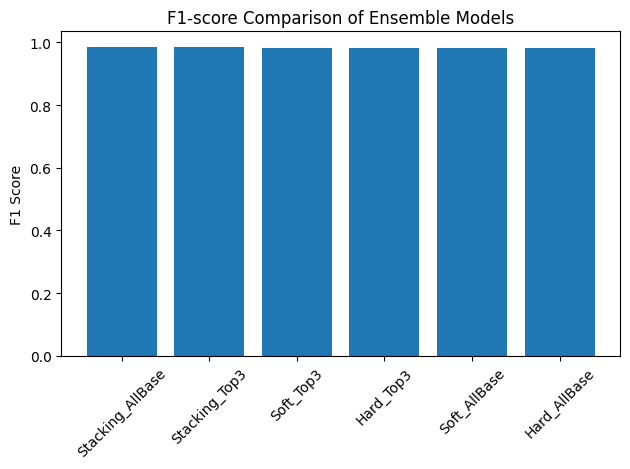

In [4]:
import matplotlib.pyplot as plt

plt.figure()

plt.bar(df_ensemble["Model"], df_ensemble["F1"])

plt.xticks(rotation=45)
plt.ylabel("F1 Score")
plt.title("F1-score Comparison of Ensemble Models")

plt.tight_layout()

plt.savefig("ensemble_f1_comparison.png", dpi=300)

plt.show()

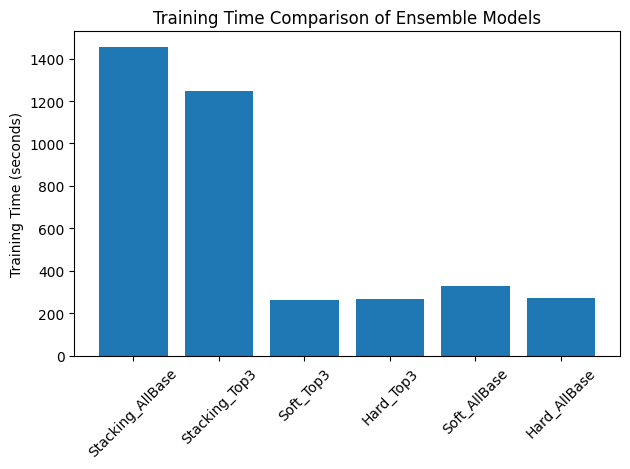

In [5]:
plt.figure()

plt.bar(df_ensemble["Model"], df_ensemble["TrainTime"])

plt.xticks(rotation=45)
plt.ylabel("Training Time (seconds)")
plt.title("Training Time Comparison of Ensemble Models")

plt.tight_layout()

plt.savefig("ensemble_training_time.png", dpi=300)

plt.show()

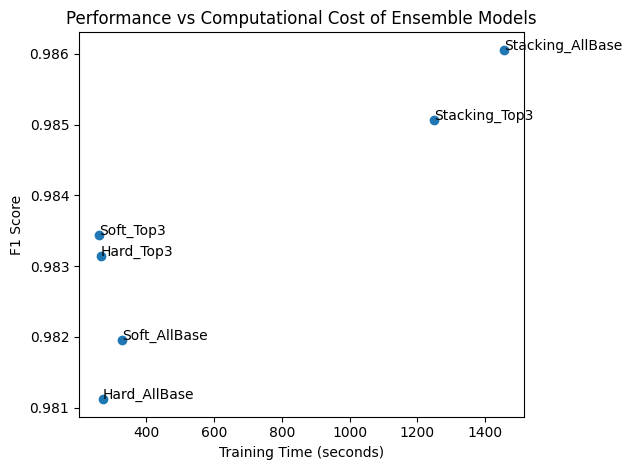

In [6]:
plt.figure()

plt.scatter(df_ensemble["TrainTime"], df_ensemble["F1"])

for i, txt in enumerate(df_ensemble["Model"]):
    plt.annotate(txt, (df_ensemble["TrainTime"][i], df_ensemble["F1"][i]))

plt.xlabel("Training Time (seconds)")
plt.ylabel("F1 Score")

plt.title("Performance vs Computational Cost of Ensemble Models")

plt.tight_layout()

plt.savefig("ensemble_pareto_analysis.png", dpi=300)

plt.show()

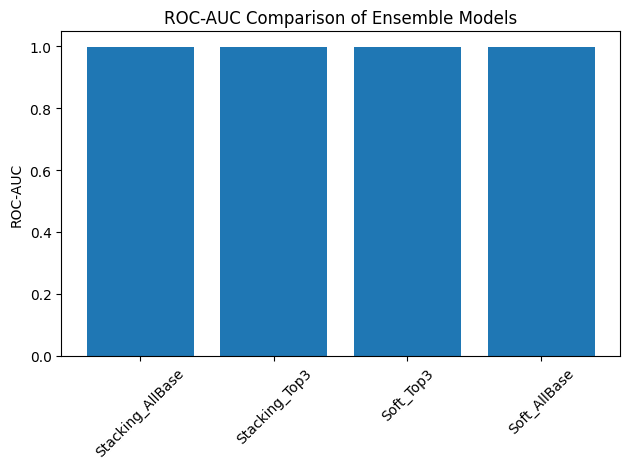

In [7]:
roc_df = df_ensemble.dropna(subset=["ROC_AUC"])

plt.figure()

plt.bar(roc_df["Model"], roc_df["ROC_AUC"])

plt.xticks(rotation=45)
plt.ylabel("ROC-AUC")
plt.title("ROC-AUC Comparison of Ensemble Models")

plt.tight_layout()

plt.savefig("ensemble_roc_auc.png", dpi=300)

plt.show()

In [8]:
import pandas as pd

data = {
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "XGBoost",
        "LightGBM",
        "CatBoost",
        "Stacking_AllBase",
        "Stacking_Top3",
        "Soft_Top3",
        "Hard_Top3",
        "Soft_AllBase",
        "Hard_AllBase"
    ],
    
    "F1":[
        0.9317,
        0.9697,
        0.9820,
        0.9777,
        0.9840,
        0.9796,
        0.986059,
        0.985068,
        0.983442,
        0.983150,
        0.981960,
        0.981118
    ],
    
    "TrainTime":[
        17.27,
        25.54,
        142.80,
        30.23,
        33.83,
        102.19,
        1455.828,
        1248.776,
        261.364,
        265.450,
        328.002,
        272.577
    ],
    
    "Type":[
        "Baseline","Baseline","Baseline","Baseline","Baseline","Baseline",
        "Ensemble","Ensemble","Ensemble","Ensemble","Ensemble","Ensemble"
    ]
}

df_models = pd.DataFrame(data)

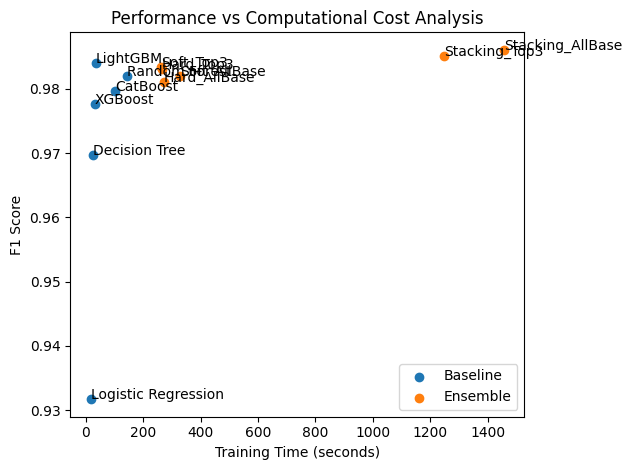

In [9]:
import matplotlib.pyplot as plt

plt.figure()

for t in df_models["Type"].unique():
    
    subset = df_models[df_models["Type"] == t]
    
    plt.scatter(subset["TrainTime"], subset["F1"], label=t)

for i, txt in enumerate(df_models["Model"]):
    plt.annotate(txt, (df_models["TrainTime"][i], df_models["F1"][i]))

plt.xlabel("Training Time (seconds)")
plt.ylabel("F1 Score")

plt.title("Performance vs Computational Cost Analysis")

plt.legend()

plt.tight_layout()

plt.savefig("performance_vs_cost.png", dpi=300)

plt.show()

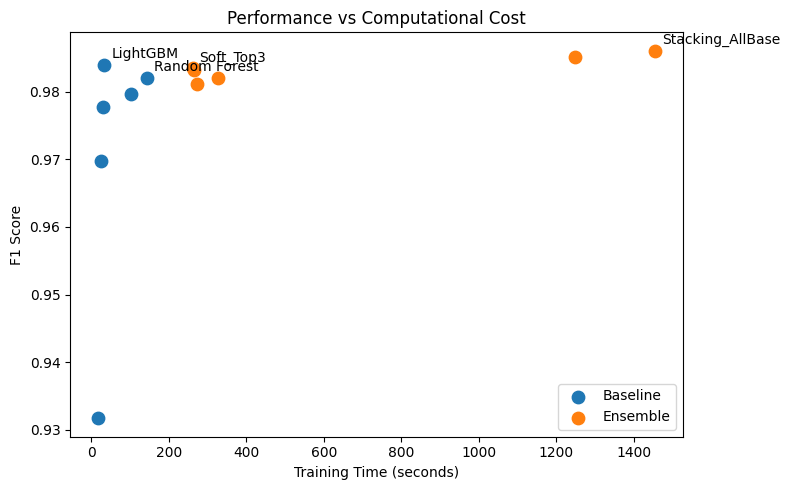

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

for t in df_models["Type"].unique():
    
    subset = df_models[df_models["Type"] == t]
    
    plt.scatter(
        subset["TrainTime"],
        subset["F1"],
        label=t,
        s=80
    )

# Sadece önemli modelleri etiketle
important_models = [
    "LightGBM",
    "Random Forest",
    "Stacking_AllBase",
    "Soft_Top3"
]

for i, row in df_models.iterrows():
    
    if row["Model"] in important_models:
        
        plt.annotate(
            row["Model"],
            (row["TrainTime"], row["F1"]),
            xytext=(5,5),
            textcoords="offset points"
        )

plt.xlabel("Training Time (seconds)")
plt.ylabel("F1 Score")

plt.title("Performance vs Computational Cost")

plt.legend()

plt.tight_layout()

plt.savefig("performance_vs_cost_clean.png", dpi=300)

plt.show()

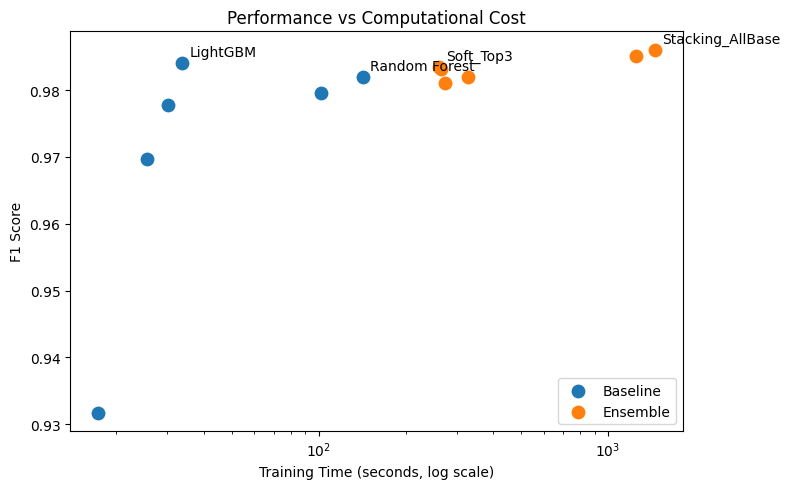

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

for t in df_models["Type"].unique():
    subset = df_models[df_models["Type"] == t]
    plt.scatter(subset["TrainTime"], subset["F1"], label=t, s=80)

important_models = ["LightGBM", "Random Forest", "Soft_Top3", "Stacking_AllBase"]

for _, row in df_models.iterrows():
    if row["Model"] in important_models:
        plt.annotate(
            row["Model"],
            (row["TrainTime"], row["F1"]),
            xytext=(5,5),
            textcoords="offset points"
        )

plt.xscale("log")
plt.xlabel("Training Time (seconds, log scale)")
plt.ylabel("F1 Score")
plt.title("Performance vs Computational Cost")
plt.legend()
plt.tight_layout()
plt.savefig("performance_vs_cost_logscale.png", dpi=300)
plt.show()

In [13]:
import os

os.listdir("outputs")

['.ipynb_checkpoints',
 'ALL_MODELS_TOP20_ACADEMIC_REPORT.txt',
 'CatBoost',
 'DecisionTree',
 'ENSEMBLES',
 'feature_analysis_stage6',
 'KNN',
 'LightGBM',
 'LogReg',
 'RandomForest',
 'XGBoost',
 '_shared']

In [15]:
import pandas as pd

df = pd.read_csv("~/Bitirme_Projesi_Dataset_Olusturma/Makale/outputs/_shared/shap_model_comparison_full.csv")

df.columns

Index(['feature', 'LogReg', 'DecisionTree', 'RandomForest', 'XGBoost',
       'LightGBM', 'CatBoost', 'ensemble_mean', 'LogReg_rank',
       'DecisionTree_rank', 'RandomForest_rank', 'XGBoost_rank',
       'LightGBM_rank', 'CatBoost_rank', 'ensemble_rank', 'top10_model_count'],
      dtype='object')

In [31]:
import pandas as pd
import matplotlib.pyplot as plt

# CSV'yi oku
df = pd.read_csv("~/Bitirme_Projesi_Dataset_Olusturma/Makale/outputs/_shared/shap_model_comparison_full.csv")

# LightGBM için feature importance seç
light = df[["feature", "LightGBM"]].copy()

# Büyükten küçüğe sırala
light = light.sort_values("LightGBM", ascending=False)

# Top 15 feature al
top_features = light.head(15)

# Grafik
plt.figure(figsize=(8,6))
plt.barh(top_features["feature"], top_features["LightGBM"])
plt.gca().invert_yaxis()

plt.xlabel("Mean |SHAP Value|")
plt.title("Global SHAP Feature Importance (LightGBM)")

plt.tight_layout()

# kaydetme pathini sen yaz


plt.show()

C:\Users\elifo\AppData\Local\Temp\ipykernel_13684\1998304088.py:29: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [32]:
import pandas as pd
import matplotlib.pyplot as plt

# CSV'yi oku
df = pd.read_csv("~/Bitirme_Projesi_Dataset_Olusturma/Makale/outputs/_shared/shap_model_comparison_full.csv")

# LightGBM için feature importance
light = df[["feature", "LightGBM"]].copy()

# büyükten küçüğe sırala ve top 12 al (makale için daha temiz)
top = light.sort_values("LightGBM", ascending=False).head(12)

# grafik
plt.figure(figsize=(10,7))

colors = ["#e91e63" if v > 0 else "#1e88e5" for v in top["LightGBM"]]

plt.barh(top["feature"], top["LightGBM"], color=colors)

plt.gca().invert_yaxis()
plt.axvline(0, color="black", linewidth=0.8)

plt.xlabel("Mean |SHAP value|")
plt.title("Global SHAP Feature Importance (LightGBM)")

plt.tight_layout()



plt.show()

C:\Users\elifo\AppData\Local\Temp\ipykernel_13684\3851084090.py:30: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [33]:
import os

os.getcwd()

'C:\\Users\\elifo\\Bitirme_Projesi_Dataset_Olusturma\\Makale'

In [34]:
os.listdir("outputs/LightGBM")

['cache_v1',
 'cases',
 'dependence',
 'dependence_634',
 'feature_analysis_from_cache',
 'global',
 'global_fulltest_approx',
 'global_shap_fixedstep_1500_200',
 'lime_local_v1',
 'lime_local_v2_400',
 'local_final',
 'local_lime',
 'local_shap',
 'local_v1',
 'metrics',
 'model_pipeline.joblib',
 'paper_local_xai_figures',
 'paper_tables',
 'perm_cache_beeswarm_v1',
 'perm_cache_v1',
 'shap_local_v2_400']

In [35]:
os.listdir("outputs/LightGBM/cache_v1")

['cache_meta.json', 'explain_X.csv', 'explain_y.csv', 'shap_values.npz']

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# SHAP cache yükle
X = pd.read_csv("outputs/LightGBM/cache_v1/explain_X.csv")
sv = np.load("outputs/LightGBM/cache_v1/shap_values.npz")["shap_values"]

mean_signed = sv.mean(axis=0)

df_plot = pd.DataFrame({
    "feature": X.columns,
    "mean_shap": mean_signed
})

top = df_plot.reindex(df_plot["mean_shap"].abs().sort_values(ascending=False).index).head(15)
top = top.sort_values("mean_shap")

plt.figure(figsize=(10,7))

colors = ["#1e88e5" if v < 0 else "#ff2b6a" for v in top["mean_shap"]]

plt.barh(top["feature"], top["mean_shap"], color=colors)

plt.axvline(0, color="gray")

plt.xlabel("mean(SHAP value)")
plt.title("Global SHAP Feature Impact (LightGBM)")

plt.tight_layout()

plt.savefig("figure_global_shap_lightgbm.png", dpi=300)

plt.show()

C:\Users\elifo\AppData\Local\Temp\ipykernel_13684\2650584709.py:34: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [38]:
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt

# SHAP cache dosyalarını yükle
X = pd.read_csv("outputs/LightGBM/cache_v1/explain_X.csv")
sv = np.load("outputs/LightGBM/cache_v1/shap_values.npz")["shap_values"]

# SHAP explanation objesi oluştur
expl = shap.Explanation(
    values=sv,
    data=X.values,
    feature_names=list(X.columns)
)

# Grafik
plt.figure(figsize=(10,7))

shap.plots.beeswarm(
    expl,
    max_display=15,
    show=False
)

# ✅ BAŞLIK (IEEE uyumlu)
plt.title(
    "Global Feature Importance Based on SHAP Values (LightGBM)",
    fontsize=13
)

plt.tight_layout()

# kaydet
plt.savefig(
    "figure_global_shap_beeswarm_lightgbm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

C:\Users\elifo\AppData\Local\Temp\ipykernel_13684\722102454.py:41: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [31]:
import pandas as pd
perm = pd.read_csv("~/Bitirme_Projesi_Dataset_Olusturma/Makale/outputs/_shared/permutation_importance_all_models/perm_summary_top1.csv")
print(perm.columns)
print(perm.head())

Index(['model', 'top1_feature', 'top1_importance'], dtype='object')
          model     top1_feature  top1_importance
0        LogReg  hostname_length         0.149942
1  DecisionTree  hostname_length         0.117410
2           KNN     entropy_path         0.021701
3  RandomForest  hostname_length         0.033444
4       XGBoost  hostname_length         0.052497


In [32]:
import pandas as pd

perm_top1 = pd.read_csv("~/Bitirme_Projesi_Dataset_Olusturma/Makale/outputs/_shared/permutation_importance_all_models/perm_summary_top1.csv")

light_top1 = perm_top1[perm_top1["model"] == "LightGBM"]
light_top1

,model,top1_feature,top1_importance
5,LightGBM,hostname_length,0.058377


In [36]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("~/Bitirme_Projesi_Dataset_Olusturma/Makale/final_lexical_dns_whois_cleaned.csv")

X = df.drop("label", axis=1)
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(463936, 76)
(115984, 76)


In [38]:
print("Orijinal X_train shape:", X_train.shape)
print("Object sütunları:", X_train.select_dtypes(include=["object"]).columns.tolist())

Orijinal X_train shape: (463936, 76)
Object sütunları: ['url']


In [39]:
X_train_model = X_train.copy()
X_test_model = X_test.copy()

if "url" in X_train_model.columns:
    X_train_model = X_train_model.drop(columns=["url"])
if "url" in X_test_model.columns:
    X_test_model = X_test_model.drop(columns=["url"])

print("Model için X_train shape:", X_train_model.shape)
print("Model için X_test shape :", X_test_model.shape)
print("Orijinal X_train shape tekrar:", X_train.shape)

Model için X_train shape: (463936, 75)
Model için X_test shape : (115984, 75)
Orijinal X_train shape tekrar: (463936, 76)


Original X_train: (463936, 76)
Original X_test : (115984, 76)
Model X_train   : (463936, 75)
Model X_test    : (115984, 75)
Dropped only for model input: ['url']
⏳ LightGBM eğitiliyor...
[LightGBM] [Info] Number of positive: 192677, number of negative: 271259
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.072059 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 6057
[LightGBM] [Info] Number of data points in the train set: 463936, number of used features: 75
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.415309 -> initscore=-0.342059
[LightGBM] [Info] Start training from score -0.342059
✅ Eğitim tamamlandı. Süre: 5.18 sn
⏳ Permutation importance hesaplanıyor (FULL TEST SET)...
✅ Permutation importance tamamlandı. Süre: 114.96 sn


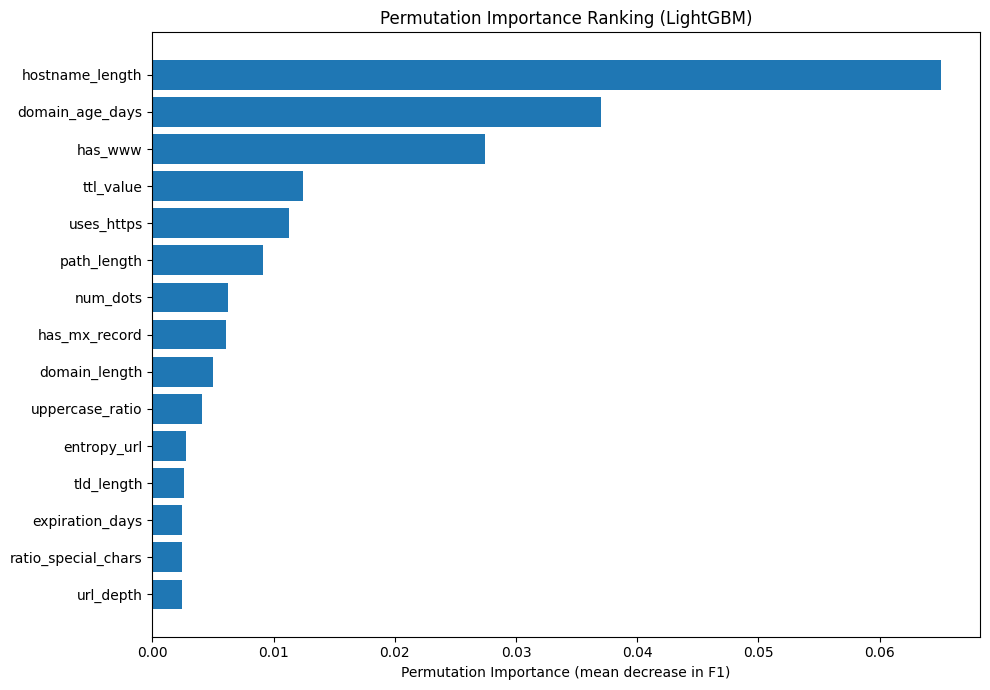

,feature,importance_mean,importance_std
2,hostname_length,0.065020,0.000537
66,domain_age_days,0.036984,0.000227
39,has_www,0.027446,0.000377
61,ttl_value,0.012434,0.000346
38,uses_https,0.011283,0.000225
3,path_length,0.009135,0.000174
13,num_dots,0.006279,0.000329
58,has_mx_record,0.006074,0.000276
1,domain_length,0.004977,0.000088
33,uppercase_ratio,0.004083,0.000183


In [40]:
import os
import json
import time
import joblib
import pandas as pd
import matplotlib.pyplot as plt

from lightgbm import LGBMClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score, make_scorer

BASE_DIR = os.path.expanduser("~/Bitirme_Projesi_Dataset_Olusturma/Makale")
CACHE_DIR = os.path.join(BASE_DIR, "outputs", "LightGBM", "perm_cache_v1")
os.makedirs(CACHE_DIR, exist_ok=True)

# Orijinal dataset bozulmadan, sadece model için geçici kopya
X_train_model = X_train.copy()
X_test_model = X_test.copy()

dropped_for_model = []
for col in ["url"]:
    if col in X_train_model.columns:
        X_train_model = X_train_model.drop(columns=[col])
        dropped_for_model.append(col)
    if col in X_test_model.columns:
        X_test_model = X_test_model.drop(columns=[col])

print("Original X_train:", X_train.shape)
print("Original X_test :", X_test.shape)
print("Model X_train   :", X_train_model.shape)
print("Model X_test    :", X_test_model.shape)
print("Dropped only for model input:", dropped_for_model)

# LightGBM parametreleri
LGBM_PARAMS = {
    "random_state": 42,
    "n_jobs": -1
}

model_path = os.path.join(CACHE_DIR, "lightgbm_model.joblib")
perm_csv_path = os.path.join(CACHE_DIR, "lightgbm_permutation_importance_full.csv")
perm_plot_path = os.path.join(CACHE_DIR, "lightgbm_permutation_importance_top15.png")
meta_path = os.path.join(CACHE_DIR, "lightgbm_permutation_importance_meta.json")

# Model
if os.path.exists(model_path):
    print("✅ Kayıtlı model bulundu, yükleniyor...")
    model = joblib.load(model_path)
else:
    print("⏳ LightGBM eğitiliyor...")
    t0 = time.time()
    model = LGBMClassifier(**LGBM_PARAMS)
    model.fit(X_train_model, y_train)
    train_time = time.time() - t0
    print(f"✅ Eğitim tamamlandı. Süre: {train_time:.2f} sn")
    joblib.dump(model, model_path)

# Permutation Importance
if os.path.exists(perm_csv_path):
    print("✅ Kayıtlı permutation importance bulundu, yükleniyor...")
    perm_df = pd.read_csv(perm_csv_path)
else:
    print("⏳ Permutation importance hesaplanıyor (FULL TEST SET)...")
    t0 = time.time()

    result = permutation_importance(
        estimator=model,
        X=X_test_model,
        y=y_test,
        scoring=make_scorer(f1_score),
        n_repeats=5,
        random_state=42,
        n_jobs=-1
    )

    perm_time = time.time() - t0
    print(f"✅ Permutation importance tamamlandı. Süre: {perm_time:.2f} sn")

    perm_df = pd.DataFrame({
        "feature": X_test_model.columns,
        "importance_mean": result.importances_mean,
        "importance_std": result.importances_std
    }).sort_values("importance_mean", ascending=False)

    perm_df.to_csv(perm_csv_path, index=False)

    meta = {
        "model": "LightGBM",
        "scoring": "f1",
        "n_repeats": 5,
        "random_state": 42,
        "original_train_shape": list(X_train.shape),
        "original_test_shape": list(X_test.shape),
        "model_train_shape": list(X_train_model.shape),
        "model_test_shape": list(X_test_model.shape),
        "dropped_only_for_model_input": dropped_for_model,
        "full_test_used": True
    }

    with open(meta_path, "w", encoding="utf-8") as f:
        json.dump(meta, f, indent=2, ensure_ascii=False)

# Grafik
plot_df = perm_df.head(15).sort_values("importance_mean", ascending=True)

plt.figure(figsize=(10, 7))
plt.barh(plot_df["feature"], plot_df["importance_mean"])
plt.xlabel("Permutation Importance (mean decrease in F1)")
plt.title("Permutation Importance Ranking (LightGBM)")
plt.tight_layout()
plt.savefig(perm_plot_path, dpi=300, bbox_inches="tight")
plt.show()

perm_df.head(15)

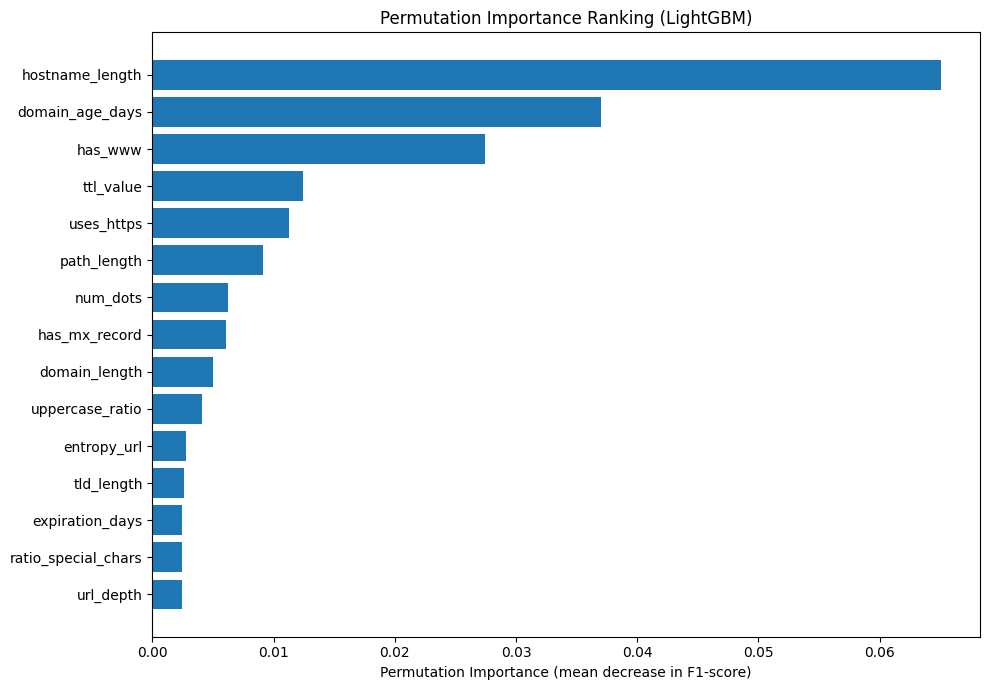

In [41]:
import pandas as pd
import matplotlib.pyplot as plt

# permutation importance csv
perm_df = pd.read_csv("outputs/LightGBM/perm_cache_v1/lightgbm_permutation_importance_full.csv")

# top 15
plot_df = perm_df.head(15).sort_values("importance_mean", ascending=True)

plt.figure(figsize=(10, 7))

plt.barh(plot_df["feature"], plot_df["importance_mean"])

plt.xlabel("Permutation Importance (mean decrease in F1-score)")
plt.title("Permutation Importance Ranking (LightGBM)")

plt.tight_layout()

plt.savefig(
    "figure_permutation_importance_lightgbm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

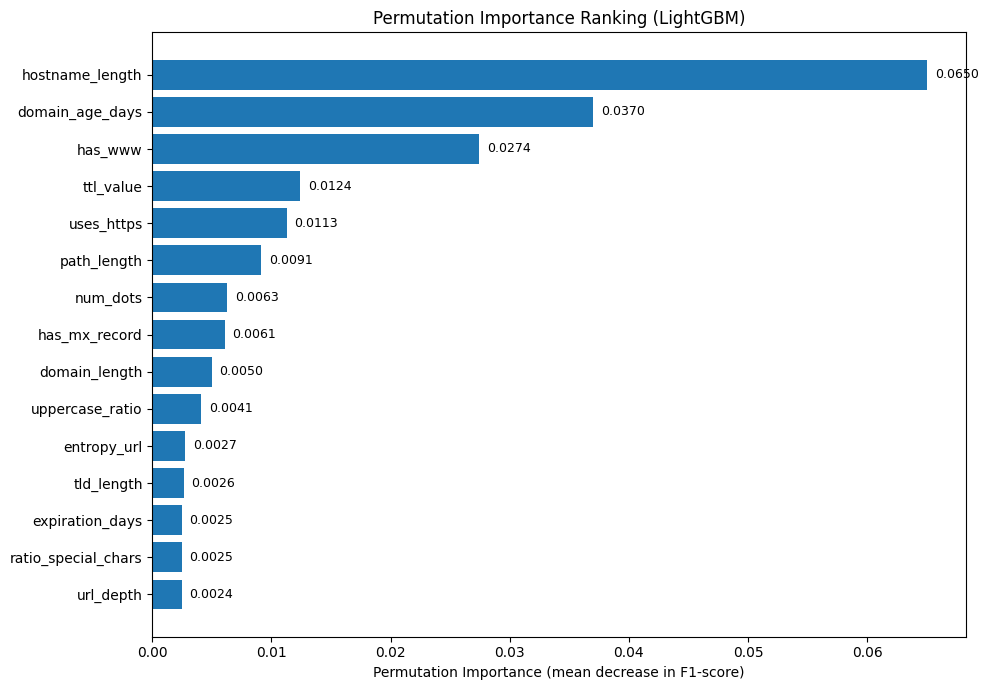

In [42]:
import pandas as pd
import matplotlib.pyplot as plt

perm_df = pd.read_csv("outputs/LightGBM/perm_cache_v1/lightgbm_permutation_importance_full.csv")

plot_df = perm_df.head(15).sort_values("importance_mean", ascending=True)

plt.figure(figsize=(10, 7))

bars = plt.barh(
    plot_df["feature"],
    plot_df["importance_mean"]
)

plt.xlabel("Permutation Importance (mean decrease in F1-score)")
plt.title("Permutation Importance Ranking (LightGBM)")

# değer etiketleri
max_val = plot_df["importance_mean"].max()
for bar, val in zip(bars, plot_df["importance_mean"]):
    plt.text(
        val + max_val * 0.01,
        bar.get_y() + bar.get_height()/2,
        f"{val:.4f}",
        va="center",
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    "figure_permutation_importance_lightgbm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [30]:
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt

X = pd.read_csv("outputs/LightGBM/cache_v1/explain_X.csv")
sv = np.load("outputs/LightGBM/cache_v1/shap_values.npz")["shap_values"]

expl = shap.Explanation(
    values=sv,
    data=X.values,
    feature_names=list(X.columns)
)

plt.figure(figsize=(10,7))

shap.plots.beeswarm(
    expl,
    max_display=20,
    show=False
)

plt.tight_layout()
plt.savefig(
    "figure_global_shap_beeswarm_lightgbm.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

C:\Users\elifo\AppData\Local\Temp\ipykernel_13684\42770483.py:29: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Original X_train: (463936, 76)
Original X_test : (115984, 76)
Model X_train   : (463936, 75)
Model X_test    : (115984, 75)
Dropped only for model input: ['url']
✅ Kayıtlı model bulundu, yükleniyor...
✅ Kayıtlı permutation importance bulundu, yükleniyor...


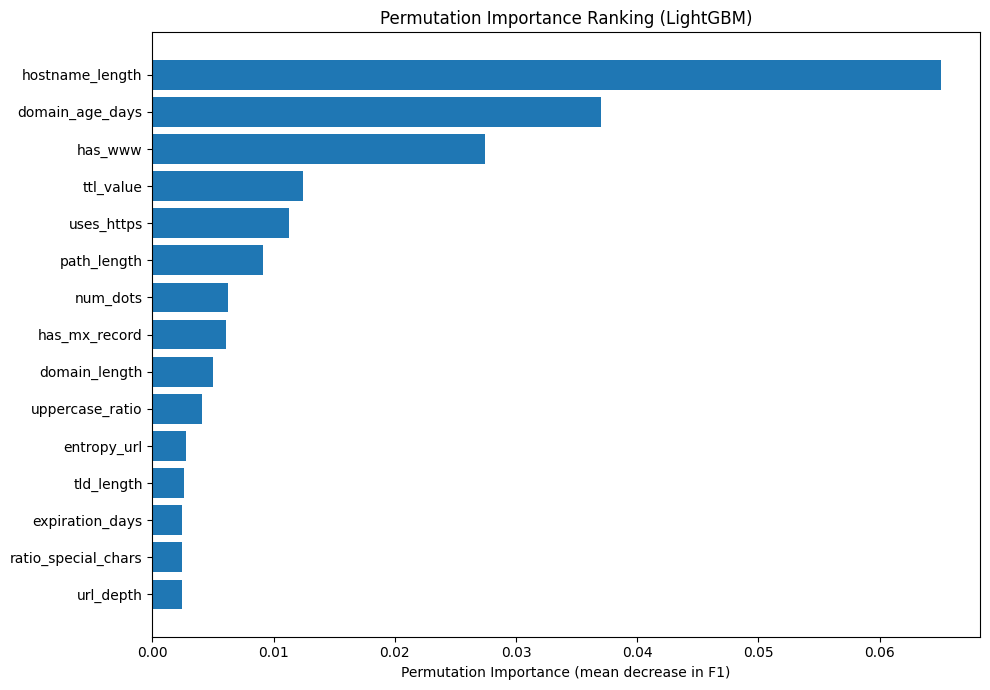

,feature,importance_mean,importance_std
0,hostname_length,0.065020,0.000537
1,domain_age_days,0.036984,0.000227
2,has_www,0.027446,0.000377
3,ttl_value,0.012434,0.000346
4,uses_https,0.011283,0.000225
5,path_length,0.009135,0.000174
6,num_dots,0.006279,0.000329
7,has_mx_record,0.006074,0.000276
8,domain_length,0.004977,0.000088
9,uppercase_ratio,0.004083,0.000183


In [45]:
import os
import json
import time
import joblib
import pandas as pd
import matplotlib.pyplot as plt

from lightgbm import LGBMClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score, make_scorer

BASE_DIR = os.path.expanduser("~/Bitirme_Projesi_Dataset_Olusturma/Makale")
CACHE_DIR = os.path.join(BASE_DIR, "outputs", "LightGBM", "perm_cache_v1")
os.makedirs(CACHE_DIR, exist_ok=True)

# Orijinal dataset bozulmadan, sadece model için geçici kopya
X_train_model = X_train.copy()
X_test_model = X_test.copy()

dropped_for_model = []
for col in ["url"]:
    if col in X_train_model.columns:
        X_train_model = X_train_model.drop(columns=[col])
        dropped_for_model.append(col)
    if col in X_test_model.columns:
        X_test_model = X_test_model.drop(columns=[col])

print("Original X_train:", X_train.shape)
print("Original X_test :", X_test.shape)
print("Model X_train   :", X_train_model.shape)
print("Model X_test    :", X_test_model.shape)
print("Dropped only for model input:", dropped_for_model)

# LightGBM parametreleri
LGBM_PARAMS = {
    "random_state": 42,
    "n_jobs": -1
}

model_path = os.path.join(CACHE_DIR, "lightgbm_model.joblib")
perm_csv_path = os.path.join(CACHE_DIR, "lightgbm_permutation_importance_full.csv")
perm_plot_path = os.path.join(CACHE_DIR, "lightgbm_permutation_importance_top15.png")
meta_path = os.path.join(CACHE_DIR, "lightgbm_permutation_importance_meta.json")

# Model
if os.path.exists(model_path):
    print("✅ Kayıtlı model bulundu, yükleniyor...")
    model = joblib.load(model_path)
else:
    print("⏳ LightGBM eğitiliyor...")
    t0 = time.time()
    model = LGBMClassifier(**LGBM_PARAMS)
    model.fit(X_train_model, y_train)
    train_time = time.time() - t0
    print(f"✅ Eğitim tamamlandı. Süre: {train_time:.2f} sn")
    joblib.dump(model, model_path)

# Permutation Importance
if os.path.exists(perm_csv_path):
    print("✅ Kayıtlı permutation importance bulundu, yükleniyor...")
    perm_df = pd.read_csv(perm_csv_path)
else:
    print("⏳ Permutation importance hesaplanıyor (FULL TEST SET)...")
    t0 = time.time()

    result = permutation_importance(
        estimator=model,
        X=X_test_model,
        y=y_test,
        scoring=make_scorer(f1_score),
        n_repeats=5,
        random_state=42,
        n_jobs=-1
    )

    perm_time = time.time() - t0
    print(f"✅ Permutation importance tamamlandı. Süre: {perm_time:.2f} sn")

    perm_df = pd.DataFrame({
        "feature": X_test_model.columns,
        "importance_mean": result.importances_mean,
        "importance_std": result.importances_std
    }).sort_values("importance_mean", ascending=False)

    perm_df.to_csv(perm_csv_path, index=False)

    meta = {
        "model": "LightGBM",
        "scoring": "f1",
        "n_repeats": 5,
        "random_state": 42,
        "original_train_shape": list(X_train.shape),
        "original_test_shape": list(X_test.shape),
        "model_train_shape": list(X_train_model.shape),
        "model_test_shape": list(X_test_model.shape),
        "dropped_only_for_model_input": dropped_for_model,
        "full_test_used": True
    }

    with open(meta_path, "w", encoding="utf-8") as f:
        json.dump(meta, f, indent=2, ensure_ascii=False)

# Grafik
plot_df = perm_df.head(15).sort_values("importance_mean", ascending=True)

plt.figure(figsize=(10, 7))
plt.barh(plot_df["feature"], plot_df["importance_mean"])
plt.xlabel("Permutation Importance (mean decrease in F1)")
plt.title("Permutation Importance Ranking (LightGBM)")
plt.tight_layout()
plt.savefig(perm_plot_path, dpi=300, bbox_inches="tight")
plt.show()

perm_df.head(15)

In [48]:
import os
import json
import time
import joblib
import numpy as np
import pandas as pd

from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score, make_scorer

BASE_DIR = os.path.expanduser("~/Bitirme_Projesi_Dataset_Olusturma/Makale")
CACHE_DIR = os.path.join(BASE_DIR, "outputs", "LightGBM", "perm_cache_beeswarm_v1")
os.makedirs(CACHE_DIR, exist_ok=True)

# Orijinal veri bozulmadan model girdisi
X_test_model = X_test.copy()
if "url" in X_test_model.columns:
    X_test_model = X_test_model.drop(columns=["url"])

# Cached model (senin daha önce oluşturduğun model)
model_path = os.path.join(BASE_DIR, "outputs", "LightGBM", "perm_cache_v1", "lightgbm_model.joblib")
model = joblib.load(model_path)
print("✅ Cached LightGBM loaded.")

perm_csv_path = os.path.join(CACHE_DIR, "lightgbm_permutation_importance_full.csv")
perm_npz_path = os.path.join(CACHE_DIR, "lightgbm_permutation_importance_repeats.npz")
meta_path = os.path.join(CACHE_DIR, "lightgbm_permutation_importance_meta.json")

print("⏳ Calculating permutation importance with repeat-level scores...")
t0 = time.time()

result = permutation_importance(
    estimator=model,
    X=X_test_model,
    y=y_test,
    scoring=make_scorer(f1_score),
    n_repeats=20,      # 10 da olur, 20 daha dolu görünür
    random_state=42,
    n_jobs=-1
)

elapsed = time.time() - t0
print(f"✅ Done in {elapsed:.2f} sec")

perm_df = pd.DataFrame({
    "feature": X_test_model.columns,
    "importance_mean": result.importances_mean,
    "importance_std": result.importances_std
}).sort_values("importance_mean", ascending=False)

perm_df.to_csv(perm_csv_path, index=False)

np.savez_compressed(
    perm_npz_path,
    importances=result.importances,            # (n_features, n_repeats)
    feature_names=np.array(X_test_model.columns, dtype=object)
)

with open(meta_path, "w", encoding="utf-8") as f:
    json.dump({
        "model": "LightGBM",
        "scoring": "f1",
        "n_repeats": 20,
        "random_state": 42,
        "test_shape": list(X_test_model.shape),
        "dropped_only_for_model_input": ["url"] if "url" in X_test.columns else []
    }, f, indent=2, ensure_ascii=False)

perm_df.head(15)

✅ Cached LightGBM loaded.
⏳ Calculating permutation importance with repeat-level scores...
✅ Done in 329.76 sec


,feature,importance_mean,importance_std
2,hostname_length,0.065127,0.000724
66,domain_age_days,0.036810,0.000511
39,has_www,0.027557,0.000455
61,ttl_value,0.012524,0.000313
38,uses_https,0.011205,0.000271
3,path_length,0.008985,0.000299
13,num_dots,0.006246,0.000231
58,has_mx_record,0.006126,0.000264
1,domain_length,0.004901,0.000208
33,uppercase_ratio,0.003946,0.000176


In [53]:
import os
import json
import time
import joblib
import numpy as np
import pandas as pd

from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score, make_scorer

BASE_DIR = os.path.expanduser("~/Bitirme_Projesi_Dataset_Olusturma/Makale")
CACHE_DIR = os.path.join(BASE_DIR, "outputs", "LightGBM", "perm_cache_beeswarm_v1")
os.makedirs(CACHE_DIR, exist_ok=True)

# Orijinal veri bozulmadan model girdisi
X_test_model = X_test.copy()
if "url" in X_test_model.columns:
    X_test_model = X_test_model.drop(columns=["url"])

# Cached model (senin daha önce oluşturduğun model)
model_path = os.path.join(BASE_DIR, "outputs", "LightGBM", "perm_cache_v1", "lightgbm_model.joblib")
model = joblib.load(model_path)
print("✅ Cached LightGBM loaded.")

perm_csv_path = os.path.join(CACHE_DIR, "lightgbm_permutation_importance_full.csv")
perm_npz_path = os.path.join(CACHE_DIR, "lightgbm_permutation_importance_repeats.npz")
meta_path = os.path.join(CACHE_DIR, "lightgbm_permutation_importance_meta.json")

print("⏳ Calculating permutation importance with repeat-level scores...")
t0 = time.time()

result = permutation_importance(
    estimator=model,
    X=X_test_model,
    y=y_test,
    scoring=make_scorer(f1_score),
    n_repeats=30,      # 10 da olur, 20 daha dolu görünür
    random_state=42,
    n_jobs=-1
)

elapsed = time.time() - t0
print(f"✅ Done in {elapsed:.2f} sec")

perm_df = pd.DataFrame({
    "feature": X_test_model.columns,
    "importance_mean": result.importances_mean,
    "importance_std": result.importances_std
}).sort_values("importance_mean", ascending=False)

perm_df.to_csv(perm_csv_path, index=False)

np.savez_compressed(
    perm_npz_path,
    importances=result.importances,            # (n_features, n_repeats)
    feature_names=np.array(X_test_model.columns, dtype=object)
)

with open(meta_path, "w", encoding="utf-8") as f:
    json.dump({
        "model": "LightGBM",
        "scoring": "f1",
        "n_repeats": 20,
        "random_state": 42,
        "test_shape": list(X_test_model.shape),
        "dropped_only_for_model_input": ["url"] if "url" in X_test.columns else []
    }, f, indent=2, ensure_ascii=False)

perm_df.head(15)

✅ Cached LightGBM loaded.
⏳ Calculating permutation importance with repeat-level scores...
✅ Done in 525.74 sec


,feature,importance_mean,importance_std
2,hostname_length,0.065211,0.000659
66,domain_age_days,0.036796,0.000523
39,has_www,0.027486,0.000526
61,ttl_value,0.012530,0.000282
38,uses_https,0.011174,0.000287
3,path_length,0.008913,0.000323
13,num_dots,0.006215,0.000252
58,has_mx_record,0.006140,0.000242
1,domain_length,0.004919,0.000220
33,uppercase_ratio,0.003949,0.000182


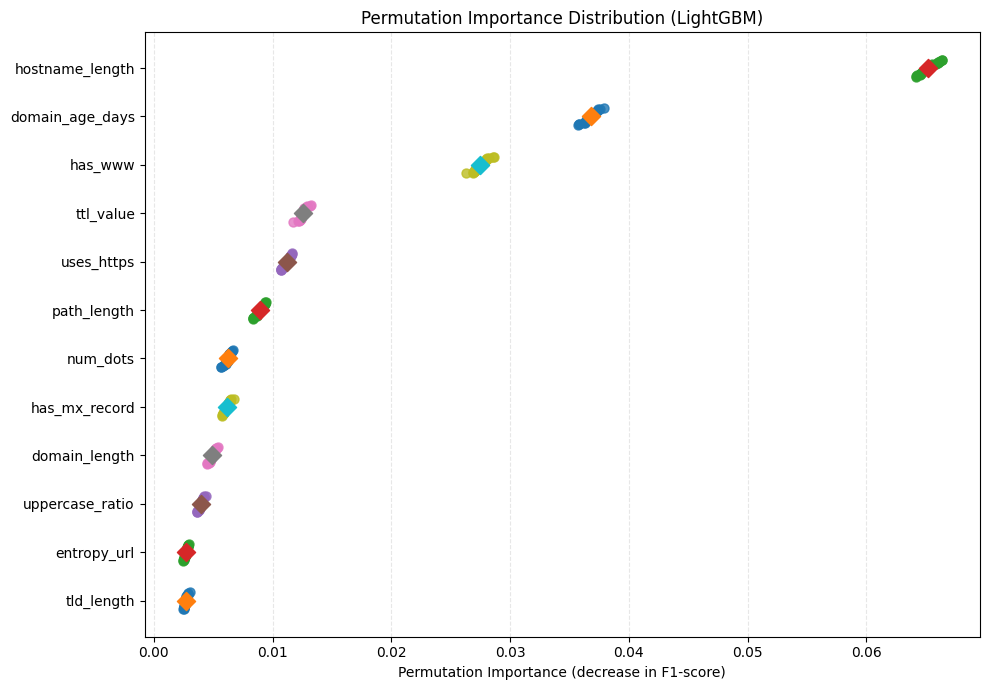

In [54]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR = os.path.expanduser("~/Bitirme_Projesi_Dataset_Olusturma/Makale")
CACHE_DIR = os.path.join(BASE_DIR, "outputs", "LightGBM", "perm_cache_beeswarm_v1")

perm_df = pd.read_csv(os.path.join(CACHE_DIR, "lightgbm_permutation_importance_full.csv"))
npz = np.load(os.path.join(CACHE_DIR, "lightgbm_permutation_importance_repeats.npz"), allow_pickle=True)

importances = npz["importances"]
feature_names = list(npz["feature_names"])

top_features = perm_df.head(12)["feature"].tolist()
feat_to_idx = {f: i for i, f in enumerate(feature_names)}

plt.figure(figsize=(10, 7))

order = top_features[::-1]

for i, feat in enumerate(order):
    idx = feat_to_idx[feat]
    vals = importances[idx]
    vals = np.sort(vals)

    # sıralı değerlere simetrik jitter
    center = len(vals) // 2
    offsets = np.array([(j - center) for j in range(len(vals))], dtype=float)
    offsets = offsets / max(abs(offsets).max(), 1) * 0.18

    plt.scatter(vals, i + offsets, s=42, alpha=0.8)
    plt.scatter(vals.mean(), i, s=85, marker="D")

plt.yticks(range(len(order)), order)
plt.xlabel("Permutation Importance (decrease in F1-score)")
plt.title("Permutation Importance Distribution (LightGBM)")
plt.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "figure_permutation_importance_beeswarm_lightgbm_v2.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

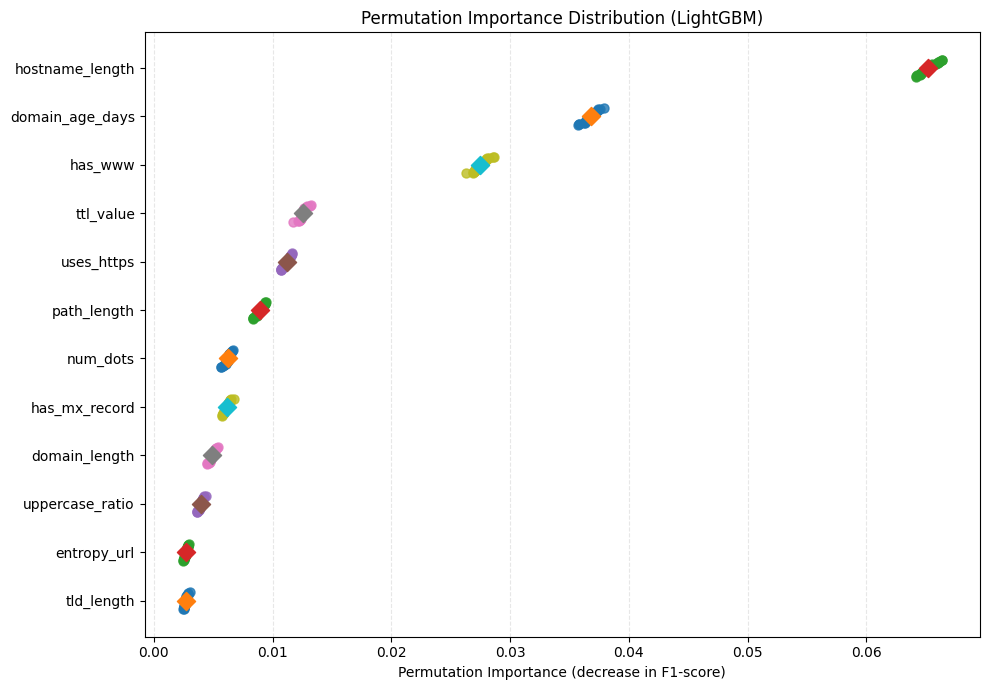

In [55]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR = os.path.expanduser("~/Bitirme_Projesi_Dataset_Olusturma/Makale")
CACHE_DIR = os.path.join(BASE_DIR, "outputs", "LightGBM", "perm_cache_beeswarm_v1")

perm_df = pd.read_csv(os.path.join(CACHE_DIR, "lightgbm_permutation_importance_full.csv"))
npz = np.load(os.path.join(CACHE_DIR, "lightgbm_permutation_importance_repeats.npz"), allow_pickle=True)

importances = npz["importances"]
feature_names = list(npz["feature_names"])

top_features = perm_df.head(12)["feature"].tolist()
feat_to_idx = {f: i for i, f in enumerate(feature_names)}

plt.figure(figsize=(10, 7))

order = top_features[::-1]

for i, feat in enumerate(order):
    idx = feat_to_idx[feat]
    vals = importances[idx]
    vals = np.sort(vals)

    # sıralı değerlere simetrik jitter
    center = len(vals) // 2
    offsets = np.array([(j - center) for j in range(len(vals))], dtype=float)
    offsets = offsets / max(abs(offsets).max(), 1) * 0.18

    plt.scatter(vals, i + offsets, s=42, alpha=0.8)
    plt.scatter(vals.mean(), i, s=85, marker="D")

plt.yticks(range(len(order)), order)
plt.xlabel("Permutation Importance (decrease in F1-score)")
plt.title("Permutation Importance Distribution (LightGBM)")
plt.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "figure_permutation_importance_beeswarm_lightgbm_v2.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

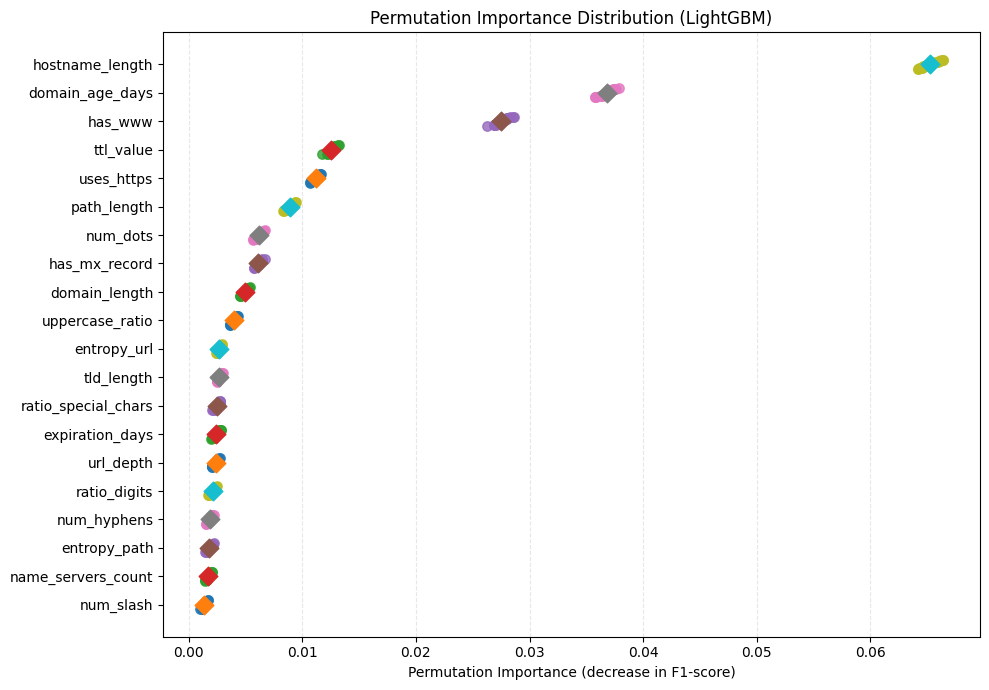

In [58]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR = os.path.expanduser("~/Bitirme_Projesi_Dataset_Olusturma/Makale")
CACHE_DIR = os.path.join(BASE_DIR, "outputs", "LightGBM", "perm_cache_beeswarm_v1")

perm_df = pd.read_csv(os.path.join(CACHE_DIR, "lightgbm_permutation_importance_full.csv"))
npz = np.load(os.path.join(CACHE_DIR, "lightgbm_permutation_importance_repeats.npz"), allow_pickle=True)

importances = npz["importances"]
feature_names = list(npz["feature_names"])

top_features = perm_df.head(20)["feature"].tolist()
feat_to_idx = {f: i for i, f in enumerate(feature_names)}

plt.figure(figsize=(10, 7))
order = top_features[::-1]

for i, feat in enumerate(order):
    idx = feat_to_idx[feat]
    vals = np.array(importances[idx], dtype=float)
    vals = np.sort(vals)

    jitter = np.linspace(-0.16, 0.16, len(vals))
    y = np.full(len(vals), i, dtype=float) + jitter

    plt.scatter(vals, y, s=46, alpha=0.8)
    plt.scatter(vals.mean(), i, s=90, marker="D")

plt.yticks(range(len(order)), order)
plt.xlabel("Permutation Importance (decrease in F1-score)")
plt.title("Permutation Importance Distribution (LightGBM)")
plt.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "figure_permutation_importance_beeswarm_lightgbm_clean.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

✅ Cache başarıyla yüklendi
X shape: (10000, 75)
SHAP shape: (10000, 75)
Kaydetme klasörü: C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\dependence_634

Eşleşen feature'lar:
 - hostname_length -> hostname_length
 - url_length -> url_length
 - number_of_dots -> num_dots
 - number_of_hyphens -> num_hyphens

⚠️ Eşleşmeyen feature'lar:
 - number_of_subdomains


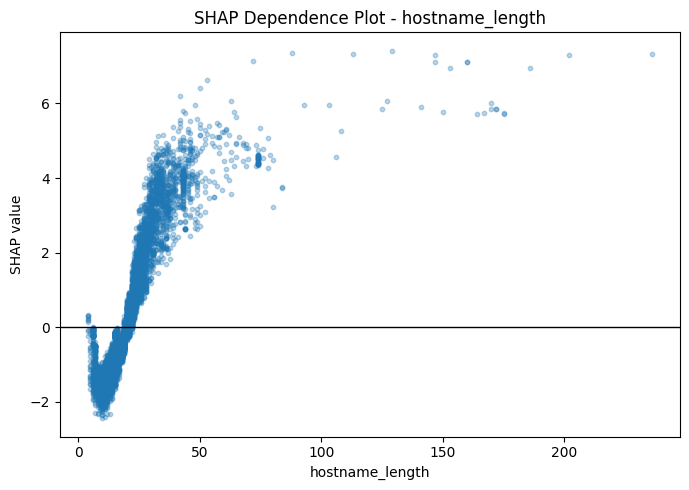

✅ Kaydedildi: C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\dependence_634\dependence_hostname_length.png


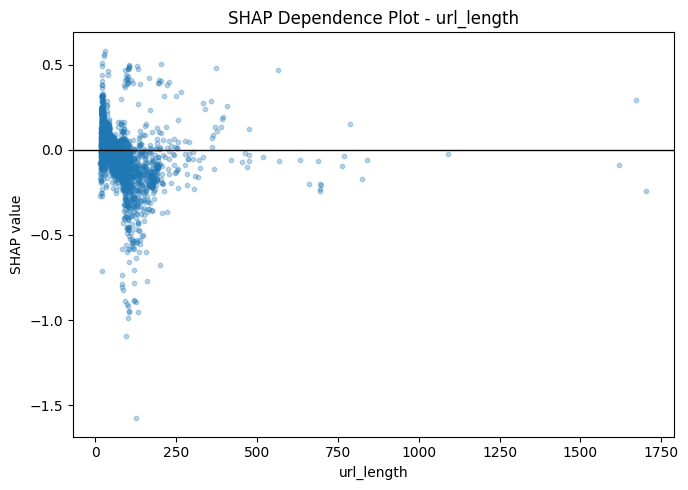

✅ Kaydedildi: C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\dependence_634\dependence_url_length.png


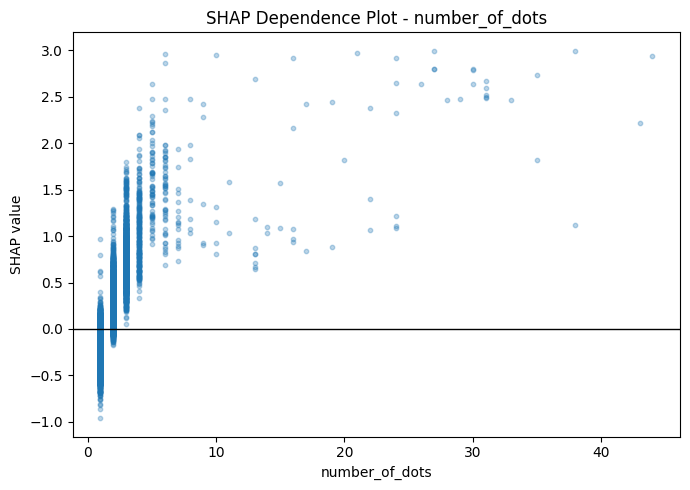

✅ Kaydedildi: C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\dependence_634\dependence_number_of_dots.png


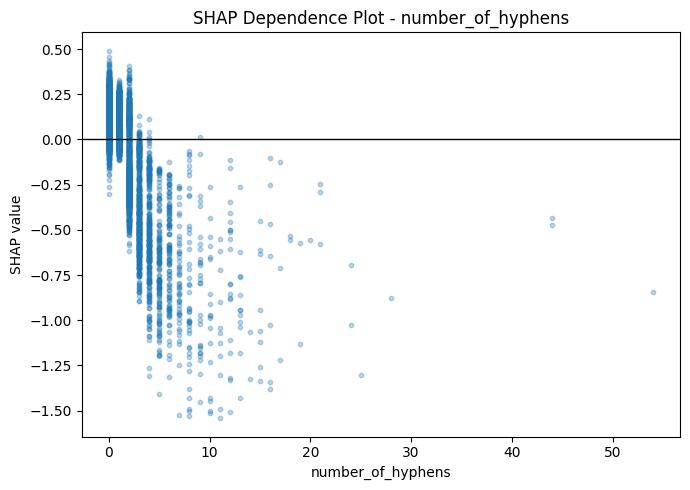

✅ Kaydedildi: C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\dependence_634\dependence_number_of_hyphens.png

🎉 6.3.4 için dependence grafikleri üretildi.


In [60]:
# =========================================================
# 6.3.4 - LIGHTGBM TOP-5 SHAP DEPENDENCE PLOTS
# Kernel reset sonrası tek hücrede yeniden üretim
# =========================================================

import os
import json
import difflib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# AYARLAR
# -----------------------------
BASE_DIR = Path(os.path.expanduser("~/Bitirme_Projesi_Dataset_Olusturma/Makale"))
OUT_DIR = BASE_DIR / "outputs"
MODEL_NAME = "LightGBM"
CACHE_TAG = "cache_v1"

CACHE_DIR = OUT_DIR / MODEL_NAME / CACHE_TAG
SAVE_DIR = OUT_DIR / MODEL_NAME / "dependence_634"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# Metinde kullanmak istediğin feature'lar
REQUESTED_FEATURES = [
    "hostname_length",
    "url_length",
    "number_of_dots",
    "number_of_hyphens",
    "number_of_subdomains",
]

PLOT_MAX_POINTS = 15000
SEED = 42
rng = np.random.RandomState(SEED)

# -----------------------------
# HELPER
# -----------------------------
def find_existing_path(candidates):
    for p in candidates:
        if p.exists():
            return p
    return None

def safe_filename(s: str) -> str:
    return "".join(c if c.isalnum() or c in "._-" else "_" for c in s)

def sample_for_plot(x, s, max_points=PLOT_MAX_POINTS, seed=SEED):
    if len(x) <= max_points:
        return x, s
    rng_local = np.random.RandomState(seed)
    idx = rng_local.choice(len(x), size=max_points, replace=False)
    return x[idx], s[idx]

def resolve_feature_name(requested_name, actual_columns):
    """
    Birebir eşleşme yoksa benzer isim bulmaya çalışır.
    """
    if requested_name in actual_columns:
        return requested_name

    # Küçük-büyük harf duyarsız arama
    lower_map = {c.lower(): c for c in actual_columns}
    if requested_name.lower() in lower_map:
        return lower_map[requested_name.lower()]

    # Alt çizgi / boşluk / tire normalize et
    def norm(s):
        return s.lower().replace("-", "_").replace(" ", "_")

    norm_map = {norm(c): c for c in actual_columns}
    if norm(requested_name) in norm_map:
        return norm_map[norm(requested_name)]

    # Yakın eşleşme
    candidates = difflib.get_close_matches(requested_name, list(actual_columns), n=1, cutoff=0.6)
    if candidates:
        return candidates[0]

    return None

# -----------------------------
# CACHE DOSYALARINI BUL
# -----------------------------
if not CACHE_DIR.exists():
    raise FileNotFoundError(f"Cache klasörü bulunamadı: {CACHE_DIR}")

X_path = find_existing_path([
    CACHE_DIR / "explain_X.csv",
    CACHE_DIR / "X_explain.csv",
])

y_path = find_existing_path([
    CACHE_DIR / "explain_y.csv",
    CACHE_DIR / "y_explain.csv",
])

sv_path = CACHE_DIR / "shap_values.npz"
meta_path = CACHE_DIR / "cache_meta.json"

if X_path is None:
    raise FileNotFoundError(f"X dosyası bulunamadı. Kontrol edilen klasör: {CACHE_DIR}")

if y_path is None:
    raise FileNotFoundError(f"y dosyası bulunamadı. Kontrol edilen klasör: {CACHE_DIR}")

if not sv_path.exists():
    raise FileNotFoundError(f"SHAP dosyası bulunamadı: {sv_path}")

# -----------------------------
# VERİYİ YÜKLE
# -----------------------------
X = pd.read_csv(X_path)
y = pd.read_csv(y_path).iloc[:, 0].astype(int)

npz = np.load(sv_path)
if "shap_values" not in npz:
    raise KeyError(f"{sv_path} içinde 'shap_values' anahtarı bulunamadı. Anahtarlar: {list(npz.keys())}")

shap_values = npz["shap_values"]

meta = {}
if meta_path.exists():
    with open(meta_path, "r", encoding="utf-8") as f:
        meta = json.load(f)

feature_cols = meta.get("feature_cols", list(X.columns))
X = X[feature_cols]

if shap_values.shape[0] != len(X) or shap_values.shape[1] != X.shape[1]:
    raise ValueError(
        f"Shape uyuşmazlığı var. X={X.shape}, shap_values={shap_values.shape}"
    )

print("✅ Cache başarıyla yüklendi")
print("X shape:", X.shape)
print("SHAP shape:", shap_values.shape)
print("Kaydetme klasörü:", SAVE_DIR)

# -----------------------------
# FEATURE İSİMLERİNİ ÇÖZ
# -----------------------------
resolved_features = {}
missing_features = []

for feat in REQUESTED_FEATURES:
    resolved = resolve_feature_name(feat, X.columns)
    if resolved is None:
        missing_features.append(feat)
    else:
        resolved_features[feat] = resolved

print("\nEşleşen feature'lar:")
for req, real in resolved_features.items():
    print(f" - {req} -> {real}")

if missing_features:
    print("\n⚠️ Eşleşmeyen feature'lar:")
    for feat in missing_features:
        print(" -", feat)

# -----------------------------
# PLOT FONKSİYONU
# -----------------------------
def plot_dependence(feature_requested, feature_actual):
    feat_idx = list(X.columns).index(feature_actual)

    x = X[feature_actual].to_numpy()
    s = shap_values[:, feat_idx]

    x_plot, s_plot = sample_for_plot(x, s)

    plt.figure(figsize=(7, 5))
    plt.scatter(x_plot, s_plot, alpha=0.30, s=10)
    plt.axhline(0, color="black", linewidth=1)
    plt.xlabel(feature_requested)
    plt.ylabel("SHAP value")
    plt.title(f"SHAP Dependence Plot - {feature_requested}")
    plt.tight_layout()

    save_path = SAVE_DIR / f"dependence_{safe_filename(feature_requested)}.png"
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    print(f"✅ Kaydedildi: {save_path}")

# -----------------------------
# TÜM GRAFİKLERİ ÜRET
# -----------------------------
for req_feat in REQUESTED_FEATURES:
    if req_feat in resolved_features:
        plot_dependence(req_feat, resolved_features[req_feat])

print("\n🎉 6.3.4 için dependence grafikleri üretildi.")

In [61]:
print(list(X.columns))

['url_length', 'domain_length', 'hostname_length', 'path_length', 'first_dir_length', 'tld_length', 'tld_length_domain', 'url_depth', 'query_length', 'path_segments_count', 'num_digits', 'num_letters', 'num_special_chars', 'num_dots', 'num_hyphens', 'num_at', 'num_percent', 'num_equals', 'num_question', 'num_ampersand', 'num_hash', 'num_underscore', 'num_special', 'num_slash', 'num_params', 'entropy_url', 'entropy_hostname', 'entropy_domain', 'entropy_path', 'query_entropy', 'ratio_digits', 'ratio_letters', 'ratio_special_chars', 'uppercase_ratio', 'lowercase_ratio', 'is_ip_address', 'starts_with_ip', 'is_suspicious_tld', 'uses_https', 'has_www', 'num_at.1', 'unusual_double_slash', 'multiple_http', 'contains_port_number', 'path_has_encoded_chars', 'query_has_base64', 'contains_login', 'contains_secure', 'contains_verify', 'contains_account', 'contains_update', 'contains_bank', 'contains_cloud', 'contains_brand', 'query_key_count', 'query_value_length_avg', 'success', 'dns_resolves', 'h

In [66]:
import pandas as pd

corr = pd.read_csv("~/Bitirme_Projesi_Dataset_Olusturma/Makale/outputs/_shared/shap_vs_permutation_correlation.csv")

corr

,model,n_features_compared,spearman_rho,p_value,top20_overlap_count,perm_col_used
0,DecisionTree,75,0.967819,1.739524e-45,18,importance_mean
1,LightGBM,75,0.965563,1.982013e-44,17,importance_mean
2,CatBoost,75,0.943103,1.214374e-36,17,importance_mean
3,XGBoost,75,0.940904,4.662491e-36,17,importance_mean
4,LogReg,75,0.926225,1.179161e-32,19,importance_mean
5,RandomForest,75,0.861765,3.282675e-23,10,importance_mean


In [67]:
print(corr.columns)
print(corr.shape)

Index(['model', 'n_features_compared', 'spearman_rho', 'p_value',
       'top20_overlap_count', 'perm_col_used'],
      dtype='object')
(6, 6)


In [68]:
# =========================================================
# TABLE X - LightGBM only
# Correlation between SHAP and permutation feature rankings
# =========================================================

import os
from pathlib import Path
import pandas as pd

# ---------------------------------------------------------
# 1) DOSYA YOLUNU BUL
# ---------------------------------------------------------
candidate_paths = [
    Path("shap_vs_permutation_correlation.csv"),
    Path("/mnt/data/shap_vs_permutation_correlation.csv"),
    Path(os.path.expanduser("~/Bitirme_Projesi_Dataset_Olusturma/Makale/shap_vs_permutation_correlation.csv")),
]

csv_path = None
for p in candidate_paths:
    if p.exists():
        csv_path = p
        break

if csv_path is None:
    raise FileNotFoundError(
        "shap_vs_permutation_correlation.csv bulunamadı. "
        "Dosya yolunu kontrol et."
    )

print(f"✅ Dosya bulundu: {csv_path}")

# ---------------------------------------------------------
# 2) CSV'Yİ YÜKLE
# ---------------------------------------------------------
corr = pd.read_csv(csv_path)

required_cols = ["model", "spearman_rho", "p_value", "top20_overlap_count"]
missing = [c for c in required_cols if c not in corr.columns]
if missing:
    raise ValueError(f"CSV içinde gerekli kolon(lar) eksik: {missing}")

# ---------------------------------------------------------
# 3) SADECE LIGHTGBM SATIRINI AL
# ---------------------------------------------------------
light_corr = corr[corr["model"].astype(str).str.strip().str.lower() == "lightgbm"].copy()

if light_corr.empty:
    raise ValueError("CSV içinde LightGBM satırı bulunamadı.")

# ---------------------------------------------------------
# 4) MAKALİK TABLOYU OLUŞTUR
# ---------------------------------------------------------
table_light = light_corr[required_cols].copy()
table_light["model"] = "LightGBM"

table_light.columns = [
    "Model",
    "Spearman Correlation",
    "p-value",
    "Top-20 Feature Overlap"
]

table_light["Spearman Correlation"] = table_light["Spearman Correlation"].round(3)
table_light["p-value"] = table_light["p-value"].map(lambda x: f"{x:.2e}")

# ---------------------------------------------------------
# 5) GÖSTER
# ---------------------------------------------------------
print("\nTable X. Correlation between SHAP and permutation feature rankings")
display(table_light)

# ---------------------------------------------------------
# 6) KAYDET
# ---------------------------------------------------------
save_csv = csv_path.parent / "tableX_lightgbm_shap_permutation_correlation.csv"
table_light.to_csv(save_csv, index=False)

print(f"\n✅ LightGBM tablo kaydedildi: {save_csv}")

FileNotFoundError: shap_vs_permutation_correlation.csv bulunamadı. Dosya yolunu kontrol et.

In [69]:
# =========================================================
# Table X – LightGBM SHAP vs Permutation Correlation
# corr dataframe'inden doğrudan üretim
# =========================================================

import pandas as pd

# LightGBM satırını seç
light_corr = corr[corr["model"] == "LightGBM"].copy()

# Makaleye uygun tablo
table_light = light_corr[[
    "model",
    "spearman_rho",
    "p_value",
    "top20_overlap_count"
]]

table_light.columns = [
    "Model",
    "Spearman Correlation",
    "p-value",
    "Top-20 Feature Overlap"
]

# Format
table_light["Spearman Correlation"] = table_light["Spearman Correlation"].round(3)
table_light["p-value"] = table_light["p-value"].map(lambda x: f"{x:.2e}")

table_light

,Model,Spearman Correlation,p-value,Top-20 Feature Overlap
1,LightGBM,0.966,1.98e-44,17


In [71]:
# =========================================================
# LIGHTGBM - SHAP vs Permutation
# Table X + Table Y for paper
# =========================================================

import os
import json
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import spearmanr

# ---------------------------------------------------------
# 1) BASE PATH
# ---------------------------------------------------------
base_candidates = [
    Path(r"C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale"),
    Path(os.path.expanduser("~/Bitirme_Projesi_Dataset_Olusturma/Makale")),
    Path(".")
]

BASE_DIR = None
for p in base_candidates:
    if p.exists():
        BASE_DIR = p
        break

if BASE_DIR is None:
    raise FileNotFoundError("Makale ana klasörü bulunamadı.")

print(f"✅ BASE_DIR: {BASE_DIR}")

# ---------------------------------------------------------
# 2) PATHS
# ---------------------------------------------------------
SHAP_CACHE_DIR = BASE_DIR / "outputs" / "LightGBM" / "cache_v1"
PERM_CACHE_DIR = BASE_DIR / "outputs" / "LightGBM" / "perm_cache_v1"
SAVE_DIR = BASE_DIR / "outputs" / "LightGBM" / "paper_tables"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

X_path_candidates = [
    SHAP_CACHE_DIR / "explain_X.csv",
    SHAP_CACHE_DIR / "X_explain.csv",
]
meta_path = SHAP_CACHE_DIR / "cache_meta.json"
shap_npz_path = SHAP_CACHE_DIR / "shap_values.npz"

perm_csv_candidates = [
    PERM_CACHE_DIR / "lightgbm_permutation_importance_full.csv",
    PERM_CACHE_DIR / "permutation_importance_full.csv",
]

X_path = next((p for p in X_path_candidates if p.exists()), None)
perm_csv_path = next((p for p in perm_csv_candidates if p.exists()), None)

if X_path is None:
    raise FileNotFoundError(f"SHAP explain_X.csv bulunamadı: {SHAP_CACHE_DIR}")

if not shap_npz_path.exists():
    raise FileNotFoundError(f"shap_values.npz bulunamadı: {shap_npz_path}")

if perm_csv_path is None:
    raise FileNotFoundError(f"Permutation importance CSV bulunamadı: {PERM_CACHE_DIR}")

print(f"✅ X path: {X_path}")
print(f"✅ SHAP npz path: {shap_npz_path}")
print(f"✅ Perm path: {perm_csv_path}")

# ---------------------------------------------------------
# 3) LOAD SHAP
# ---------------------------------------------------------
X = pd.read_csv(X_path)

npz = np.load(shap_npz_path, allow_pickle=True)
if "shap_values" not in npz:
    raise KeyError(f"'shap_values' anahtarı bulunamadı. Anahtarlar: {list(npz.keys())}")

shap_values = npz["shap_values"]

if meta_path.exists():
    with open(meta_path, "r", encoding="utf-8") as f:
        meta = json.load(f)
    feature_cols = meta.get("feature_cols", list(X.columns))
else:
    feature_cols = list(X.columns)

X = X[feature_cols]

if shap_values.shape[1] != len(feature_cols):
    raise ValueError(
        f"SHAP sütun sayısı ile feature sayısı uyuşmuyor. "
        f"shap_values.shape={shap_values.shape}, n_features={len(feature_cols)}"
    )

# Mean absolute SHAP importance
mean_abs_shap = np.abs(shap_values).mean(axis=0)

shap_rank_df = pd.DataFrame({
    "feature": feature_cols,
    "shap_importance": mean_abs_shap
}).sort_values("shap_importance", ascending=False).reset_index(drop=True)

shap_rank_df["shap_rank"] = np.arange(1, len(shap_rank_df) + 1)

# ---------------------------------------------------------
# 4) LOAD PERMUTATION
# ---------------------------------------------------------
perm_df = pd.read_csv(perm_csv_path)

if "feature" not in perm_df.columns:
    raise KeyError(f"Permutation CSV içinde 'feature' kolonu yok. Kolonlar: {list(perm_df.columns)}")

perm_col_candidates = [
    "importance_mean",
    "importance",
    "mean_importance",
    "perm_importance",
]

perm_col_used = next((c for c in perm_col_candidates if c in perm_df.columns), None)

if perm_col_used is None:
    raise KeyError(
        f"Permutation importance kolonu bulunamadı. "
        f"Beklenenlerden biri olmalı: {perm_col_candidates}. "
        f"Mevcut kolonlar: {list(perm_df.columns)}"
    )

perm_rank_df = perm_df[["feature", perm_col_used]].copy()
perm_rank_df = perm_rank_df.rename(columns={perm_col_used: "perm_importance"})
perm_rank_df = perm_rank_df.sort_values("perm_importance", ascending=False).reset_index(drop=True)
perm_rank_df["perm_rank"] = np.arange(1, len(perm_rank_df) + 1)

# ---------------------------------------------------------
# 5) MERGE + CORRELATION
# ---------------------------------------------------------
merged = pd.merge(
    shap_rank_df[["feature", "shap_importance", "shap_rank"]],
    perm_rank_df[["feature", "perm_importance", "perm_rank"]],
    on="feature",
    how="inner"
).copy()

rho, p_value = spearmanr(merged["shap_rank"], merged["perm_rank"])

# overlap sets
top10_shap = set(merged.nsmallest(10, "shap_rank")["feature"])
top10_perm = set(merged.nsmallest(10, "perm_rank")["feature"])
top20_shap = set(merged.nsmallest(20, "shap_rank")["feature"])
top20_perm = set(merged.nsmallest(20, "perm_rank")["feature"])

top10_overlap = len(top10_shap & top10_perm)
top20_overlap = len(top20_shap & top20_perm)

# ---------------------------------------------------------
# 6) TABLE X
# ---------------------------------------------------------
table_x = pd.DataFrame([{
    "Model": "LightGBM",
    "Features Compared": int(len(merged)),
    "Spearman Correlation": round(float(rho), 3),
    "p-value": f"{p_value:.2e}",
    "Top-10 Feature Overlap": int(top10_overlap),
    "Top-20 Feature Overlap": int(top20_overlap)
}])

print("\nTable X. Correlation between SHAP and permutation feature rankings for the LightGBM model")
display(table_x)

# ---------------------------------------------------------
# 7) TABLE Y
#    Features appearing in SHAP top10 or Perm top10
# ---------------------------------------------------------
table_y = merged[
    (merged["shap_rank"] <= 10) | (merged["perm_rank"] <= 10)
].copy()

table_y["Appears in Both Top-10"] = np.where(
    (table_y["shap_rank"] <= 10) & (table_y["perm_rank"] <= 10),
    "Yes",
    "No"
)

table_y["best_rank"] = table_y[["shap_rank", "perm_rank"]].min(axis=1)

table_y = table_y.sort_values(
    by=["Appears in Both Top-10", "best_rank", "shap_rank", "perm_rank"],
    ascending=[False, True, True, True]
).reset_index(drop=True)

table_y = table_y[[
    "feature",
    "shap_rank",
    "perm_rank",
    "Appears in Both Top-10"
]].copy()

table_y.columns = [
    "Feature",
    "SHAP Rank",
    "Permutation Rank",
    "Appears in Both Top-10"
]

print("\nTable Y. Top-10 agreement between SHAP and permutation rankings for the LightGBM model")
display(table_y)

# ---------------------------------------------------------
# 8) SAVE
# ---------------------------------------------------------
table_x_path = SAVE_DIR / "tableX_lightgbm_shap_permutation_correlation.csv"
table_y_path = SAVE_DIR / "tableY_lightgbm_top10_agreement.csv"

table_x.to_csv(table_x_path, index=False)
table_y.to_csv(table_y_path, index=False)

print(f"\n✅ Table X kaydedildi: {table_x_path}")
print(f"✅ Table Y kaydedildi: {table_y_path}")

✅ BASE_DIR: C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale
✅ X path: C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\cache_v1\explain_X.csv
✅ SHAP npz path: C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\cache_v1\shap_values.npz
✅ Perm path: C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\perm_cache_v1\lightgbm_permutation_importance_full.csv

Table X. Correlation between SHAP and permutation feature rankings for the LightGBM model


,Model,Features Compared,Spearman Correlation,p-value,Top-10 Feature Overlap,Top-20 Feature Overlap
0,LightGBM,75,0.916,1.04e-30,8,17



Table Y. Top-10 agreement between SHAP and permutation rankings for the LightGBM model


,Feature,SHAP Rank,Permutation Rank,Appears in Both Top-10
0,has_www,1,3,Yes
1,hostname_length,2,1,Yes
2,domain_age_days,4,2,Yes
3,has_mx_record,3,8,Yes
4,ttl_value,6,4,Yes
5,uses_https,7,5,Yes
6,num_dots,8,7,Yes
7,domain_length,9,9,Yes
8,entropy_path,5,19,No
9,path_length,13,6,No



✅ Table X kaydedildi: C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\paper_tables\tableX_lightgbm_shap_permutation_correlation.csv
✅ Table Y kaydedildi: C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\paper_tables\tableY_lightgbm_top10_agreement.csv


In [41]:
# =========================================================
# 6.3.4 - SHAP Dependence Plots (Top-5 Shared Features)
# =========================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# PATH
# ---------------------------------------------------------
BASE_DIR = os.path.expanduser("~/Bitirme_Projesi_Dataset_Olusturma/Makale")
CACHE_DIR = os.path.join(BASE_DIR, "outputs", "LightGBM", "cache_v1")

X_path = os.path.join(CACHE_DIR, "explain_X.csv")
meta_path = os.path.join(CACHE_DIR, "cache_meta.json")
shap_path = os.path.join(CACHE_DIR, "shap_values.npz")

# ---------------------------------------------------------
# LOAD DATA
# ---------------------------------------------------------
X = pd.read_csv(X_path)

npz = np.load(shap_path)
shap_values = npz["shap_values"]

with open(meta_path, "r") as f:
    meta = json.load(f)

feature_cols = meta["feature_cols"]
X = X[feature_cols]

# ---------------------------------------------------------
# TOP FEATURES (SHARED)
# ---------------------------------------------------------
top_features = [
    "hostname_length",
    "domain_age_days",
    "num_dots",
    "domain_length",
    "ttl_value"
]

# ---------------------------------------------------------
# PLOT
# ---------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, feat in enumerate(top_features):

    idx = feature_cols.index(feat)

    axes[i].scatter(
        X[feat],
        shap_values[:, idx],
        s=8,
        alpha=0.25
    )

    axes[i].axhline(0, linestyle="--")
    axes[i].set_title(feat)
    axes[i].set_xlabel(feat)
    axes[i].set_ylabel("SHAP value")

# boş subplot
axes[-1].axis("off")

plt.suptitle(
    "SHAP Dependence Plots for the Top-5 Shared Features (LightGBM)",
    fontsize=14
)

plt.tight_layout()
plt.show()

C:\Users\elifo\AppData\Local\Temp\ipykernel_13684\3131074640.py:77: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [47]:
# =====================================================
# 6.3.4 SHAP Dependence Plots (Top-5 Shared Features)
# =====================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR = os.path.expanduser("~/Bitirme_Projesi_Dataset_Olusturma/Makale")

CACHE_DIR = os.path.join(
    BASE_DIR,
    "outputs",
    "LightGBM",
    "cache_v1"
)

X_path = os.path.join(CACHE_DIR, "explain_X.csv")
meta_path = os.path.join(CACHE_DIR, "cache_meta.json")
shap_path = os.path.join(CACHE_DIR, "shap_values.npz")

# ----------------------------------------------------
# Load data
# ----------------------------------------------------

X = pd.read_csv(X_path)

npz = np.load(shap_path)
shap_values = npz["shap_values"]

with open(meta_path, "r") as f:
    meta = json.load(f)

feature_cols = meta["feature_cols"]
X = X[feature_cols]

# ----------------------------------------------------
# Top shared features
# ----------------------------------------------------

top_features = [
    "hostname_length",
    "has_www",
    "domain_age_days",
    "ttl_value",
    "has_mx_record"
]

# ----------------------------------------------------
# Plot
# ----------------------------------------------------

fig, axes = plt.subplots(2,3, figsize=(15,8))
axes = axes.flatten()

for i,feat in enumerate(top_features):

    idx = feature_cols.index(feat)

    axes[i].scatter(
        X[feat],
        shap_values[:,idx],
        s=8,
        alpha=0.3
    )

    axes[i].axhline(0, linestyle="--")
    axes[i].set_title(feat)
    axes[i].set_xlabel(feat)
    axes[i].set_ylabel("SHAP value")

axes[-1].axis("off")

plt.suptitle(
    "SHAP Dependence Plots for Top-5 Shared Features (LightGBM)",
    fontsize=14
)

plt.tight_layout()
plt.savefig(
    os.path.join(BASE_DIR, "outputs", "shap_dependence_top5.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.close()

In [74]:
# =========================================================
# 6.4 Incremental Global SHAP Analysis
# STEP 1 - Find and load stability files
# =========================================================

import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BASE_CANDIDATES = [
    Path(r"C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale"),
    Path(os.path.expanduser("~/Bitirme_Projesi_Dataset_Olusturma/Makale")),
    Path(".")
]

BASE_DIR = None
for p in BASE_CANDIDATES:
    if p.exists():
        BASE_DIR = p
        break

if BASE_DIR is None:
    raise FileNotFoundError("Makale ana klasörü bulunamadı.")

print("BASE_DIR:", BASE_DIR)

# Aranacak muhtemel klasörler
SEARCH_DIRS = [
    BASE_DIR / "outputs" / "LightGBM",
    BASE_DIR / "outputs" / "_shared",
    BASE_DIR / "outputs",
]

# Muhtemel dosya isimleri
stability_candidates = [
    "global_shap_stability_fixed_200_500_1000_1500.csv",
    "global_shap_stability_200_500_1000_1500.csv",
    "global_shap_stability.csv",
]

matrix_candidates = [
    "global_shap_stability_fixed_matrix.csv",
    "global_shap_stability_matrix.csv",
]

stability_csv = None
matrix_csv = None

for root in SEARCH_DIRS:
    if not root.exists():
        continue
    for path in root.rglob("*.csv"):
        if path.name in stability_candidates and stability_csv is None:
            stability_csv = path
        if path.name in matrix_candidates and matrix_csv is None:
            matrix_csv = path

print("stability_csv:", stability_csv)
print("matrix_csv:", matrix_csv)

if stability_csv is None:
    raise FileNotFoundError(
        "Stability CSV bulunamadı. "
        "global_shap_stability_fixed_200_500_1000_1500.csv benzeri dosyanı kontrol et."
    )

stability_df = pd.read_csv(stability_csv)
print("\nStability table preview:")
display(stability_df.head())

if matrix_csv is not None:
    matrix_df = pd.read_csv(matrix_csv, index_col=0)
    print("\nMatrix table preview:")
    display(matrix_df)
else:
    matrix_df = None
    print("\nMatrix CSV bulunamadı; correlation heatmap pairwise table'dan üretilecek.")

BASE_DIR: C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale
stability_csv: C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\ENSEMBLES\EnsembleSoft\global_shap_stability.csv
matrix_csv: C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\ENSEMBLES\EnsembleSoft\global_shap_stability_fixed_matrix.csv

Stability table preview:


,N_a,N_b,top20_overlap,spearman_top100_union
0,200,500,0.95,0.994452
1,200,1000,0.95,0.991835
2,500,1000,1.00,0.996871



Matrix table preview:


,200,500,1000,1500
200,1.000000,0.991067,0.992319,0.990669
500,0.991067,1.000000,0.996387,0.995078
1000,0.992319,0.996387,1.000000,0.998122
1500,0.990669,0.995078,0.998122,1.000000


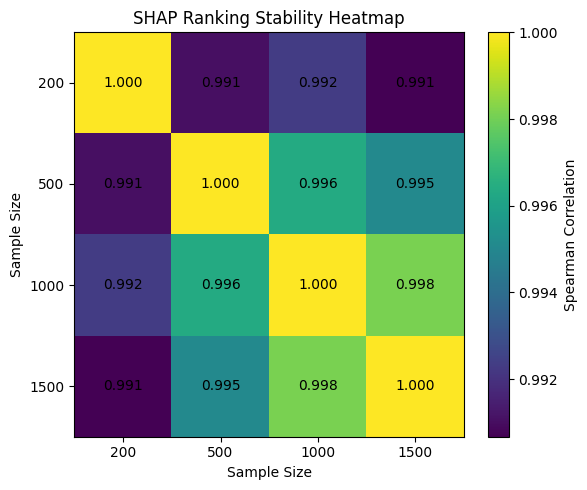

In [75]:
# =========================================================
# STEP 2 - SHAP ranking correlation heatmap
# =========================================================

def build_matrix_from_pairwise(df):
    """
    Pairwise stability tablosundan simetrik Spearman matrix üretir.
    Beklenen kolonlar:
      N_a, N_b, spearman_top100_union
    """
    required = {"N_a", "N_b", "spearman_top100_union"}
    if not required.issubset(df.columns):
        raise ValueError(f"Gerekli kolonlar yok. Beklenen: {required}, mevcut: {set(df.columns)}")

    sample_sizes = sorted(set(df["N_a"]).union(set(df["N_b"])))
    mat = pd.DataFrame(np.eye(len(sample_sizes)), index=sample_sizes, columns=sample_sizes)

    for _, row in df.iterrows():
        a = row["N_a"]
        b = row["N_b"]
        val = row["spearman_top100_union"]
        mat.loc[a, b] = val
        mat.loc[b, a] = val

    return mat

if matrix_df is None:
    corr_matrix = build_matrix_from_pairwise(stability_df)
else:
    corr_matrix = matrix_df.copy()

plt.figure(figsize=(6,5))
plt.imshow(corr_matrix.values, aspect="auto")
plt.colorbar(label="Spearman Correlation")
plt.xticks(range(len(corr_matrix.columns)), corr_matrix.columns)
plt.yticks(range(len(corr_matrix.index)), corr_matrix.index)
plt.title("SHAP Ranking Stability Heatmap")
plt.xlabel("Sample Size")
plt.ylabel("Sample Size")

for i in range(len(corr_matrix.index)):
    for j in range(len(corr_matrix.columns)):
        plt.text(j, i, f"{corr_matrix.iloc[i, j]:.3f}", ha="center", va="center")

plt.tight_layout()
plt.show()

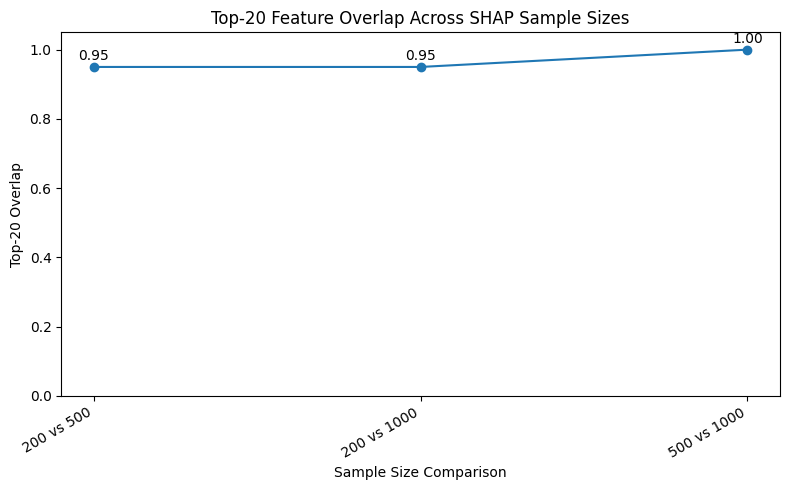

In [76]:
# =========================================================
# STEP 3 - Top-20 overlap plot
# =========================================================

required_cols = {"N_a", "N_b", "top20_overlap"}
if not required_cols.issubset(stability_df.columns):
    raise ValueError(f"Top-20 overlap grafiği için gerekli kolonlar yok: {required_cols}")

plot_df = stability_df.copy()
plot_df["Comparison"] = plot_df["N_a"].astype(str) + " vs " + plot_df["N_b"].astype(str)

plt.figure(figsize=(8,5))
plt.plot(plot_df["Comparison"], plot_df["top20_overlap"], marker="o")
plt.ylim(0, 1.05)
plt.ylabel("Top-20 Overlap")
plt.xlabel("Sample Size Comparison")
plt.title("Top-20 Feature Overlap Across SHAP Sample Sizes")
plt.xticks(rotation=30, ha="right")

for i, v in enumerate(plot_df["top20_overlap"]):
    plt.text(i, v + 0.02, f"{v:.2f}", ha="center")

plt.tight_layout()
plt.show()

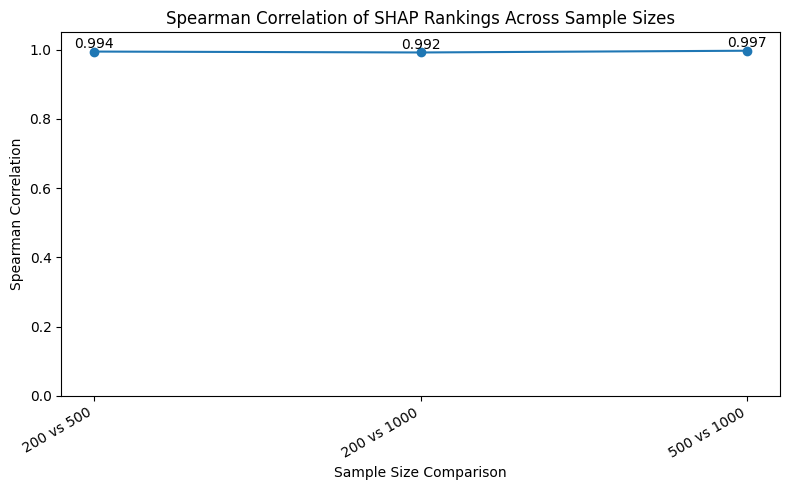

In [77]:
# =========================================================
# STEP 4 - Spearman correlation plot
# =========================================================

required_cols = {"N_a", "N_b", "spearman_top100_union"}
if not required_cols.issubset(stability_df.columns):
    raise ValueError(f"Spearman plot için gerekli kolonlar yok: {required_cols}")

plot_df = stability_df.copy()
plot_df["Comparison"] = plot_df["N_a"].astype(str) + " vs " + plot_df["N_b"].astype(str)

plt.figure(figsize=(8,5))
plt.plot(plot_df["Comparison"], plot_df["spearman_top100_union"], marker="o")
plt.ylim(0, 1.05)
plt.ylabel("Spearman Correlation")
plt.xlabel("Sample Size Comparison")
plt.title("Spearman Correlation of SHAP Rankings Across Sample Sizes")
plt.xticks(rotation=30, ha="right")

for i, v in enumerate(plot_df["spearman_top100_union"]):
    plt.text(i, v + 0.01, f"{v:.3f}", ha="center")

plt.tight_layout()
plt.show()

In [78]:
# =========================================================
# STEP 5 - Feature rank stability plot
# Bu adım için her sample size'a ait feature ranking dosyaları gerekir.
# =========================================================

ranking_candidates = []
for root in SEARCH_DIRS:
    if not root.exists():
        continue
    for path in root.rglob("*.csv"):
        name = path.name.lower()
        if "global_shap" in name and "rank" in name:
            ranking_candidates.append(path)
        elif "shap_importance" in name and "200" in name:
            ranking_candidates.append(path)

print("Possible ranking files:")
for p in ranking_candidates[:20]:
    print(" -", p)

if not ranking_candidates:
    print("\n⚠️ Ayrı ranking dosyaları bulunamadı. Bu yüzden feature rank stability plot şu an üretilemedi.")
    print("Eğer 200/500/1000/1500 için ayrı SHAP importance CSV'lerin varsa onları göster, bu grafiği de kurarız.")

Possible ranking files:
 - C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\global_shap_fixedstep_1500_200\shap_importance_N200.csv
 - C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\CatBoost\cat_global_shap_fixedstep_1500_200\shap_importance_N200.csv
 - C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\DecisionTree\des_global_shap_fixedstep_1500_200\shap_importance_N200.csv
 - C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\ENSEMBLES\EnsembleHard\global_shap_fixedstep_1500_200\shap_importance_N200.csv
 - C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\ENSEMBLES\EnsembleStacking\global_shap_fixedstep_1500_200\shap_importance_N200.csv
 - C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\global_shap_fixedstep_1500_200\shap_importance_N200.csv
 - C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LogReg\global_shap_fixedstep_1500_200\shap_importance_N200.csv
 - C:\User

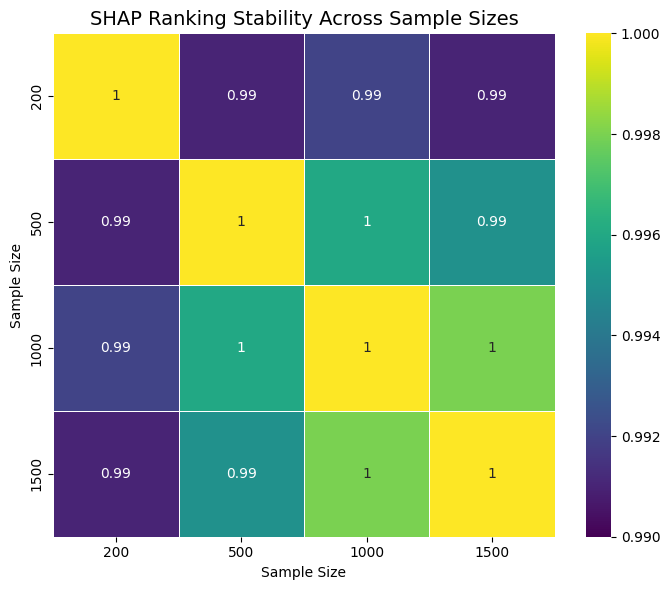

In [79]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Sample size
sizes = [200,500,1000,1500]

# Correlation matrix
corr = [
[1.000,0.991,0.992,0.991],
[0.991,1.000,0.996,0.995],
[0.992,0.996,1.000,0.998],
[0.991,0.995,0.998,1.000]
]

corr_df = pd.DataFrame(corr,index=sizes,columns=sizes)

plt.figure(figsize=(7,6))
sns.heatmap(
    corr_df,
    annot=True,
    cmap="viridis",
    vmin=0.99,
    vmax=1.00,
    linewidths=0.5
)

plt.title("SHAP Ranking Stability Across Sample Sizes",fontsize=14)
plt.xlabel("Sample Size")
plt.ylabel("Sample Size")
plt.tight_layout()
plt.show()

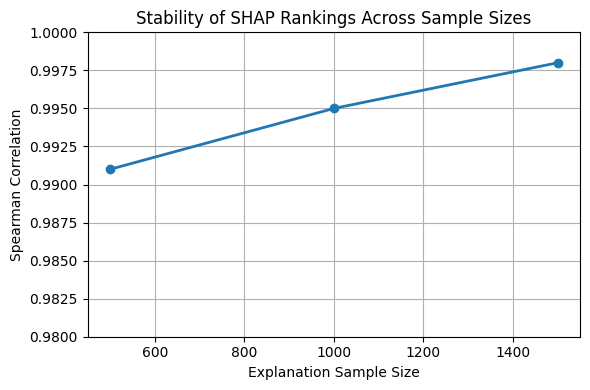

In [80]:
correlation = [0.991,0.995,0.998]

sample_sizes=[500,1000,1500]

plt.figure(figsize=(6,4))

plt.plot(sample_sizes,correlation,marker="o",linewidth=2)

plt.xlabel("Explanation Sample Size")
plt.ylabel("Spearman Correlation")
plt.title("Stability of SHAP Rankings Across Sample Sizes")

plt.ylim(0.98,1.0)

plt.grid(True)

plt.tight_layout()
plt.show()

In [83]:
import pandas as pd

path = r"C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\global_shap_fixedstep_1500_200\shap_importance_N200.csv"

df = pd.read_csv(path)

print(df.columns)
df.head()

Index(['feature', 'mean_abs_shap', 'rank'], dtype='object')


,feature,mean_abs_shap,rank
0,hostname_length,0.088983,1
1,entropy_path,0.062238,2
2,has_www,0.054709,3
3,domain_age_days,0.054396,4
4,uses_https,0.038381,5


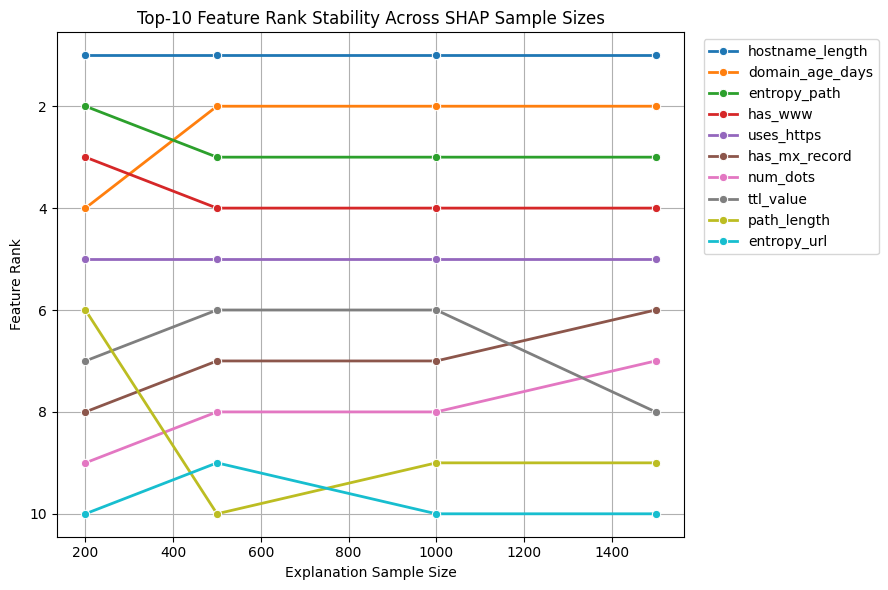

In [84]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

BASE_DIR = r"C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\global_shap_fixedstep_1500_200"

files = {
    200: os.path.join(BASE_DIR,"shap_importance_N200.csv"),
    500: os.path.join(BASE_DIR,"shap_importance_N500.csv"),
    1000: os.path.join(BASE_DIR,"shap_importance_N1000.csv"),
    1500: os.path.join(BASE_DIR,"shap_importance_N1500.csv")
}

dfs = {}

for size,path in files.items():

    df = pd.read_csv(path)

    # importance kolonunu otomatik bul
    importance_col = None

    for c in df.columns:
        if "shap" in c.lower() or "importance" in c.lower():
            importance_col = c
            break

    if importance_col is None:
        raise Exception("Importance column bulunamadı")

    df = df.sort_values(importance_col,ascending=False)

    df["rank"] = range(1,len(df)+1)

    dfs[size] = df


# ----------------------------
# Top 10 features (1500 üzerinden)
# ----------------------------

top_features = dfs[1500].head(10)["feature"].tolist()

records = []

for size,df in dfs.items():

    for f in top_features:

        rank = df.loc[df["feature"]==f,"rank"].values[0]

        records.append({
            "sample_size":size,
            "feature":f,
            "rank":rank
        })

rank_df = pd.DataFrame(records)


# ----------------------------
# Plot
# ----------------------------

plt.figure(figsize=(9,6))

sns.lineplot(
    data=rank_df,
    x="sample_size",
    y="rank",
    hue="feature",
    marker="o",
    linewidth=2
)

plt.gca().invert_yaxis()

plt.title("Top-10 Feature Rank Stability Across SHAP Sample Sizes")

plt.xlabel("Explanation Sample Size")

plt.ylabel("Feature Rank")

plt.legend(bbox_to_anchor=(1.02,1),loc="upper left")

plt.grid(True)

plt.tight_layout()

plt.show()

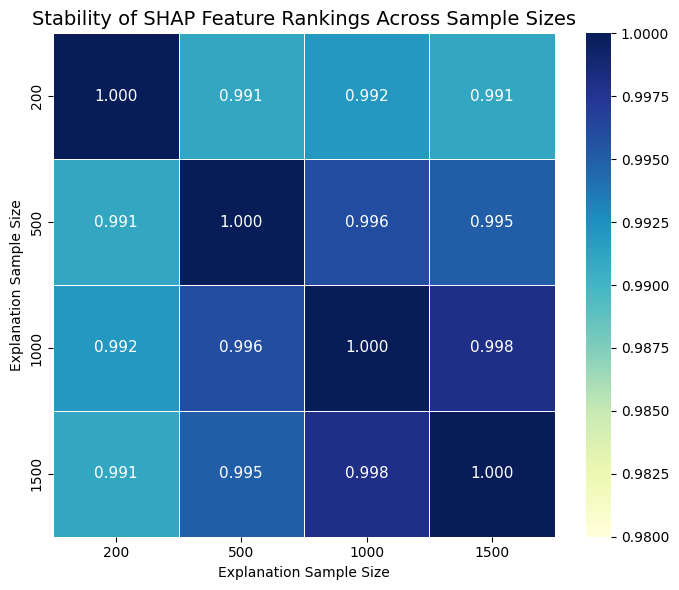

In [85]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sizes = [200,500,1000,1500]

corr = [
[1.000,0.991,0.992,0.991],
[0.991,1.000,0.996,0.995],
[0.992,0.996,1.000,0.998],
[0.991,0.995,0.998,1.000]
]

corr_df = pd.DataFrame(corr,index=sizes,columns=sizes)

plt.figure(figsize=(7,6))

sns.heatmap(
    corr_df,
    annot=True,
    fmt=".3f",          # <-- sayılar düzgün
    cmap="YlGnBu",      # daha akademik renk
    vmin=0.98,
    vmax=1.00,
    linewidths=0.5,
    annot_kws={"size":11}
)

plt.title(
    "Stability of SHAP Feature Rankings Across Sample Sizes",
    fontsize=14
)

plt.xlabel("Explanation Sample Size")
plt.ylabel("Explanation Sample Size")

plt.tight_layout()
plt.show()

In [49]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

# =====================================================
# PATHS
# =====================================================

BASE_DIR = r"C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale"

INC_DIR = os.path.join(
    BASE_DIR,
    "outputs",
    "LightGBM",
    "global_shap_fixedstep_1500_200"
)

FULL_CANDIDATES = [
    os.path.join(BASE_DIR, "outputs", "LightGBM", "global", "shap_importance.csv"),
    os.path.join(BASE_DIR, "outputs", "LightGBM", "global", "global_shap_importance.csv"),
    os.path.join(BASE_DIR, "outputs", "LightGBM", "global", "shap_importance_full.csv"),
]

files = {
    200: os.path.join(INC_DIR, "shap_importance_N200.csv"),
    500: os.path.join(INC_DIR, "shap_importance_N500.csv"),
    1000: os.path.join(INC_DIR, "shap_importance_N1000.csv"),
    1500: os.path.join(INC_DIR, "shap_importance_N1500.csv"),
}

full_path = None
for p in FULL_CANDIDATES:
    if os.path.exists(p):
        full_path = p
        break

if full_path is None:
    raise FileNotFoundError(
        "FULL SHAP importance dosyası bulunamadı.\n"
        "Şu path'leri kontrol ettim:\n" + "\n".join(FULL_CANDIDATES)
    )

print("FULL file found:", full_path)

# =====================================================
# HELPER
# =====================================================

def detect_importance_col(df):
    candidates = [
        "importance",
        "mean_abs_shap",
        "mean_abs_shap_value",
        "importance_mean",
        "mean_shap",
        "shap_importance",
        "mean_abs_value",
    ]
    for c in candidates:
        if c in df.columns:
            return c

    for c in df.columns:
        cl = c.lower()
        if "importance" in cl or "shap" in cl:
            return c

    raise ValueError(f"Importance column bulunamadı. Kolonlar: {list(df.columns)}")

def load_ranked_df(path):
    df = pd.read_csv(path)

    if "feature" not in df.columns:
        raise ValueError(f"'feature' kolonu yok: {path} | kolonlar={list(df.columns)}")

    importance_col = detect_importance_col(df)

    df = df[["feature", importance_col]].copy()
    df.columns = ["feature", "importance"]

    df = df.sort_values("importance", ascending=False).reset_index(drop=True)
    df["rank"] = np.arange(1, len(df) + 1)
    return df

# =====================================================
# LOAD ALL DATA
# =====================================================

dfs = {}

for size, path in files.items():
    if not os.path.exists(path):
        raise FileNotFoundError(f"Dosya bulunamadı: {path}")
    dfs[str(size)] = load_ranked_df(path)

dfs["FULL"] = load_ranked_df(full_path)

print("Loaded datasets:", list(dfs.keys()))
for k, v in dfs.items():
    print(k, v.shape)

# =====================================================
# SAVE DIR
# =====================================================

save_dir = os.path.join(BASE_DIR, "outputs", "LightGBM", "paper_tables")
os.makedirs(save_dir, exist_ok=True)

# =====================================================
# BUILD CORRELATION MATRIX
# =====================================================

labels = ["200", "500", "1000", "1500", "FULL"]
corr_matrix = pd.DataFrame(index=labels, columns=labels, dtype=float)

for a in labels:
    for b in labels:
        merged = pd.merge(
            dfs[a][["feature", "rank"]],
            dfs[b][["feature", "rank"]],
            on="feature",
            suffixes=("_a", "_b")
        )
        rho, _ = spearmanr(merged["rank_a"], merged["rank_b"])
        corr_matrix.loc[a, b] = rho

# =====================================================
# HEATMAP
# =====================================================

plt.figure(figsize=(7.5, 6.5))
sns.heatmap(
    corr_matrix.astype(float),
    annot=True,
    fmt=".3f",
    cmap="YlGnBu",
    vmin=0.98,
    vmax=1.00,
    linewidths=0.6,
    annot_kws={"size": 11}
)

plt.title("Stability of SHAP Feature Rankings Across Sample Sizes", fontsize=14)
plt.xlabel("Explanation Sample Size")
plt.ylabel("Explanation Sample Size")
plt.tight_layout()

heatmap_png = os.path.join(save_dir, "shap_stability_heatmap_with_full.png")
heatmap_pdf = os.path.join(save_dir, "shap_stability_heatmap_with_full.pdf")
plt.savefig(heatmap_png, dpi=300, bbox_inches="tight")
plt.savefig(heatmap_pdf, bbox_inches="tight")
plt.show()
plt.close()

# =====================================================
# TOP-10 FEATURE RANK VS SAMPLE SIZE
# =====================================================

top_features = dfs["FULL"].head(10)["feature"].tolist()

records = []
x_order = ["200", "500", "1000", "1500", "FULL"]

for label in x_order:
    df = dfs[label]
    for feat in top_features:
        rank_val = df.loc[df["feature"] == feat, "rank"].values[0]
        records.append({
            "sample_size": label,
            "feature": feat,
            "rank": rank_val
        })

rank_df = pd.DataFrame(records)

plt.figure(figsize=(10, 6.5))
sns.lineplot(
    data=rank_df,
    x="sample_size",
    y="rank",
    hue="feature",
    marker="o",
    linewidth=2
)

plt.gca().invert_yaxis()
plt.title("Top-10 Feature Rank Stability Across SHAP Sample Sizes", fontsize=14)
plt.xlabel("Explanation Sample Size")
plt.ylabel("Feature Rank")
plt.grid(True, alpha=0.3)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

line_png = os.path.join(save_dir, "top10_rank_stability_with_full.png")
line_pdf = os.path.join(save_dir, "top10_rank_stability_with_full.pdf")
plt.savefig(line_png, dpi=300, bbox_inches="tight")
plt.savefig(line_pdf, bbox_inches="tight")
plt.show()
plt.close()

# =====================================================
# SAVE TABLES
# =====================================================

corr_csv = os.path.join(save_dir, "shap_stability_corr_with_full.csv")
rank_csv = os.path.join(save_dir, "top10_rank_stability_with_full.csv")

corr_matrix.to_csv(corr_csv)
rank_df.to_csv(rank_csv, index=False)

print("Saved files:")
print(corr_csv)
print(rank_csv)
print(heatmap_png)
print(heatmap_pdf)
print(line_png)
print(line_pdf)

FULL file found: C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\global\shap_importance.csv
Loaded datasets: ['200', '500', '1000', '1500', 'FULL']
200 (75, 3)
500 (75, 3)
1000 (75, 3)
1500 (75, 3)
FULL (75, 3)


C:\Users\elifo\AppData\Local\Temp\ipykernel_13684\2772913437.py:155: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Saved files:
C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\paper_tables\shap_stability_corr_with_full.csv
C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\paper_tables\top10_rank_stability_with_full.csv
C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\paper_tables\shap_stability_heatmap_with_full.png
C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\paper_tables\shap_stability_heatmap_with_full.pdf
C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\paper_tables\top10_rank_stability_with_full.png
C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\paper_tables\top10_rank_stability_with_full.pdf


C:\Users\elifo\AppData\Local\Temp\ipykernel_13684\2772913437.py:201: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [88]:
import pandas as pd

shap_path = r"C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\shap_local_v2_400\light_shap_local_long.csv"

lime_path = r"C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\lime_local_v2_400\light_lime_explanations_long.csv"

shap_df = pd.read_csv(shap_path)
lime_df = pd.read_csv(lime_path)

print("SHAP columns:")
print(shap_df.columns)

print("\nLIME columns:")
print(lime_df.columns)

print("\nSHAP sample:")
display(shap_df.head())

SHAP columns:
Index(['model', 'sample_id', 'y_true', 'feature_name', 'shap_value',
       'abs_shap', 'rank', 'explainer'],
      dtype='object')

LIME columns:
Index(['model', 'group', 'sample_id', 'y_true', 'y_pred', 'p_phishing',
       'explained_label', 'feature_idx', 'feature_name', 'weight',
       'abs_weight', 'rank'],
      dtype='object')

SHAP sample:


,model,sample_id,y_true,feature_name,shap_value,abs_shap,rank,explainer
0,LightGBM,87554,1,hostname_length,0.262346,0.262346,1,PermutationExplainer
1,LightGBM,87554,1,entropy_hostname,0.075310,0.075310,2,PermutationExplainer
2,LightGBM,87554,1,uses_https,0.072498,0.072498,3,PermutationExplainer
3,LightGBM,87554,1,entropy_url,0.062336,0.062336,4,PermutationExplainer
4,LightGBM,87554,1,has_www,0.050535,0.050535,5,PermutationExplainer


In [90]:
import pandas as pd

# ---------------------------------------------------
# LOAD
# ---------------------------------------------------
shap_path = r"C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\shap_local_v2_400\light_shap_local_long.csv"
lime_path = r"C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\lime_local_v2_400\light_lime_explanations_long.csv"

shap_df = pd.read_csv(shap_path)
lime_df = pd.read_csv(lime_path)

print("SHAP columns:")
print(list(shap_df.columns))
print("\nLIME columns:")
print(list(lime_df.columns))

display(shap_df.head())

# ---------------------------------------------------
# AUTO-DETECT COLUMNS
# ---------------------------------------------------
def find_first_match(columns, candidates):
    cols_lower = {c.lower(): c for c in columns}
    for cand in candidates:
        if cand.lower() in cols_lower:
            return cols_lower[cand.lower()]
    return None

sample_col = find_first_match(shap_df.columns, [
    "sample_id", "instance_id", "row_id", "id", "sample_index", "idx"
])

true_col = find_first_match(shap_df.columns, [
    "true_label", "y_true", "actual", "label", "target", "true_class"
])

pred_col = find_first_match(shap_df.columns, [
    "pred_label", "y_pred", "prediction", "pred", "predicted_label", "pred_class"
])

prob_col = find_first_match(shap_df.columns, [
    "pred_prob", "y_prob", "probability", "prob", "score", "pred_score", "phishing_prob"
])

print("\nDetected columns:")
print("sample_col =", sample_col)
print("true_col   =", true_col)
print("pred_col   =", pred_col)
print("prob_col   =", prob_col)

if sample_col is None:
    raise ValueError("Sample ID kolonu bulunamadı.")
if true_col is None or pred_col is None:
    raise ValueError(
        "True/pred kolonları otomatik bulunamadı. Yukarıda yazan kolon listesini bana gönder."
    )

# ---------------------------------------------------
# BUILD SAMPLE INFO
# ---------------------------------------------------
use_cols = [sample_col, true_col, pred_col]
if prob_col is not None:
    use_cols.append(prob_col)

sample_info = shap_df[use_cols].drop_duplicates().copy()

print("\nSample info preview:")
display(sample_info.head())

# ---------------------------------------------------
# SELECT EXAMPLES
# ---------------------------------------------------
correct_phish = sample_info[
    (sample_info[true_col] == 1) & (sample_info[pred_col] == 1)
].copy()

correct_legit = sample_info[
    (sample_info[true_col] == 0) & (sample_info[pred_col] == 0)
].copy()

misclassified = sample_info[
    (sample_info[true_col] != sample_info[pred_col])
].copy()

if len(correct_phish) == 0:
    raise ValueError("Doğru phishing örneği bulunamadı.")
if len(correct_legit) == 0:
    raise ValueError("Doğru legitimate örneği bulunamadı.")
if len(misclassified) == 0:
    raise ValueError("Misclassified örnek bulunamadı.")

if prob_col is not None:
    phish_row = correct_phish.sort_values(prob_col, ascending=False).iloc[0]
    legit_row = correct_legit.sort_values(prob_col, ascending=True).iloc[0]
    wrong_row = misclassified.iloc[0]
else:
    phish_row = correct_phish.iloc[0]
    legit_row = correct_legit.iloc[0]
    wrong_row = misclassified.iloc[0]

selected_samples = pd.DataFrame([phish_row, legit_row, wrong_row]).copy()
selected_samples["case_type"] = ["Correct Phishing", "Correct Legitimate", "Misclassified"]

print("\nSelected samples:")
display(selected_samples)

# İleride kullanmak için sample id'leri al
phish_id = phish_row[sample_col]
legit_id = legit_row[sample_col]
wrong_id = wrong_row[sample_col]

print("\nChosen sample IDs:")
print("Phishing sample   =", phish_id)
print("Legitimate sample =", legit_id)
print("Misclassified     =", wrong_id)

SHAP columns:
['model', 'sample_id', 'y_true', 'feature_name', 'shap_value', 'abs_shap', 'rank', 'explainer']

LIME columns:
['model', 'group', 'sample_id', 'y_true', 'y_pred', 'p_phishing', 'explained_label', 'feature_idx', 'feature_name', 'weight', 'abs_weight', 'rank']


,model,sample_id,y_true,feature_name,shap_value,abs_shap,rank,explainer
0,LightGBM,87554,1,hostname_length,0.262346,0.262346,1,PermutationExplainer
1,LightGBM,87554,1,entropy_hostname,0.075310,0.075310,2,PermutationExplainer
2,LightGBM,87554,1,uses_https,0.072498,0.072498,3,PermutationExplainer
3,LightGBM,87554,1,entropy_url,0.062336,0.062336,4,PermutationExplainer
4,LightGBM,87554,1,has_www,0.050535,0.050535,5,PermutationExplainer



Detected columns:
sample_col = sample_id
true_col   = y_true
pred_col   = None
prob_col   = None


ValueError: True/pred kolonları otomatik bulunamadı. Yukarıda yazan kolon listesini bana gönder.

Selected samples:


,sample_id,y_true,y_pred,p_phishing,distance_to_boundary,case_type
300,15209.0,1.0,1.0,1.000000,NaN,Correct Phishing
4170,35208.0,0.0,0.0,0.000027,NaN,Correct Legitimate
10080,94038.0,0.0,1.0,0.504401,0.004401,Misclassified


Phishing sample   = 15209.0
Legitimate sample = 35208.0
Misclassified     = 94038.0


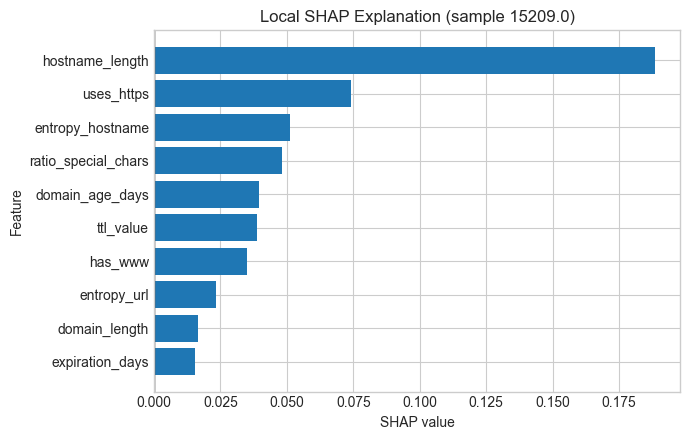

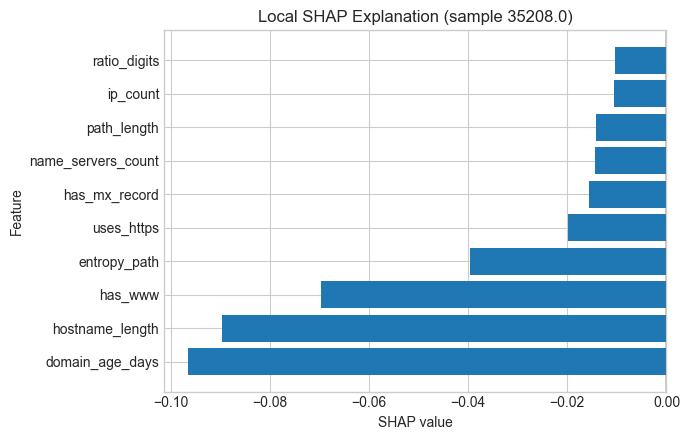

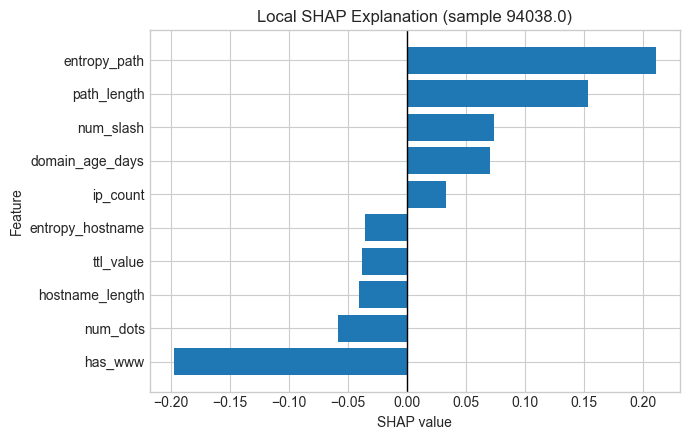

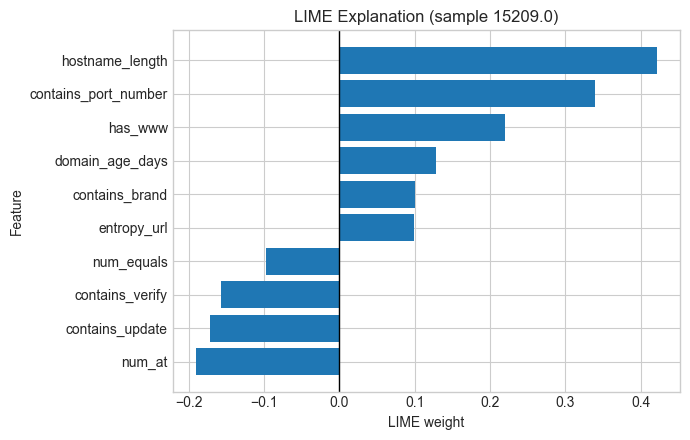

<Figure size 800x500 with 0 Axes>

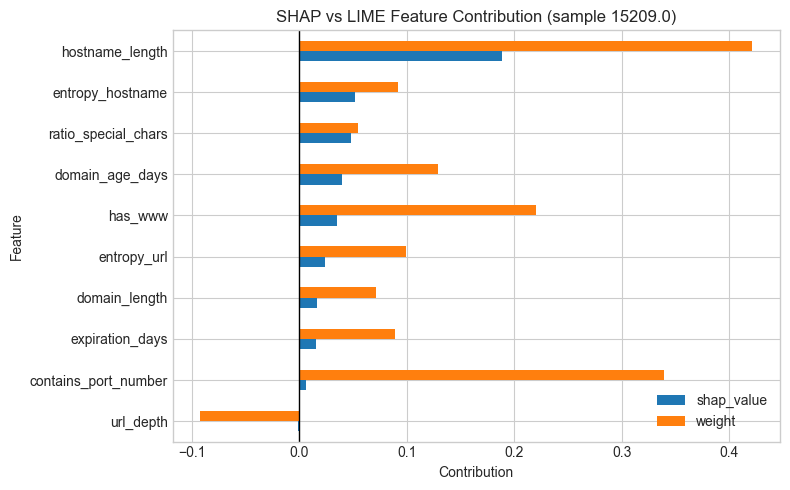

In [91]:
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------
# LOAD
# ---------------------------------------------------
shap_path = r"C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\shap_local_v2_400\light_shap_local_long.csv"
lime_path = r"C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\lime_local_v2_400\light_lime_explanations_long.csv"

shap_df = pd.read_csv(shap_path)
lime_df = pd.read_csv(lime_path)

# ---------------------------------------------------
# SAMPLE SELECTION FROM LIME METADATA
# ---------------------------------------------------
sample_info = lime_df[
    ["sample_id", "y_true", "y_pred", "p_phishing"]
].drop_duplicates().copy()

correct_phish = sample_info[
    (sample_info["y_true"] == 1) & (sample_info["y_pred"] == 1)
].copy()

correct_legit = sample_info[
    (sample_info["y_true"] == 0) & (sample_info["y_pred"] == 0)
].copy()

misclassified = sample_info[
    (sample_info["y_true"] != sample_info["y_pred"])
].copy()

if len(correct_phish) == 0:
    raise ValueError("Doğru phishing örneği bulunamadı.")
if len(correct_legit) == 0:
    raise ValueError("Doğru legitimate örneği bulunamadı.")
if len(misclassified) == 0:
    raise ValueError("Misclassified örnek bulunamadı.")

# En temsil edici örnekleri seç
phish_row = correct_phish.sort_values("p_phishing", ascending=False).iloc[0]
legit_row = correct_legit.sort_values("p_phishing", ascending=True).iloc[0]

# Yanlış örnek için sınıra yakın olanı seçmek daha iyi
misclassified["distance_to_boundary"] = (misclassified["p_phishing"] - 0.5).abs()
wrong_row = misclassified.sort_values("distance_to_boundary", ascending=True).iloc[0]

phish_id = phish_row["sample_id"]
legit_id = legit_row["sample_id"]
wrong_id = wrong_row["sample_id"]

selected_samples = pd.DataFrame([phish_row, legit_row, wrong_row]).copy()
selected_samples["case_type"] = ["Correct Phishing", "Correct Legitimate", "Misclassified"]

print("Selected samples:")
display(selected_samples)

print("Phishing sample   =", phish_id)
print("Legitimate sample =", legit_id)
print("Misclassified     =", wrong_id)

# ---------------------------------------------------
# PLOTTING HELPERS
# ---------------------------------------------------
plt.style.use("seaborn-v0_8-whitegrid")

def plot_local_shap(sample_id, top_n=10):
    df = shap_df[shap_df["sample_id"] == sample_id].copy()
    if df.empty:
        raise ValueError(f"SHAP data not found for sample_id={sample_id}")

    df = df.sort_values("abs_shap", ascending=False).head(top_n)
    df = df.sort_values("shap_value", ascending=True)

    plt.figure(figsize=(7, 4.5))
    plt.barh(df["feature_name"], df["shap_value"])
    plt.axvline(0, color="black", linewidth=1)
    plt.xlabel("SHAP value")
    plt.ylabel("Feature")
    plt.title(f"Local SHAP Explanation (sample {sample_id})")
    plt.tight_layout()
    plt.show()

def plot_local_lime(sample_id, top_n=10):
    df = lime_df[lime_df["sample_id"] == sample_id].copy()
    if df.empty:
        raise ValueError(f"LIME data not found for sample_id={sample_id}")

    df = df.sort_values("abs_weight", ascending=False).head(top_n)
    df = df.sort_values("weight", ascending=True)

    plt.figure(figsize=(7, 4.5))
    plt.barh(df["feature_name"], df["weight"])
    plt.axvline(0, color="black", linewidth=1)
    plt.xlabel("LIME weight")
    plt.ylabel("Feature")
    plt.title(f"LIME Explanation (sample {sample_id})")
    plt.tight_layout()
    plt.show()

def compare_shap_lime(sample_id, top_n=10):
    shap_local = shap_df[shap_df["sample_id"] == sample_id][
        ["feature_name", "shap_value", "abs_shap"]
    ].copy()

    lime_local = lime_df[lime_df["sample_id"] == sample_id][
        ["feature_name", "weight", "abs_weight"]
    ].copy()

    merged = pd.merge(shap_local, lime_local, on="feature_name", how="inner")

    if merged.empty:
        raise ValueError(f"SHAP-LIME merge failed for sample_id={sample_id}")

    merged["combined_score"] = merged["abs_shap"] + merged["abs_weight"]
    merged = merged.sort_values("combined_score", ascending=False).head(top_n)
    merged = merged.sort_values("shap_value", ascending=True)

    plot_df = merged.set_index("feature_name")[["shap_value", "weight"]]

    plt.figure(figsize=(8, 5))
    plot_df.plot.barh(figsize=(8, 5))
    plt.axvline(0, color="black", linewidth=1)
    plt.xlabel("Contribution")
    plt.ylabel("Feature")
    plt.title(f"SHAP vs LIME Feature Contribution (sample {sample_id})")
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------
# GENERATE FIGURES
# ---------------------------------------------------
plot_local_shap(phish_id)
plot_local_shap(legit_id)
plot_local_shap(wrong_id)

plot_local_lime(phish_id)
compare_shap_lime(phish_id)

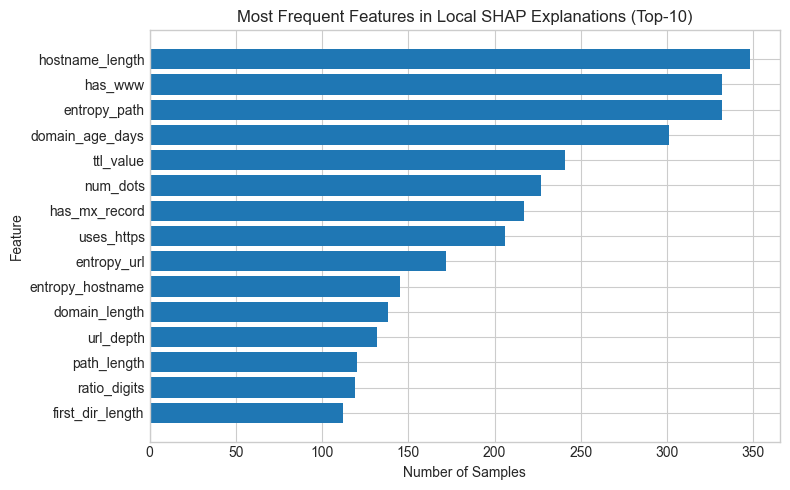

In [92]:
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------
# LOAD
# ---------------------------------------------------
shap_path = r"C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\shap_local_v2_400\light_shap_local_long.csv"
lime_path = r"C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\lime_local_v2_400\light_lime_explanations_long.csv"

shap_df = pd.read_csv(shap_path)
lime_df = pd.read_csv(lime_path)

plt.style.use("seaborn-v0_8-whitegrid")

# ---------------------------------------------------
# SHAP: top-k frequency
# ---------------------------------------------------
TOP_K = 10

shap_top = shap_df[shap_df["rank"] <= TOP_K].copy()

shap_freq = (
    shap_top.groupby("feature_name")["sample_id"]
    .nunique()
    .sort_values(ascending=False)
    .head(15)
    .reset_index()
)

shap_freq.columns = ["feature_name", "sample_count"]

plt.figure(figsize=(8, 5))
plt.barh(shap_freq["feature_name"], shap_freq["sample_count"])
plt.gca().invert_yaxis()
plt.xlabel("Number of Samples")
plt.ylabel("Feature")
plt.title(f"Most Frequent Features in Local SHAP Explanations (Top-{TOP_K})")
plt.tight_layout()
plt.show()

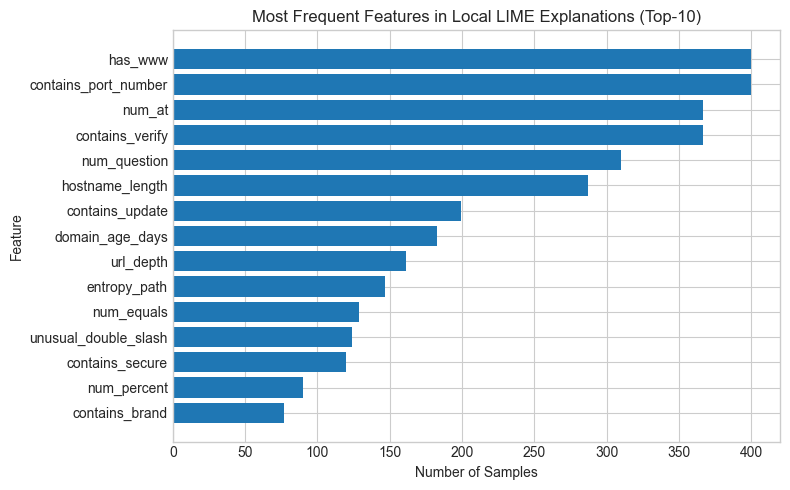

In [93]:
# ---------------------------------------------------
# LIME: top-k frequency
# ---------------------------------------------------
TOP_K = 10

lime_top = lime_df[lime_df["rank"] <= TOP_K].copy()

lime_freq = (
    lime_top.groupby("feature_name")["sample_id"]
    .nunique()
    .sort_values(ascending=False)
    .head(15)
    .reset_index()
)

lime_freq.columns = ["feature_name", "sample_count"]

plt.figure(figsize=(8, 5))
plt.barh(lime_freq["feature_name"], lime_freq["sample_count"])
plt.gca().invert_yaxis()
plt.xlabel("Number of Samples")
plt.ylabel("Feature")
plt.title(f"Most Frequent Features in Local LIME Explanations (Top-{TOP_K})")
plt.tight_layout()
plt.show()

<Figure size 900x500 with 0 Axes>

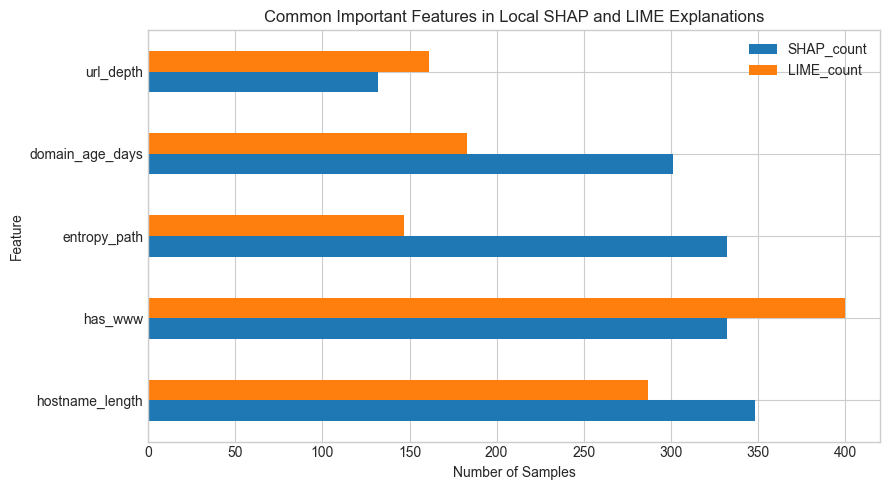

Common features:
['domain_age_days', 'entropy_path', 'has_www', 'hostname_length', 'url_depth']


In [94]:
# ---------------------------------------------------
# SHAP vs LIME overlap
# ---------------------------------------------------
shap_top_features = set(shap_freq["feature_name"])
lime_top_features = set(lime_freq["feature_name"])

common_features = sorted(list(shap_top_features & lime_top_features))

overlap_df = pd.merge(
    shap_freq.rename(columns={"sample_count": "SHAP_count"}),
    lime_freq.rename(columns={"sample_count": "LIME_count"}),
    on="feature_name",
    how="inner"
)

overlap_df = overlap_df.sort_values(
    by=["SHAP_count", "LIME_count"],
    ascending=False
).head(15)

plot_df = overlap_df.set_index("feature_name")[["SHAP_count", "LIME_count"]]

plt.figure(figsize=(9, 5))
plot_df.plot.barh(figsize=(9, 5))
plt.xlabel("Number of Samples")
plt.ylabel("Feature")
plt.title("Common Important Features in Local SHAP and LIME Explanations")
plt.tight_layout()
plt.show()

print("Common features:")
print(common_features)

In [95]:
overlap_table = overlap_df.copy()
overlap_table.columns = ["Feature", "SHAP Sample Count", "LIME Sample Count"]
overlap_table

,Feature,SHAP Sample Count,LIME Sample Count
0,hostname_length,348,287
1,has_www,332,400
2,entropy_path,332,147
3,domain_age_days,301,183
4,url_depth,132,161


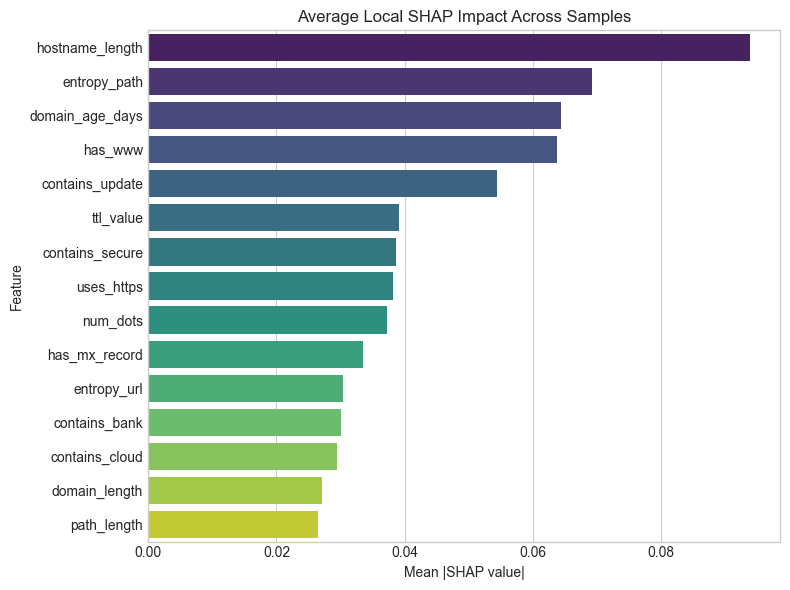

In [96]:
import seaborn as sns
import matplotlib.pyplot as plt

shap_imp = (
    shap_df.groupby("feature_name")["abs_shap"]
    .mean()
    .sort_values(ascending=False)
    .head(15)
    .reset_index()
)

plt.figure(figsize=(8,6))

sns.barplot(
    data=shap_imp,
    y="feature_name",
    x="abs_shap",
    palette="viridis"
)

plt.xlabel("Mean |SHAP value|")
plt.ylabel("Feature")
plt.title("Average Local SHAP Impact Across Samples")

plt.tight_layout()
plt.show()

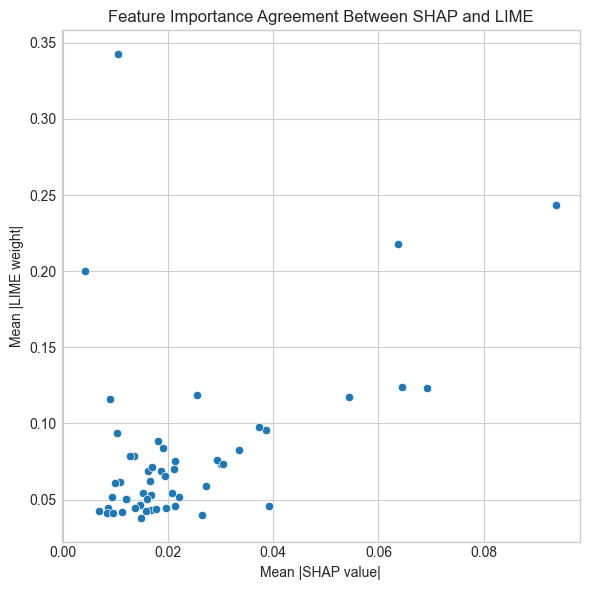

In [97]:
shap_imp = shap_df.groupby("feature_name")["abs_shap"].mean()
lime_imp = lime_df.groupby("feature_name")["abs_weight"].mean()

compare = pd.concat([shap_imp,lime_imp],axis=1)
compare.columns=["SHAP","LIME"]
compare=compare.dropna()

plt.figure(figsize=(6,6))

sns.scatterplot(
    data=compare,
    x="SHAP",
    y="LIME"
)

plt.xlabel("Mean |SHAP value|")
plt.ylabel("Mean |LIME weight|")

plt.title("Feature Importance Agreement Between SHAP and LIME")

plt.tight_layout()
plt.show()

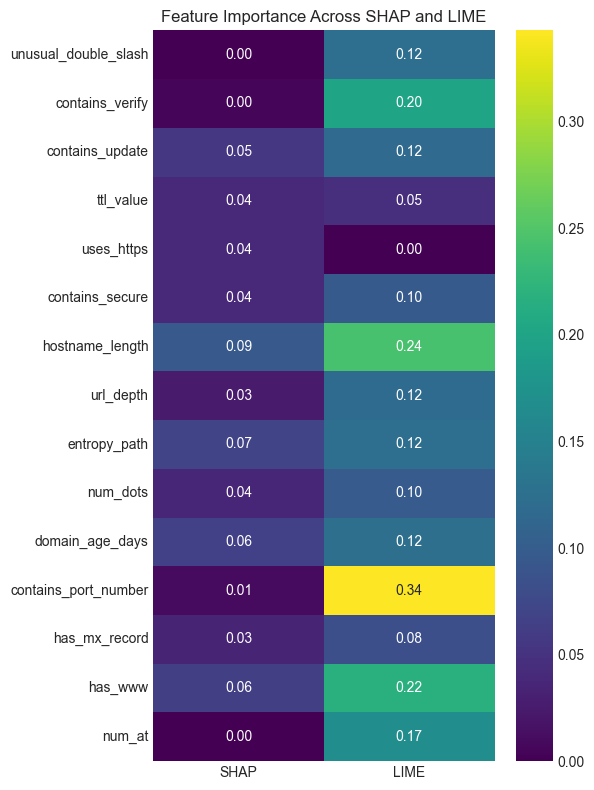

In [98]:
top_shap = shap_imp.sort_values(ascending=False).head(10).index
top_lime = lime_imp.sort_values(ascending=False).head(10).index

features = list(set(top_shap)|set(top_lime))

heat_df = pd.DataFrame(index=features,columns=["SHAP","LIME"])

heat_df["SHAP"]=shap_imp
heat_df["LIME"]=lime_imp

heat_df=heat_df.fillna(0)

plt.figure(figsize=(6,8))

sns.heatmap(
    heat_df,
    cmap="viridis",
    annot=True,
    fmt=".2f"
)

plt.title("Feature Importance Across SHAP and LIME")

plt.tight_layout()
plt.show()

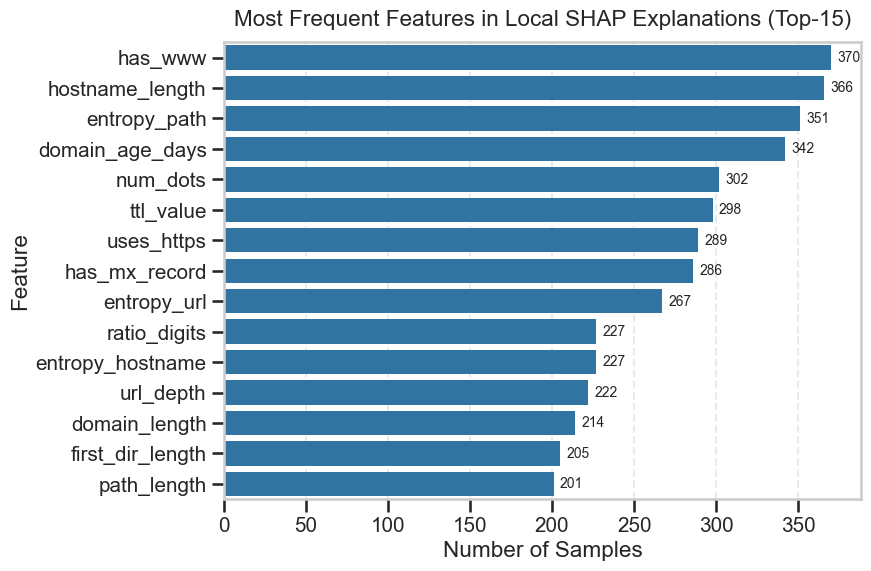

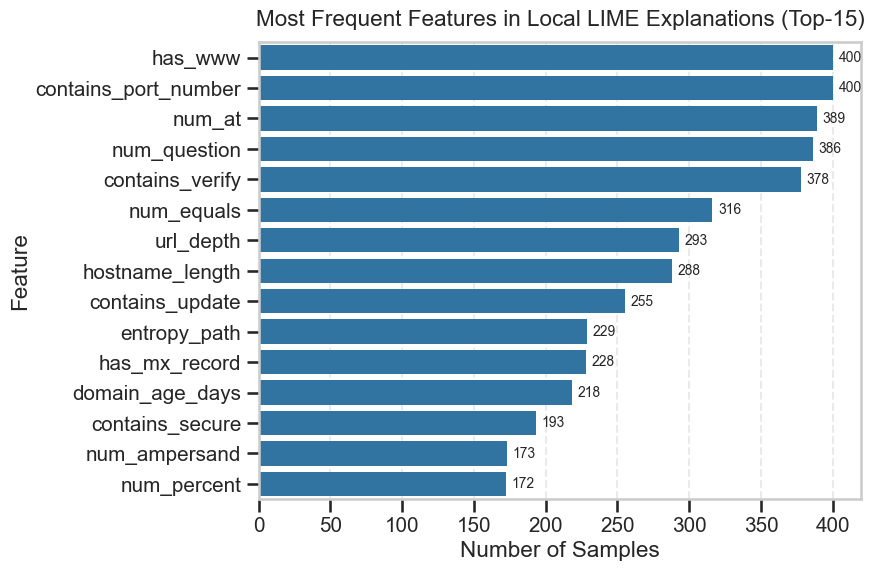

In [102]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ---------------------------------------------------
# LOAD
# ---------------------------------------------------
shap_path = r"C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\shap_local_v2_400\light_shap_local_long.csv"
lime_path = r"C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\lime_local_v2_400\light_lime_explanations_long.csv"

shap_df = pd.read_csv(shap_path)
lime_df = pd.read_csv(lime_path)

plt.style.use("seaborn-v0_8-whitegrid")
sns.set_context("talk", font_scale=0.9)

TOP_K = 15
TOP_N_SHOW = 15

# ---------------------------------------------------
# SHAP frequency
# ---------------------------------------------------
shap_top = shap_df[shap_df["rank"] <= TOP_K].copy()

shap_freq = (
    shap_top.groupby("feature_name")["sample_id"]
    .nunique()
    .sort_values(ascending=False)
    .head(TOP_N_SHOW)
    .reset_index()
)

shap_freq.columns = ["feature_name", "sample_count"]

plt.figure(figsize=(9, 6))
ax = sns.barplot(
    data=shap_freq,
    y="feature_name",
    x="sample_count"
)

ax.set_title(f"Most Frequent Features in Local SHAP Explanations (Top-{TOP_K})", pad=12)
ax.set_xlabel("Number of Samples")
ax.set_ylabel("Feature")

# sayı yaz
max_val = shap_freq["sample_count"].max()
for i, v in enumerate(shap_freq["sample_count"]):
    ax.text(v + max_val * 0.01, i, str(v), va="center", fontsize=10)

ax.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# ---------------------------------------------------
# LIME frequency
# ---------------------------------------------------
lime_top = lime_df[lime_df["rank"] <= TOP_K].copy()

lime_freq = (
    lime_top.groupby("feature_name")["sample_id"]
    .nunique()
    .sort_values(ascending=False)
    .head(TOP_N_SHOW)
    .reset_index()
)

lime_freq.columns = ["feature_name", "sample_count"]

plt.figure(figsize=(9, 6))
ax = sns.barplot(
    data=lime_freq,
    y="feature_name",
    x="sample_count"
)

ax.set_title(f"Most Frequent Features in Local LIME Explanations (Top-{TOP_K})", pad=12)
ax.set_xlabel("Number of Samples")
ax.set_ylabel("Feature")

max_val = lime_freq["sample_count"].max()
for i, v in enumerate(lime_freq["sample_count"]):
    ax.text(v + max_val * 0.01, i, str(v), va="center", fontsize=10)

ax.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

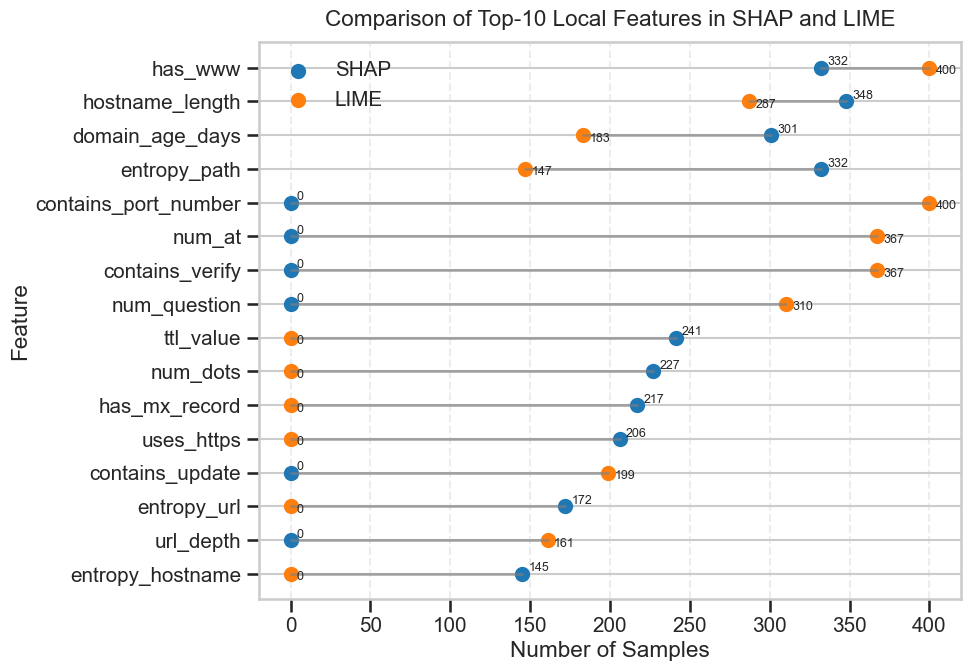

In [100]:
import pandas as pd
import matplotlib.pyplot as plt

# SHAP ve LIME top-10 feature frekansları
shap_top10 = (
    shap_df[shap_df["rank"] <= 10]
    .groupby("feature_name")["sample_id"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

lime_top10 = (
    lime_df[lime_df["rank"] <= 10]
    .groupby("feature_name")["sample_id"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

# birleşik feature kümesi
features_union = sorted(set(shap_top10.index).union(set(lime_top10.index)))

compare_df = pd.DataFrame({"feature_name": features_union})
compare_df["SHAP_count"] = compare_df["feature_name"].map(shap_top10).fillna(0)
compare_df["LIME_count"] = compare_df["feature_name"].map(lime_top10).fillna(0)

# daha okunaklı sıralama: ortalama büyüklüğe göre
compare_df["avg_count"] = (compare_df["SHAP_count"] + compare_df["LIME_count"]) / 2
compare_df = compare_df.sort_values("avg_count", ascending=True).reset_index(drop=True)

plt.figure(figsize=(10, 7))

y_positions = range(len(compare_df))

# çizgiler
for i, row in compare_df.iterrows():
    plt.plot(
        [row["SHAP_count"], row["LIME_count"]],
        [i, i],
        color="gray",
        alpha=0.6,
        linewidth=2
    )

# noktalar
plt.scatter(compare_df["SHAP_count"], y_positions, s=90, label="SHAP")
plt.scatter(compare_df["LIME_count"], y_positions, s=90, label="LIME")

# eksenler
plt.yticks(y_positions, compare_df["feature_name"])
plt.xlabel("Number of Samples")
plt.ylabel("Feature")
plt.title("Comparison of Top-10 Local Features in SHAP and LIME", pad=12)

# sayı etiketleri
xmax = max(compare_df["SHAP_count"].max(), compare_df["LIME_count"].max())
for i, row in compare_df.iterrows():
    plt.text(row["SHAP_count"] + xmax * 0.01, i + 0.08, int(row["SHAP_count"]), fontsize=9)
    plt.text(row["LIME_count"] + xmax * 0.01, i - 0.18, int(row["LIME_count"]), fontsize=9)

plt.grid(axis="x", linestyle="--", alpha=0.35)
plt.legend()
plt.tight_layout()
plt.show()

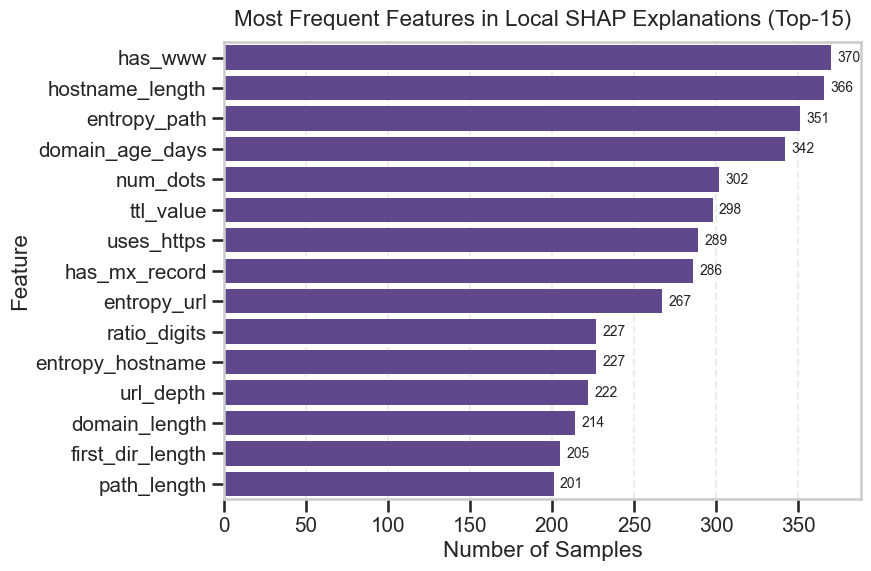

In [104]:
plt.figure(figsize=(9,6))

ax = sns.barplot(
    data=shap_freq,
    y="feature_name",
    x="sample_count",
    color="#5E3C99"   # deep purple
)

ax.set_title(
    f"Most Frequent Features in Local SHAP Explanations (Top-{TOP_K})",
    pad=12
)

ax.set_xlabel("Number of Samples")
ax.set_ylabel("Feature")

max_val = shap_freq["sample_count"].max()

for i,v in enumerate(shap_freq["sample_count"]):
    ax.text(
        v + max_val*0.01,
        i,
        str(v),
        va="center",
        fontsize=10
    )

ax.grid(axis="x", linestyle="--", alpha=0.35)

plt.tight_layout()
plt.show()

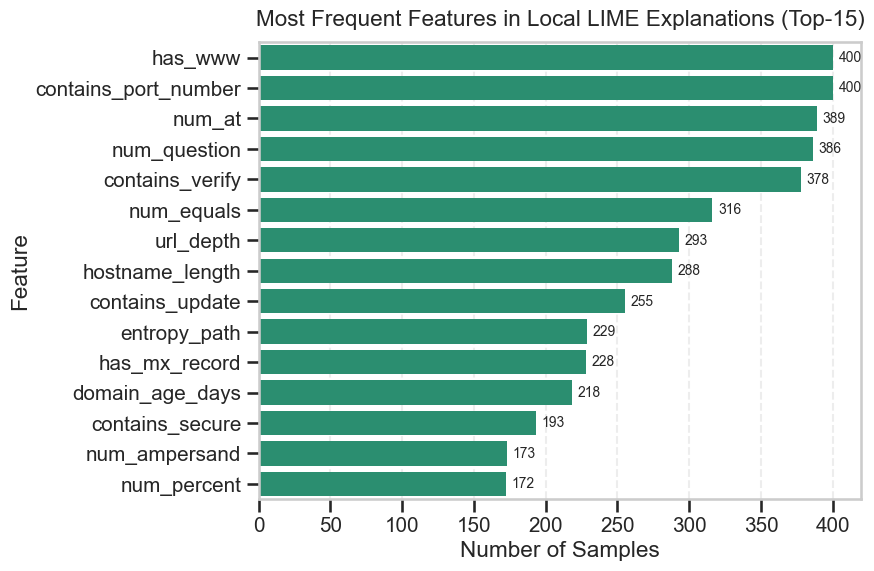

In [105]:
plt.figure(figsize=(9,6))

ax = sns.barplot(
    data=lime_freq,
    y="feature_name",
    x="sample_count",
    color="#1B9E77"   # emerald teal
)

ax.set_title(
    f"Most Frequent Features in Local LIME Explanations (Top-{TOP_K})",
    pad=12
)

ax.set_xlabel("Number of Samples")
ax.set_ylabel("Feature")

max_val = lime_freq["sample_count"].max()

for i,v in enumerate(lime_freq["sample_count"]):
    ax.text(
        v + max_val*0.01,
        i,
        str(v),
        va="center",
        fontsize=10
    )

ax.grid(axis="x", linestyle="--", alpha=0.35)

plt.tight_layout()
plt.show()

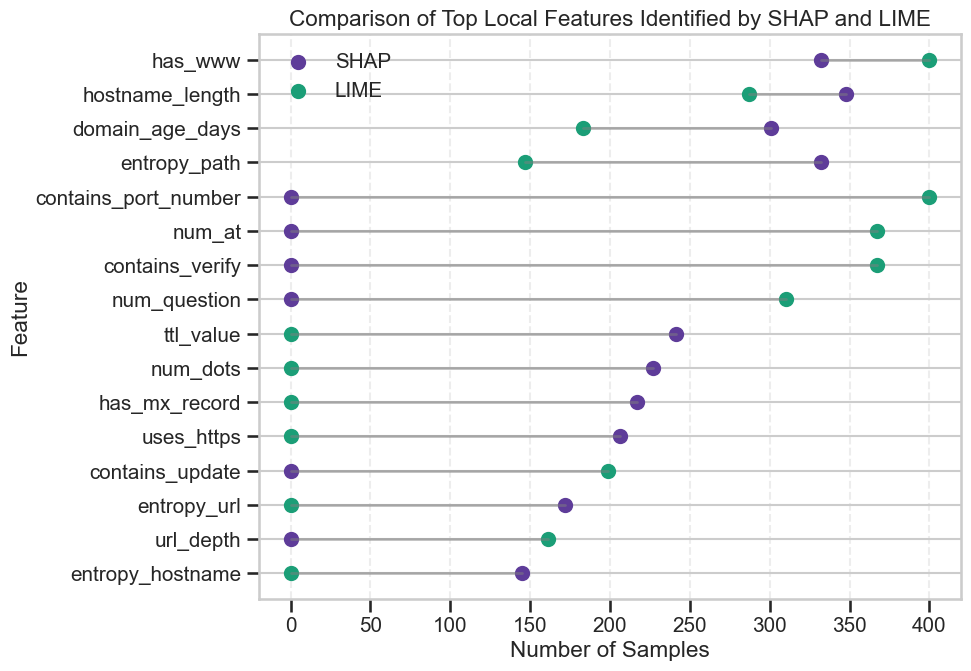

In [106]:
plt.figure(figsize=(10,7))

for i,row in compare_df.iterrows():

    plt.plot(
        [row["SHAP_count"], row["LIME_count"]],
        [i,i],
        color="gray",
        alpha=0.5,
        linewidth=2
    )

plt.scatter(
    compare_df["SHAP_count"],
    range(len(compare_df)),
    s=90,
    color="#5E3C99",
    label="SHAP"
)

plt.scatter(
    compare_df["LIME_count"],
    range(len(compare_df)),
    s=90,
    color="#1B9E77",
    label="LIME"
)

plt.yticks(range(len(compare_df)), compare_df["feature_name"])

plt.xlabel("Number of Samples")
plt.ylabel("Feature")

plt.title("Comparison of Top Local Features Identified by SHAP and LIME")

plt.grid(axis="x", linestyle="--", alpha=0.35)

plt.legend()

plt.tight_layout()
plt.show()

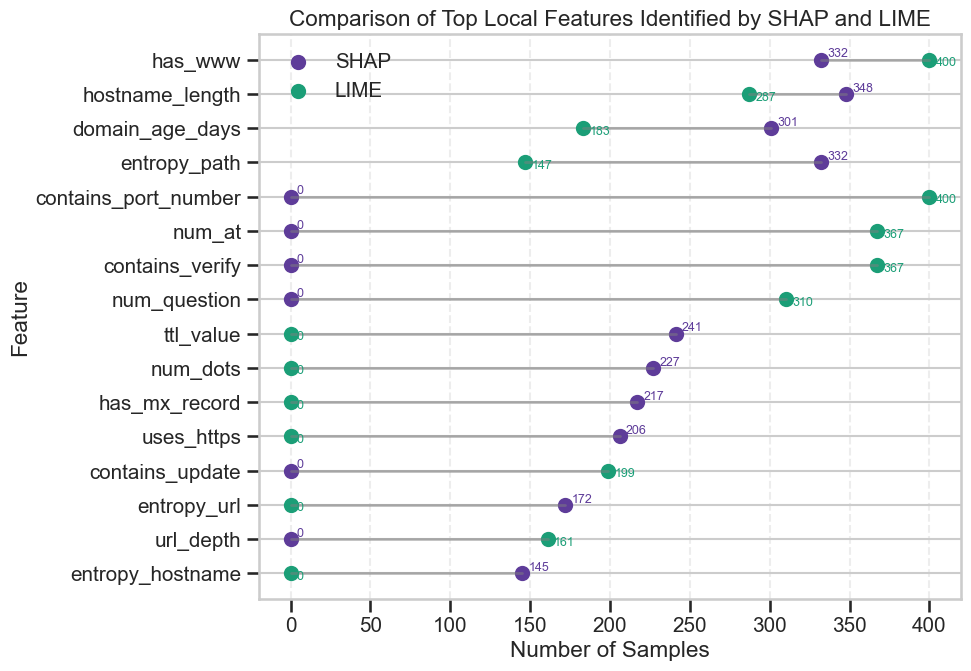

In [107]:
plt.figure(figsize=(10,7))

y_positions = range(len(compare_df))

# bağlantı çizgileri
for i,row in compare_df.iterrows():

    plt.plot(
        [row["SHAP_count"], row["LIME_count"]],
        [i,i],
        color="gray",
        alpha=0.5,
        linewidth=2
    )

# SHAP noktaları
plt.scatter(
    compare_df["SHAP_count"],
    y_positions,
    s=90,
    color="#5E3C99",
    label="SHAP"
)

# LIME noktaları
plt.scatter(
    compare_df["LIME_count"],
    y_positions,
    s=90,
    color="#1B9E77",
    label="LIME"
)

# feature isimleri
plt.yticks(y_positions, compare_df["feature_name"])

plt.xlabel("Number of Samples")
plt.ylabel("Feature")

plt.title("Comparison of Top Local Features Identified by SHAP and LIME")

# -------------------------------------------------
# SAYILARI YAZ
# -------------------------------------------------

xmax = max(compare_df["SHAP_count"].max(), compare_df["LIME_count"].max())

for i,row in compare_df.iterrows():

    # SHAP sayısı
    plt.text(
        row["SHAP_count"] + xmax*0.01,
        i + 0.08,
        int(row["SHAP_count"]),
        fontsize=9,
        color="#5E3C99"
    )

    # LIME sayısı
    plt.text(
        row["LIME_count"] + xmax*0.01,
        i - 0.18,
        int(row["LIME_count"]),
        fontsize=9,
        color="#1B9E77"
    )

plt.grid(axis="x", linestyle="--", alpha=0.35)

plt.legend()

plt.tight_layout()
plt.show()

Dropped object columns: ['url']
Prediction shape: (115984, 75)
type
Correct           113208
False Negative      1637
False Positive      1139
Name: count, dtype: int64


,False Positive,False Negative,Correct
domain_age_days,2772.668130,3332.724496,4478.505220
ttl_value,3253.225637,4023.734270,2513.936939
expiration_days,353.980685,345.093464,464.384063
creation_year,1596.375768,1657.477092,1554.666472
query_length,9.392450,7.861943,5.317663
hostname_length,17.230904,14.888210,18.832459
url_length,52.432836,49.172877,51.559466
path_length,17.444249,18.256567,19.312999
num_letters,38.591747,36.894319,39.140087
first_dir_length,5.176471,7.020770,7.398762


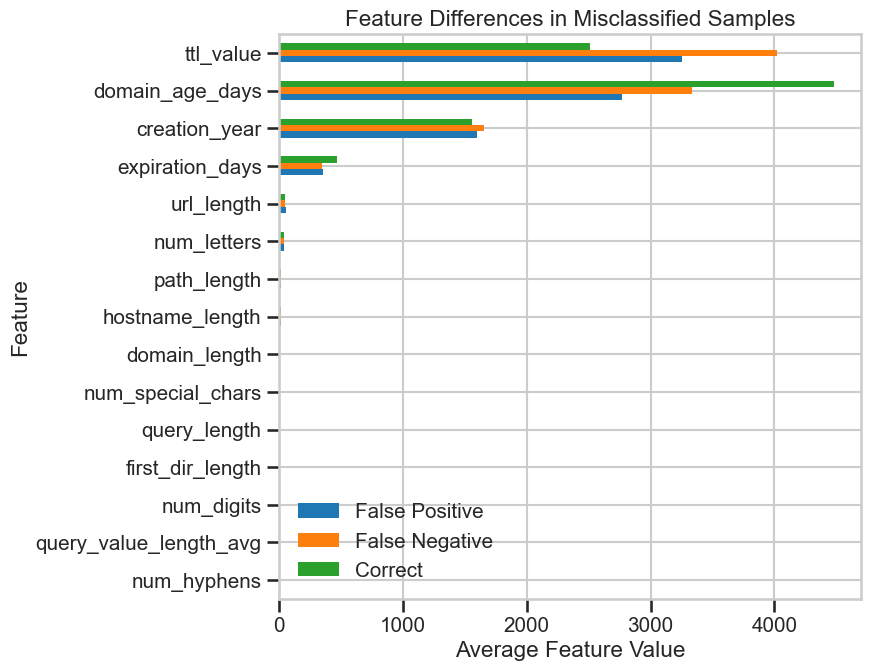

In [110]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1) X_test'i prediction için temizle
# --------------------------------------------------
X_pred = X_test.copy()

# object/string kolonları at
bad_cols = X_pred.select_dtypes(include=["object"]).columns.tolist()
print("Dropped object columns:", bad_cols)

X_pred = X_pred.drop(columns=bad_cols, errors="ignore")

# indexleri sıfırla  <<< KRİTİK
X_pred = X_pred.reset_index(drop=True)
y_true = pd.Series(y_test).reset_index(drop=True)

# modelin feature isimlerine hizala
if hasattr(model, "feature_name_") and model.feature_name_ is not None:
    train_features = list(model.feature_name_)
    missing_cols = [c for c in train_features if c not in X_pred.columns]
    extra_cols   = [c for c in X_pred.columns if c not in train_features]

    if missing_cols:
        raise ValueError(f"X_test içinde modelin beklediği kolonlar eksik: {missing_cols}")

    if extra_cols:
        print("Extra columns removed:", extra_cols)

    X_pred = X_pred[train_features]

print("Prediction shape:", X_pred.shape)

# --------------------------------------------------
# 2) Prediction
# --------------------------------------------------
y_prob = model.predict_proba(X_pred)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)

results = pd.DataFrame({
    "y_true": y_true,
    "y_pred": y_pred,
    "p_phishing": y_prob
})

results["type"] = "Correct"
results.loc[(results["y_true"] == 0) & (results["y_pred"] == 1), "type"] = "False Positive"
results.loc[(results["y_true"] == 1) & (results["y_pred"] == 0), "type"] = "False Negative"

print(results["type"].value_counts())

# --------------------------------------------------
# 3) FP / FN / Correct indexleri
# --------------------------------------------------
fp_idx = results.index[results["type"] == "False Positive"]
fn_idx = results.index[results["type"] == "False Negative"]
correct_idx = results.index[results["type"] == "Correct"]

# --------------------------------------------------
# 4) Feature ortalama karşılaştırması
# --------------------------------------------------
fp_mean = X_pred.iloc[fp_idx].mean()
fn_mean = X_pred.iloc[fn_idx].mean()
correct_mean = X_pred.iloc[correct_idx].mean()

compare_df = pd.DataFrame({
    "False Positive": fp_mean,
    "False Negative": fn_mean,
    "Correct": correct_mean
})

# en çok ayrışan feature'lar
compare_df["FP_vs_Correct_absdiff"] = (compare_df["False Positive"] - compare_df["Correct"]).abs()
compare_df["FN_vs_Correct_absdiff"] = (compare_df["False Negative"] - compare_df["Correct"]).abs()
compare_df["Total_diff"] = compare_df["FP_vs_Correct_absdiff"] + compare_df["FN_vs_Correct_absdiff"]

misclf_top = compare_df.sort_values("Total_diff", ascending=False).head(15)

display(misclf_top[["False Positive", "False Negative", "Correct"]])

# --------------------------------------------------
# 5) Grafik
# --------------------------------------------------
plot_df = misclf_top[["False Positive", "False Negative", "Correct"]].sort_values(
    "False Negative", ascending=True
)

plot_df.plot(kind="barh", figsize=(9, 7))
plt.title("Feature Differences in Misclassified Samples")
plt.xlabel("Average Feature Value")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [111]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# -------------------------------------------------
# RESULTS DATAFRAME
# -------------------------------------------------

results = pd.DataFrame()
results["y_true"] = y_test
results["y_pred"] = y_pred

conditions = [
    (results.y_true == 0) & (results.y_pred == 1),
    (results.y_true == 1) & (results.y_pred == 0)
]

choices = ["False Positive", "False Negative"]

results["type"] = np.select(conditions, choices, default="Correct")

# index reset (çok önemli)
results = results.reset_index(drop=True)
X_pred = X_pred.reset_index(drop=True)

data = pd.concat([results["type"], X_pred], axis=1)

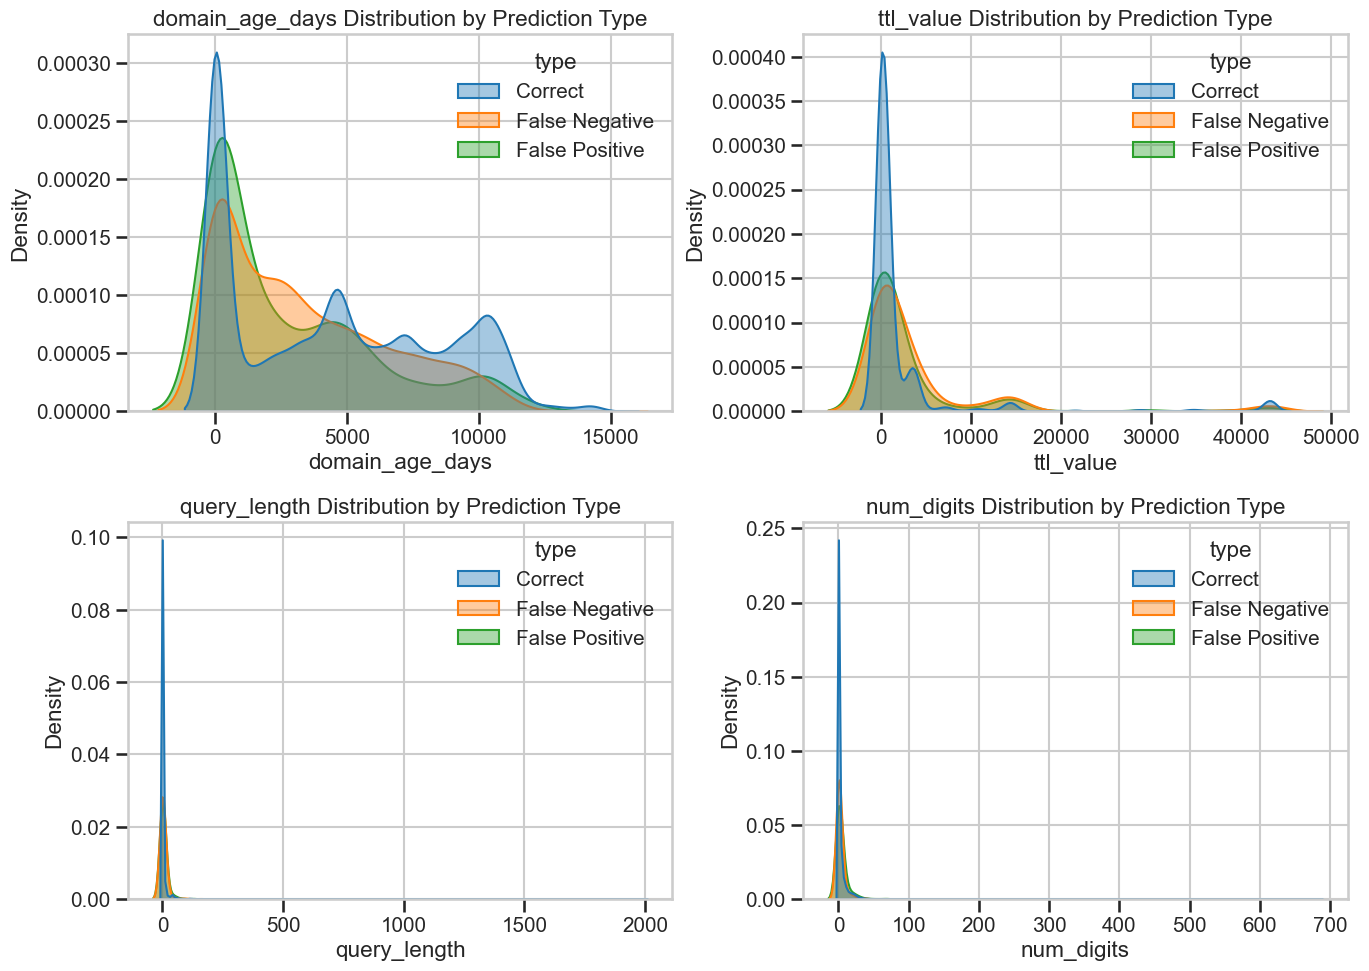

In [112]:
features = [
    "domain_age_days",
    "ttl_value",
    "query_length",
    "num_digits"
]

plt.figure(figsize=(14,10))

for i, feature in enumerate(features):

    plt.subplot(2,2,i+1)

    sns.kdeplot(
        data=data,
        x=feature,
        hue="type",
        fill=True,
        common_norm=False,
        alpha=0.4
    )

    plt.title(f"{feature} Distribution by Prediction Type")
    plt.xlabel(feature)
    plt.ylabel("Density")

plt.tight_layout()
plt.show()

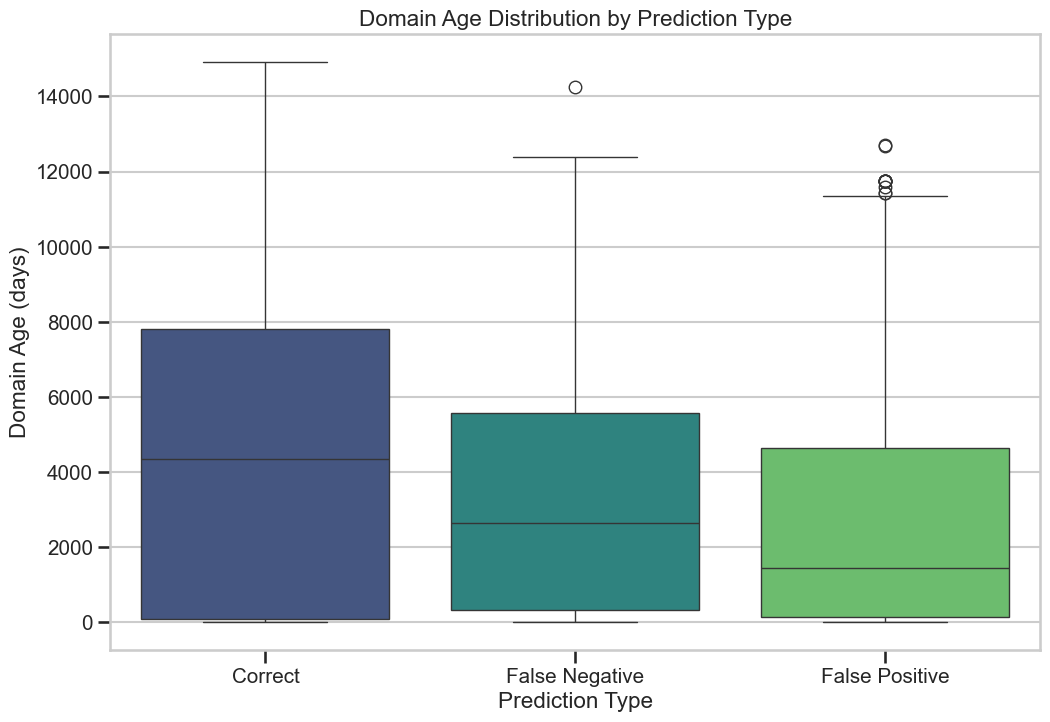

In [113]:
plt.figure(figsize=(12,8))

sns.boxplot(
    data=data,
    x="type",
    y="domain_age_days",
    palette="viridis"
)

plt.title("Domain Age Distribution by Prediction Type")
plt.xlabel("Prediction Type")
plt.ylabel("Domain Age (days)")

plt.show()

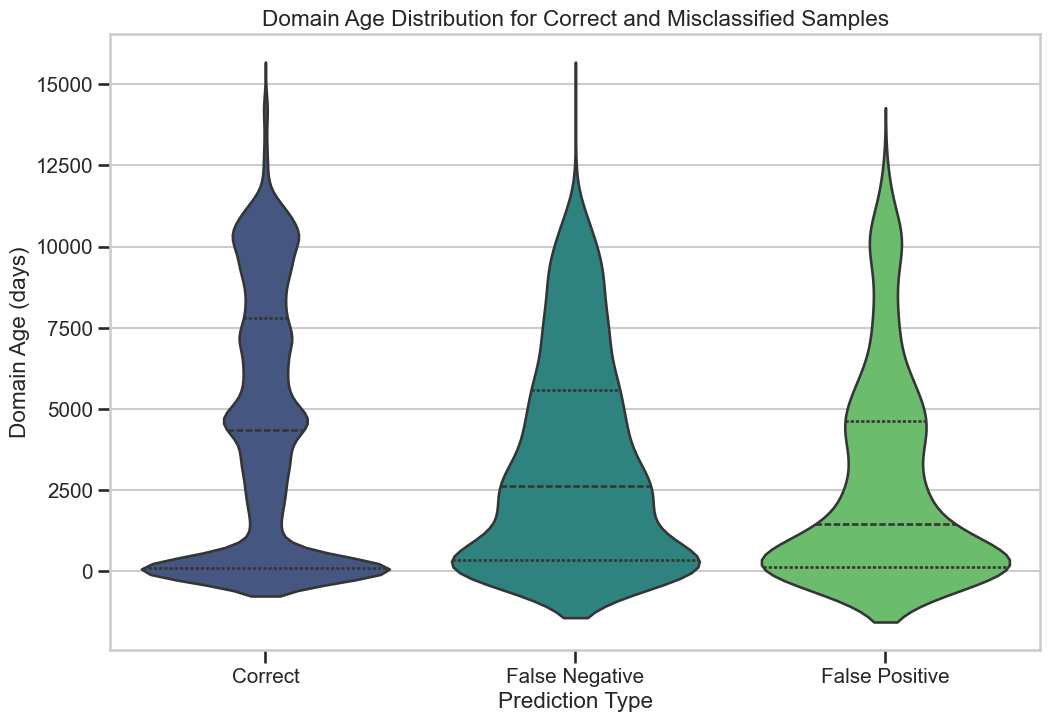

In [114]:
plt.figure(figsize=(12,8))

sns.violinplot(
    data=data,
    x="type",
    y="domain_age_days",
    palette="viridis",
    inner="quartile"
)

plt.title("Domain Age Distribution for Correct and Misclassified Samples")
plt.xlabel("Prediction Type")
plt.ylabel("Domain Age (days)")

plt.show()

In [116]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid")
sns.set_context("talk", font_scale=0.9)

# --------------------------------------------------
# 1. PREPARE PREDICTION DATA
# --------------------------------------------------
X_pred = X_test.copy()

# object/string kolonları kaldır
bad_cols = X_pred.select_dtypes(include=["object"]).columns.tolist()
print("Dropped object columns:", bad_cols)
X_pred = X_pred.drop(columns=bad_cols, errors="ignore")

# indexleri hizala
X_pred = X_pred.reset_index(drop=True)
y_true = pd.Series(y_test).reset_index(drop=True)

# modelin beklediği feature düzeni
if hasattr(model, "feature_name_") and model.feature_name_ is not None:
    train_features = list(model.feature_name_)
    X_pred = X_pred[train_features]

# prediction
y_prob = model.predict_proba(X_pred)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)

results = pd.DataFrame({
    "y_true": y_true,
    "y_pred": y_pred,
    "p_phishing": y_prob
})

results["type"] = "Correct"
results.loc[(results["y_true"] == 0) & (results["y_pred"] == 1), "type"] = "False Positive"
results.loc[(results["y_true"] == 1) & (results["y_pred"] == 0), "type"] = "False Negative"

print(results["type"].value_counts())

# analiz dataframe
data = pd.concat([results[["type", "y_true", "y_pred", "p_phishing"]], X_pred], axis=1)

# seçilen featurelar
selected_features = [
    "domain_age_days",
    "hostname_length",
    "has_www",
    "query_length",
    "num_digits",
    "ttl_value"
]

# sadece mevcut olanları al
selected_features = [f for f in selected_features if f in data.columns]
print("Selected features:", selected_features)

Dropped object columns: ['url']
type
Correct           113208
False Negative      1637
False Positive      1139
Name: count, dtype: int64
Selected features: ['domain_age_days', 'hostname_length', 'has_www', 'query_length', 'num_digits', 'ttl_value']


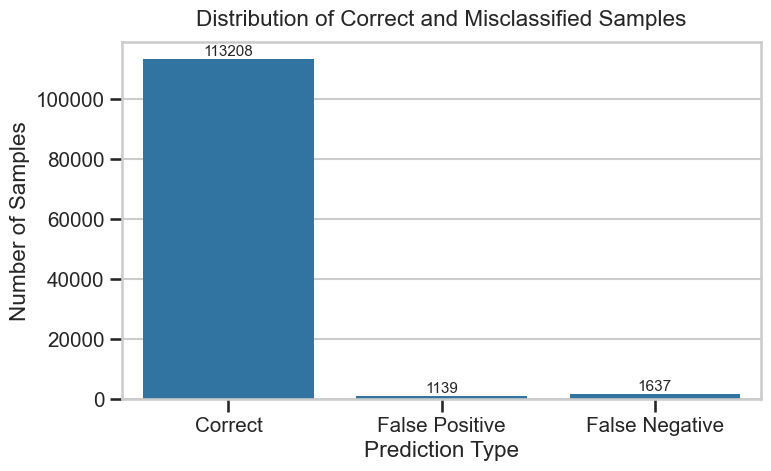

In [117]:
error_counts = results["type"].value_counts().reindex(
    ["Correct", "False Positive", "False Negative"]
)

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    x=error_counts.index,
    y=error_counts.values
)

ax.set_title("Distribution of Correct and Misclassified Samples", pad=12)
ax.set_xlabel("Prediction Type")
ax.set_ylabel("Number of Samples")

max_val = error_counts.max()
for i, v in enumerate(error_counts.values):
    ax.text(i, v + max_val * 0.01, f"{v}", ha="center", fontsize=11)

plt.tight_layout()
plt.show()

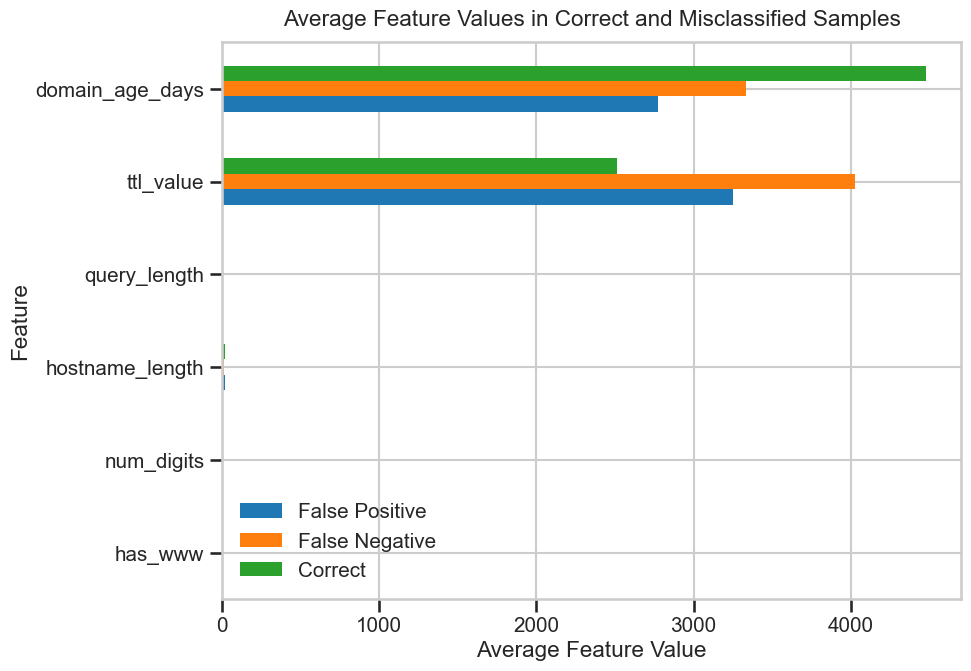

In [118]:
fp_mean = data[data["type"] == "False Positive"][selected_features].mean()
fn_mean = data[data["type"] == "False Negative"][selected_features].mean()
correct_mean = data[data["type"] == "Correct"][selected_features].mean()

compare_df = pd.DataFrame({
    "False Positive": fp_mean,
    "False Negative": fn_mean,
    "Correct": correct_mean
})

# sıralama: hata ile doğru arasındaki toplam fark
compare_df["Total_diff"] = (
    (compare_df["False Positive"] - compare_df["Correct"]).abs() +
    (compare_df["False Negative"] - compare_df["Correct"]).abs()
)

plot_df = compare_df.sort_values("Total_diff", ascending=True).drop(columns="Total_diff")

plot_df.plot(kind="barh", figsize=(10, 7))
plt.title("Average Feature Values in Correct and Misclassified Samples", pad=12)
plt.xlabel("Average Feature Value")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

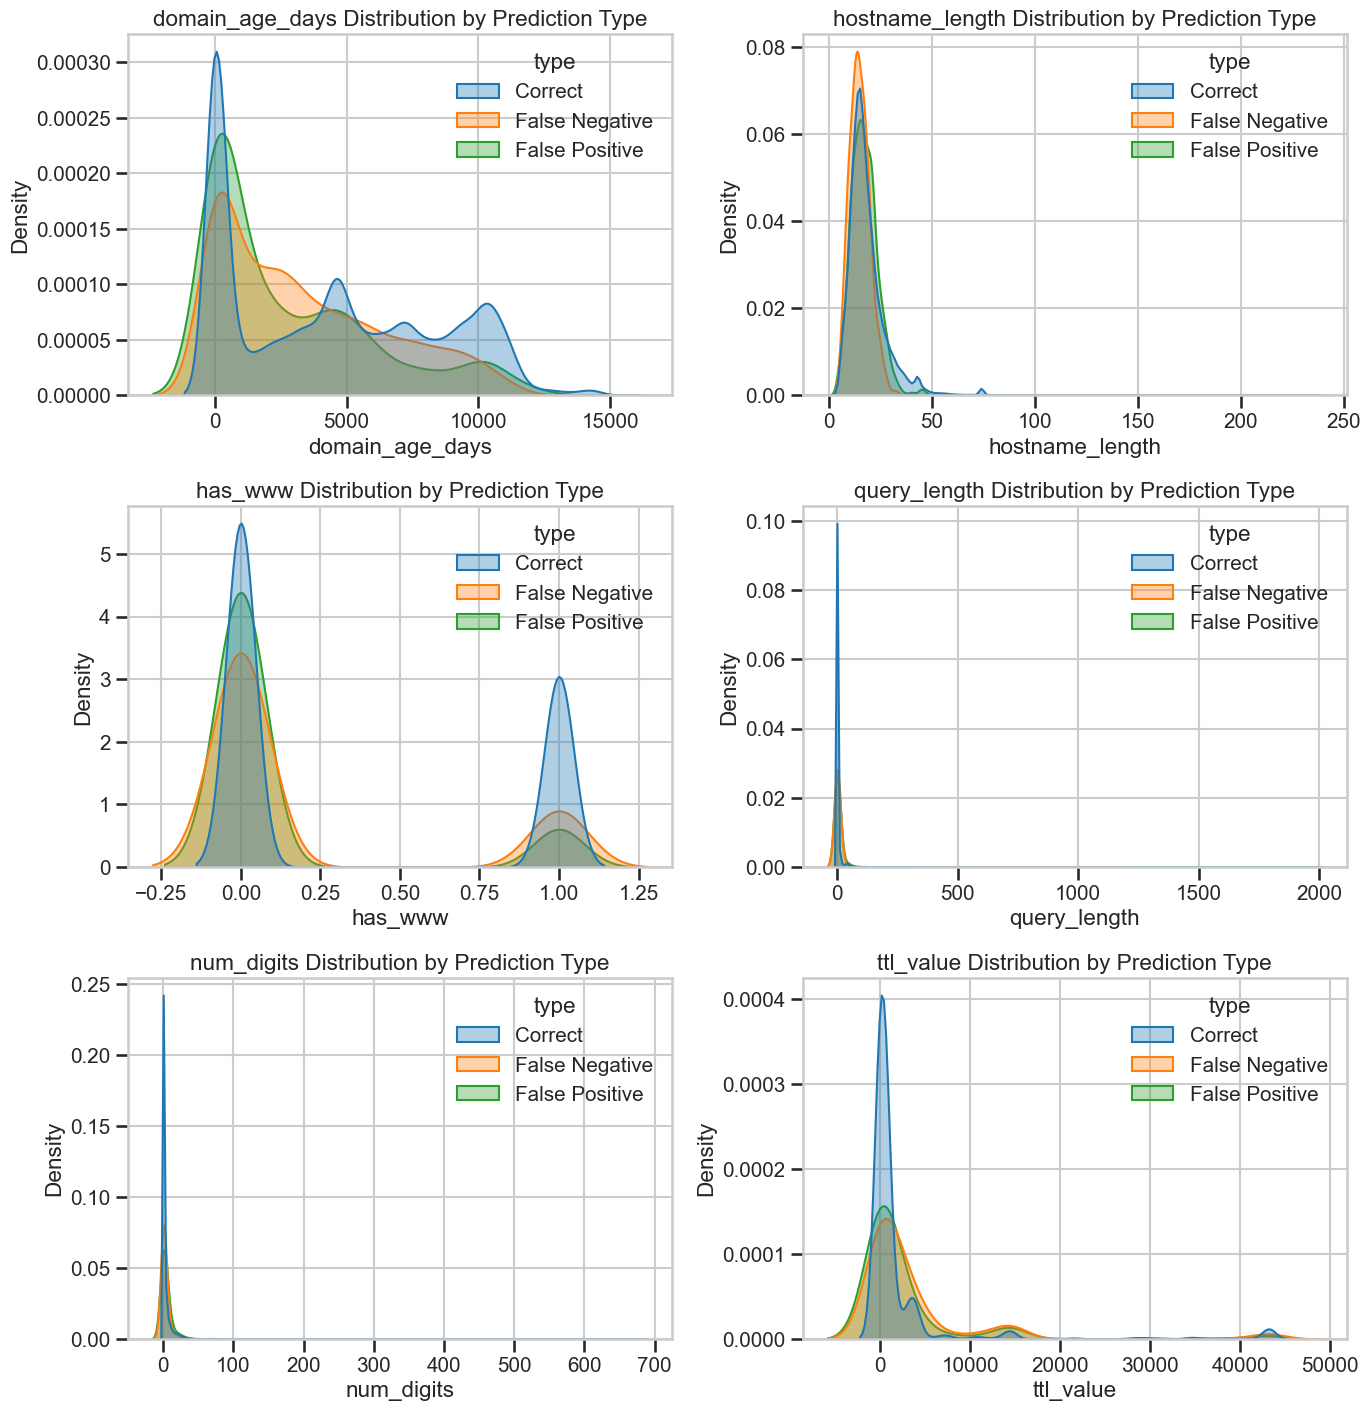

In [119]:
n_feats = len(selected_features)
n_cols = 2
n_rows = int(np.ceil(n_feats / n_cols))

plt.figure(figsize=(14, 4.8 * n_rows))

for i, feature in enumerate(selected_features, 1):
    plt.subplot(n_rows, n_cols, i)

    sns.kdeplot(
        data=data,
        x=feature,
        hue="type",
        fill=True,
        common_norm=False,
        alpha=0.35
    )

    plt.title(f"{feature} Distribution by Prediction Type")
    plt.xlabel(feature)
    plt.ylabel("Density")

plt.tight_layout()
plt.show()

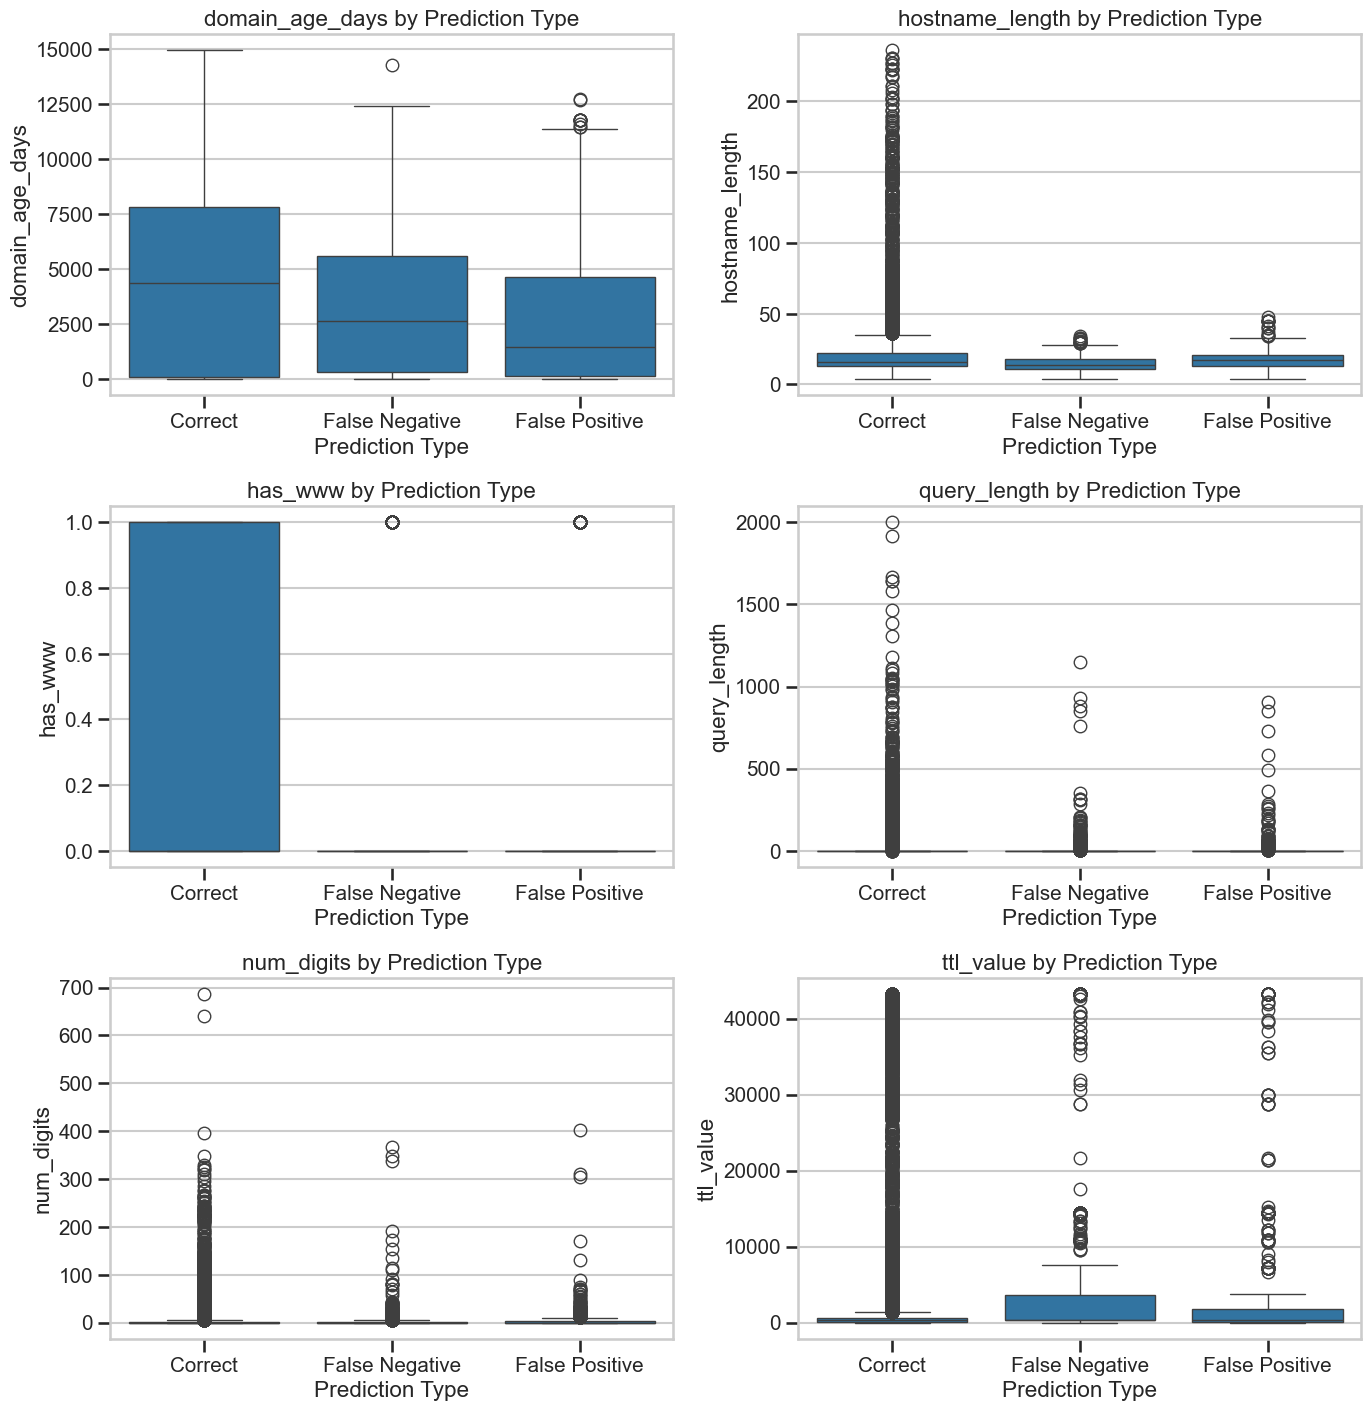

In [120]:
n_feats = len(selected_features)
n_cols = 2
n_rows = int(np.ceil(n_feats / n_cols))

plt.figure(figsize=(14, 4.8 * n_rows))

for i, feature in enumerate(selected_features, 1):
    plt.subplot(n_rows, n_cols, i)

    sns.boxplot(
        data=data,
        x="type",
        y=feature
    )

    plt.title(f"{feature} by Prediction Type")
    plt.xlabel("Prediction Type")
    plt.ylabel(feature)

plt.tight_layout()
plt.show()

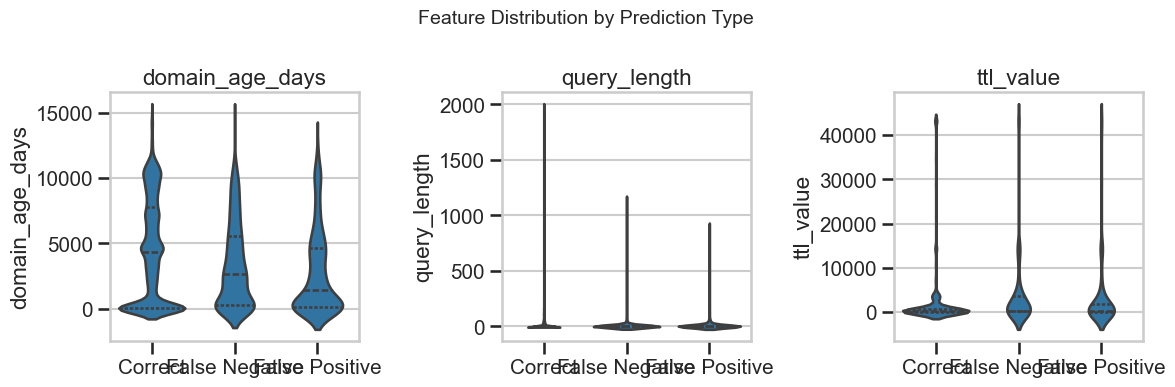

In [122]:
features = ["domain_age_days","query_length","ttl_value"]

plt.figure(figsize=(12,4))

for i,f in enumerate(features,1):

    plt.subplot(1,3,i)

    sns.violinplot(
        data=data,
        x="type",
        y=f,
        inner="quartile"
    )

    plt.title(f)
    plt.xlabel("")
    plt.ylabel(f)

plt.suptitle("Feature Distribution by Prediction Type",fontsize=14)
plt.tight_layout()
plt.show()

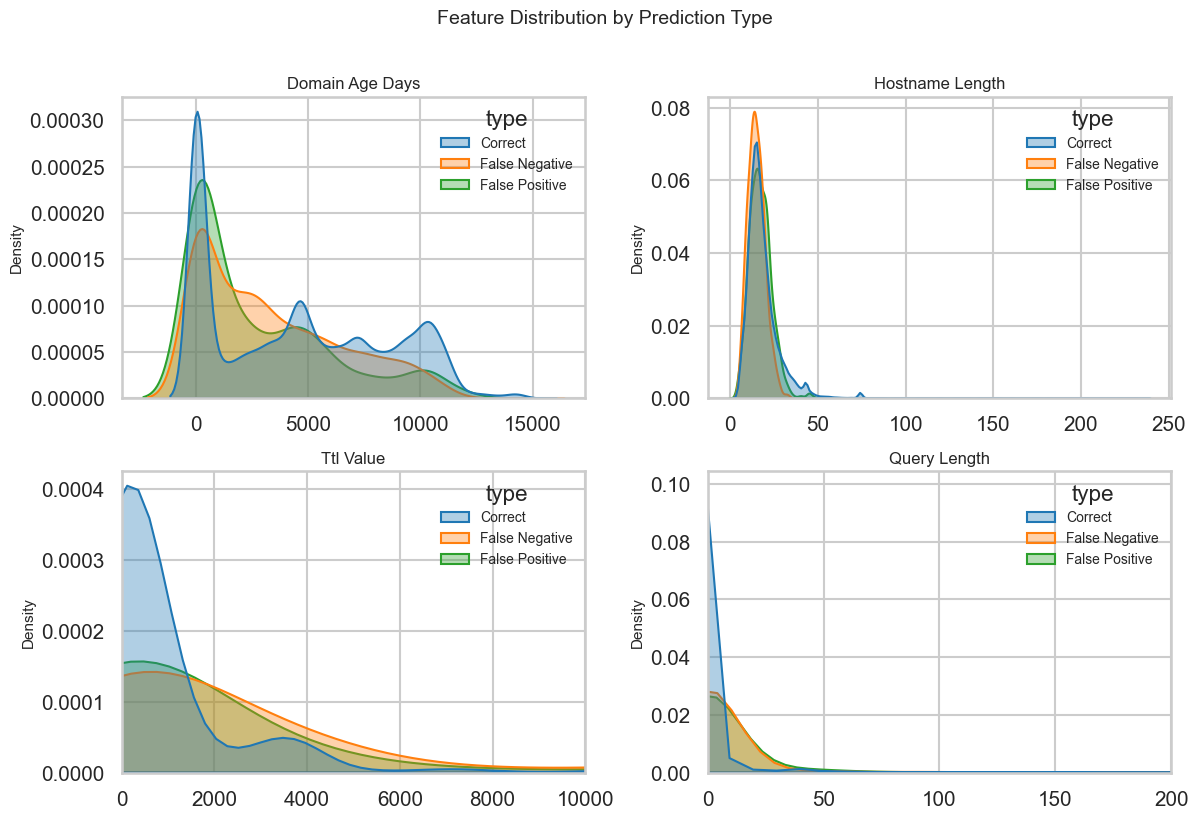

In [124]:
import matplotlib.pyplot as plt
import seaborn as sns

# --------------------------------
# STYLE (Academic look)
# --------------------------------

sns.set_style("whitegrid")

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "legend.fontsize": 10
})

# --------------------------------
# FEATURES
# --------------------------------

features = [
    "domain_age_days",
    "hostname_length",
    "ttl_value",
    "query_length"
]

fig, axes = plt.subplots(2, 2, figsize=(12,8))

axes = axes.flatten()

for i, feature in enumerate(features):

    ax = axes[i]

    sns.kdeplot(
        data=data,
        x=feature,
        hue="type",
        fill=True,
        common_norm=False,
        alpha=0.35,
        ax=ax
    )

    ax.set_title(feature.replace("_"," ").title())

    ax.set_xlabel("")
    ax.set_ylabel("Density")

    # scale problems fix
    if feature == "query_length":
        ax.set_xlim(0,200)

    if feature == "ttl_value":
        ax.set_xlim(0,10000)

# --------------------------------
# GLOBAL TITLE
# --------------------------------

fig.suptitle(
    "Feature Distribution by Prediction Type",
    fontsize=14,
    y=1.02
)

plt.tight_layout()

plt.show()

In [6]:
import platform
import psutil

print("Processor:", platform.processor())
print("Physical cores:", psutil.cpu_count(logical=False))
print("Logical cores:", psutil.cpu_count(logical=True))
print("CPU freq:", psutil.cpu_freq())
!wmic cpu get name


ram = psutil.virtual_memory()
print(f"Total RAM: {ram.total / (1024**3):.2f} GB")
print(f"Available RAM: {ram.available / (1024**3):.2f} GB")
print(f"Used RAM: {ram.used / (1024**3):.2f} GB")
!nvidia-smi

Processor: Intel64 Family 6 Model 141 Stepping 1, GenuineIntel
Physical cores: 8
Logical cores: 16
CPU freq: scpufreq(current=2304.0, min=0.0, max=2304.0)
Name                                            

11th Gen Intel(R) Core(TM) i7-11800H @ 2.30GHz  



Total RAM: 15.75 GB
Available RAM: 3.64 GB
Used RAM: 12.11 GB
Wed Mar 11 13:12:48 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 576.80                 Driver Version: 576.80         CUDA Version: 12.9     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0

Name                                            

11th Gen Intel(R) Core(TM) i7-11800H @ 2.30GHz  





In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")

# ---------------------------------------------------
# LOAD
# ---------------------------------------------------
shap_path = r"C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\shap_local_v2_400\light_shap_local_long.csv"
lime_path = r"C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\lime_local_v2_400\light_lime_explanations_long.csv"

shap_df = pd.read_csv(shap_path)
lime_df = pd.read_csv(lime_path)

# ---------------------------------------------------
# SAMPLE SELECTION
# Aynı sample_id hem SHAP hem LIME içinde olan bir örnek seçelim
# Önce LIME metadata'dan doğru phishing örneğini seçiyoruz
# ---------------------------------------------------
sample_info = lime_df[
    ["sample_id", "y_true", "y_pred", "p_phishing"]
].drop_duplicates().copy()

correct_phish = sample_info[
    (sample_info["y_true"] == 1) & (sample_info["y_pred"] == 1)
].copy()

if len(correct_phish) == 0:
    raise ValueError("Doğru phishing örneği bulunamadı.")

# En yüksek phishing olasılıklı doğru phishing örneği
selected_row = correct_phish.sort_values("p_phishing", ascending=False).iloc[0]
selected_sample_id = selected_row["sample_id"]

print("Selected sample_id:", selected_sample_id)
print("y_true:", selected_row["y_true"])
print("y_pred:", selected_row["y_pred"])
print("p_phishing:", selected_row["p_phishing"])

# ---------------------------------------------------
# İstersen elle de seçebilirsin:
# selected_sample_id = 15209
# ---------------------------------------------------

Selected sample_id: 15209.0
y_true: 1.0
y_pred: 1.0
p_phishing: 0.9999997630185282


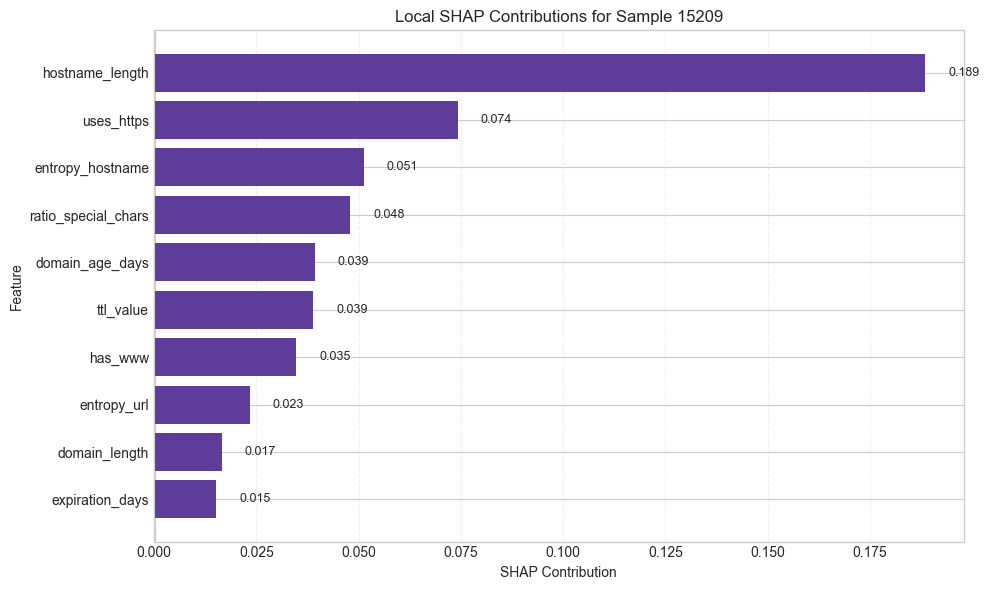

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------
# FILTER SHAP FOR ONE SAMPLE
# ---------------------------------------------------
sample_shap = shap_df[shap_df["sample_id"] == selected_sample_id].copy()

if sample_shap.empty:
    raise ValueError(f"SHAP içinde {selected_sample_id} sample_id bulunamadı.")

# En önemli 10 veya 15 feature
TOP_K = 10
sample_shap = sample_shap.sort_values("abs_shap", ascending=False).head(TOP_K).copy()

# signed değerleri koru
sample_shap = sample_shap.sort_values("shap_value", ascending=True)

# renkler
colors = ["#5E3C99" if v > 0 else "#1B9E77" for v in sample_shap["shap_value"]]

# ---------------------------------------------------
# PLOT
# ---------------------------------------------------
plt.figure(figsize=(10, 6))

bars = plt.barh(
    sample_shap["feature_name"],
    sample_shap["shap_value"],
    color=colors
)

plt.axvline(x=0, color="black", linewidth=1)

# değerleri yaz
xmax = max(abs(sample_shap["shap_value"].min()), abs(sample_shap["shap_value"].max()))

for i, row in enumerate(sample_shap.itertuples()):
    offset = xmax * 0.03
    if row.shap_value >= 0:
        plt.text(
            row.shap_value + offset,
            i,
            f"{row.shap_value:.3f}",
            va="center",
            fontsize=9
        )
    else:
        plt.text(
            row.shap_value - offset,
            i,
            f"{row.shap_value:.3f}",
            va="center",
            ha="right",
            fontsize=9
        )

plt.xlabel("SHAP Contribution")
plt.ylabel("Feature")
plt.title(f"Local SHAP Contributions for Sample {int(selected_sample_id)}")
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

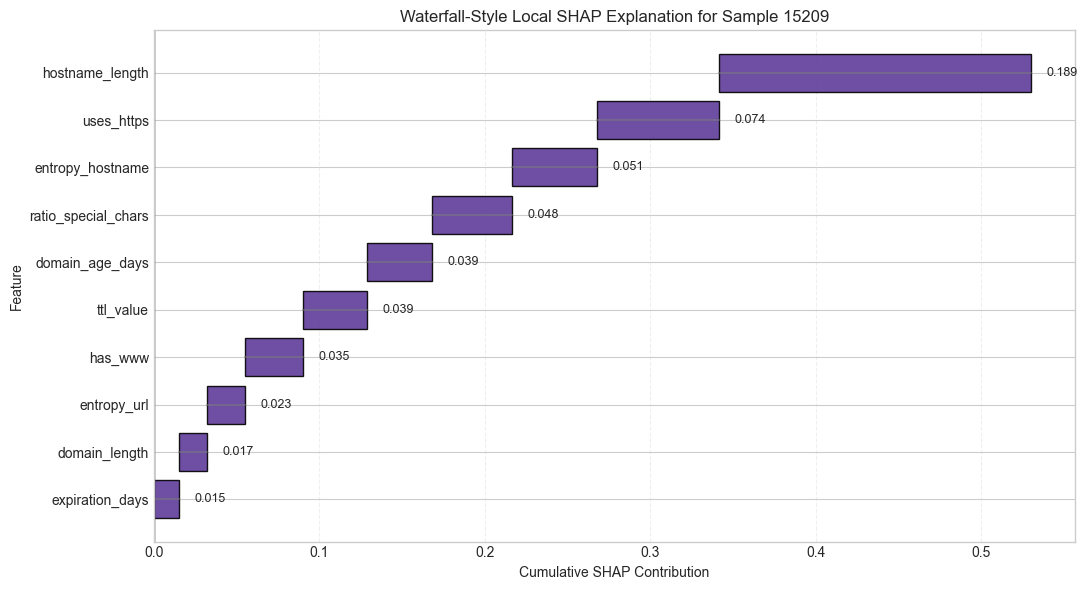

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

sample_shap = shap_df[shap_df["sample_id"] == selected_sample_id].copy()

if sample_shap.empty:
    raise ValueError(f"SHAP içinde {selected_sample_id} sample_id bulunamadı.")

TOP_K = 10
sample_shap = sample_shap.sort_values("abs_shap", ascending=False).head(TOP_K).copy()

# büyükten küçüğe sırala
sample_shap = sample_shap.sort_values("abs_shap", ascending=True).reset_index(drop=True)

# waterfall için kümülatif başlangıçlar
starts = []
current = 0.0

for val in sample_shap["shap_value"]:
    starts.append(current)
    current += val

sample_shap["start"] = starts
sample_shap["end"] = sample_shap["start"] + sample_shap["shap_value"]

colors = ["#5E3C99" if v > 0 else "#1B9E77" for v in sample_shap["shap_value"]]

plt.figure(figsize=(11, 6))

for i, row in sample_shap.iterrows():
    left = min(row["start"], row["end"])
    width = abs(row["shap_value"])
    
    plt.barh(
        y=i,
        width=width,
        left=left,
        color=colors[i],
        edgecolor="black",
        alpha=0.9
    )
    
    # başlangıç-bitiş bağlantı çizgisi
    plt.plot(
        [row["start"], row["end"]],
        [i, i],
        color="gray",
        alpha=0.5,
        linewidth=1.5
    )
    
    # değer etiketi
    xpos = row["end"]
    offset = max(sample_shap["abs_shap"]) * 0.05
    if row["shap_value"] >= 0:
        plt.text(xpos + offset, i, f"{row['shap_value']:.3f}", va="center", fontsize=9)
    else:
        plt.text(xpos - offset, i, f"{row['shap_value']:.3f}", va="center", ha="right", fontsize=9)

plt.yticks(range(len(sample_shap)), sample_shap["feature_name"])
plt.axvline(x=0, color="black", linewidth=1)

plt.xlabel("Cumulative SHAP Contribution")
plt.ylabel("Feature")
plt.title(f"Waterfall-Style Local SHAP Explanation for Sample {int(selected_sample_id)}")
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

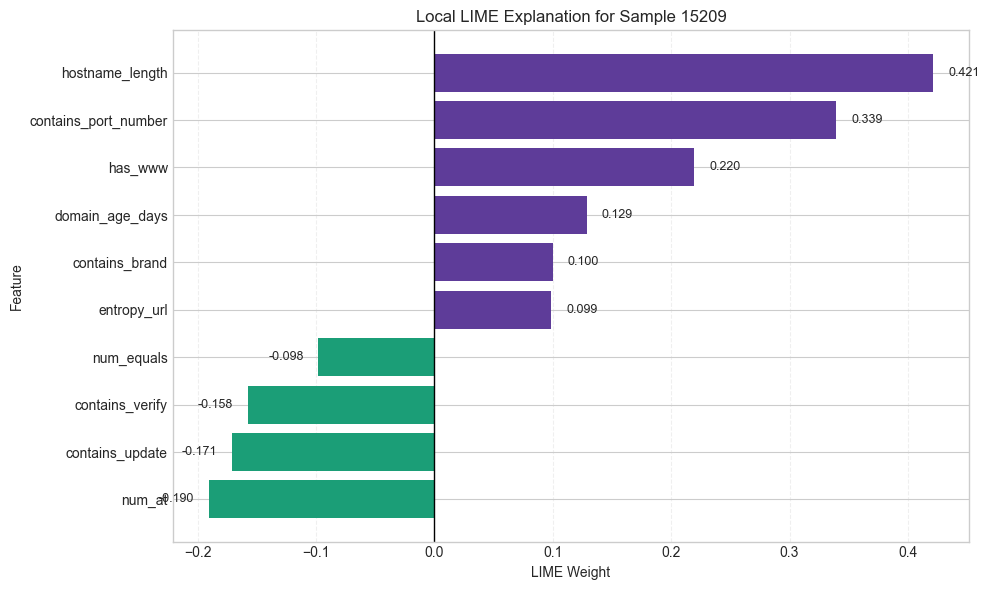

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------
# FILTER LIME FOR ONE SAMPLE
# ---------------------------------------------------
sample_lime = lime_df[lime_df["sample_id"] == selected_sample_id].copy()

if sample_lime.empty:
    raise ValueError(f"LIME içinde {selected_sample_id} sample_id bulunamadı.")

TOP_K = 10
sample_lime = sample_lime.sort_values("abs_weight", ascending=False).head(TOP_K).copy()
sample_lime = sample_lime.sort_values("weight", ascending=True)

colors = ["#5E3C99" if v > 0 else "#1B9E77" for v in sample_lime["weight"]]

plt.figure(figsize=(10, 6))

plt.barh(
    sample_lime["feature_name"],
    sample_lime["weight"],
    color=colors
)

plt.axvline(x=0, color="black", linewidth=1)

xmax = max(abs(sample_lime["weight"].min()), abs(sample_lime["weight"].max()))

for i, row in enumerate(sample_lime.itertuples()):
    offset = xmax * 0.03
    if row.weight >= 0:
        plt.text(
            row.weight + offset,
            i,
            f"{row.weight:.3f}",
            va="center",
            fontsize=9
        )
    else:
        plt.text(
            row.weight - offset,
            i,
            f"{row.weight:.3f}",
            va="center",
            ha="right",
            fontsize=9
        )

plt.xlabel("LIME Weight")
plt.ylabel("Feature")
plt.title(f"Local LIME Explanation for Sample {int(selected_sample_id)}")
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
import matplotlib.pyplot as plt
import numpy as np

def plot_local_explanation(df, value_col, title, color_pos="#5E3C99", color_neg="#1B9E77"):
    
    df = df.copy()
    
    # en önemli feature'lar
    TOP_K = 10
    df = df.sort_values(f"abs_{value_col}", ascending=False).head(TOP_K)
    
    # sıralama (görsel düzen için)
    df = df.sort_values(value_col)
    
    values = df[value_col].values
    features = df["feature_name"].values
    
    colors = [color_pos if v > 0 else color_neg for v in values]
    
    plt.figure(figsize=(10, 7))
    
    bars = plt.barh(features, values, color=colors, edgecolor="black", linewidth=0.8)
    
    # merkezi çizgi (çok önemli)
    plt.axvline(x=0, color="black", linewidth=1.5)
    
    # arka plan grid
    plt.grid(axis="x", linestyle="--", alpha=0.3)
    
    # değer etiketleri
    xmax = max(abs(values.min()), abs(values.max()))
    
    for i, v in enumerate(values):
        offset = xmax * 0.03
        
        if v >= 0:
            plt.text(v + offset, i, f"{v:.3f}", va="center", fontsize=10)
        else:
            plt.text(v - offset, i, f"{v:.3f}", va="center", ha="right", fontsize=10)
    
    # eksenler
    plt.xlabel("Feature Contribution", fontsize=12)
    plt.ylabel("Feature", fontsize=12)
    
    # güçlü başlık
    plt.title(title, fontsize=13, weight="bold")
    
    # üstte açıklama (çok profesyonel görünür)
    plt.text(
        0.5, 1.05,
        "← Benign Direction        Phishing Direction →",
        ha="center",
        transform=plt.gca().transAxes,
        fontsize=10,
        alpha=0.8
    )
    
    plt.tight_layout()
    plt.show()

In [6]:
sample_shap = shap_df[shap_df["sample_id"] == selected_sample_id].copy()

plot_local_explanation(
    sample_shap,
    value_col="shap_value",
    title="Local SHAP Feature Contributions"
)

KeyError: 'abs_shap_value'

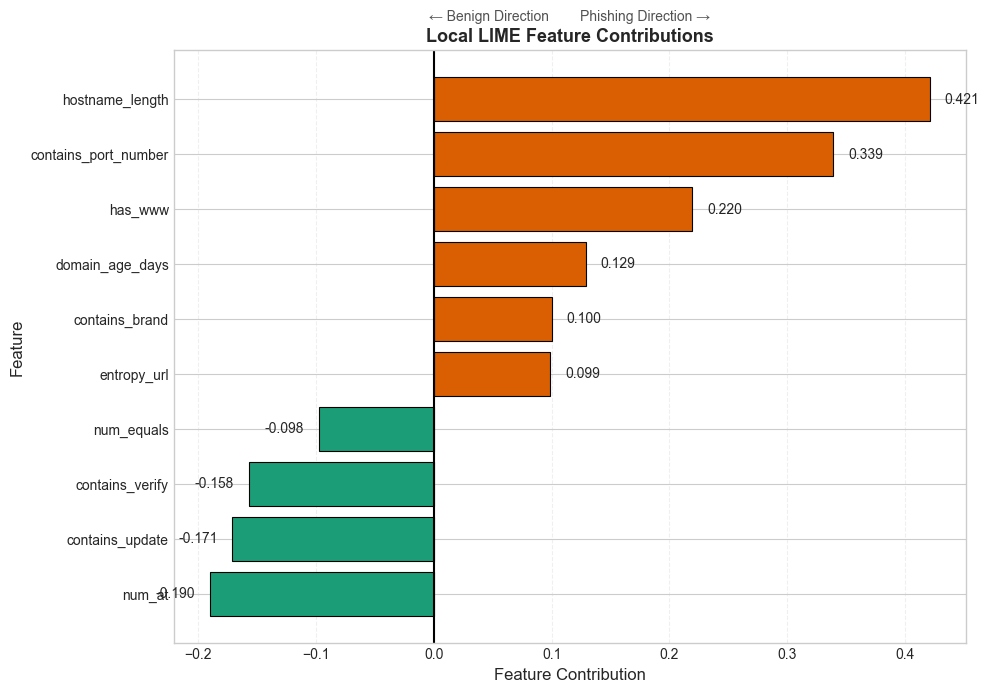

In [7]:
sample_lime = lime_df[lime_df["sample_id"] == selected_sample_id].copy()

plot_local_explanation(
    sample_lime,
    value_col="weight",
    title="Local LIME Feature Contributions",
    color_pos="#D95F02",   # farklı ton kullan (opsiyonel)
    color_neg="#1B9E77"
)

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def plot_shap_waterfall_like(df, sample_id):

    sample = df[df["sample_id"] == sample_id].copy()

    TOP_K = 10
    sample = sample.sort_values("abs_shap", ascending=False).head(TOP_K)

    # büyükten küçüğe
    sample = sample.sort_values("abs_shap", ascending=True).reset_index(drop=True)

    values = sample["shap_value"].values
    features = sample["feature_name"].values

    cumulative = np.cumsum(values)

    starts = np.concatenate(([0], cumulative[:-1]))
    ends = cumulative

    colors = ["#FF0051" if v > 0 else "#1E88E5" for v in values]

    plt.figure(figsize=(11, 6))

    for i in range(len(values)):
        left = min(starts[i], ends[i])
        width = abs(values[i])

        plt.barh(
            y=i,
            width=width,
            left=left,
            color=colors[i],
            edgecolor="black"
        )

        # değer yaz
        xpos = ends[i]
        offset = max(abs(values)) * 0.1

        if values[i] > 0:
            plt.text(xpos + offset, i, f"+{values[i]:.2f}", va="center", fontsize=10)
        else:
            plt.text(xpos - offset, i, f"{values[i]:.2f}", va="center", ha="right", fontsize=10)

    plt.yticks(range(len(features)), features)

    plt.axvline(x=0, color="black", linewidth=1.5)

    plt.xlabel("Model Output Contribution")
    plt.title("Waterfall-Style SHAP Explanation")

    plt.grid(axis="x", linestyle="--", alpha=0.3)
    plt.tight_layout()
    plt.show()

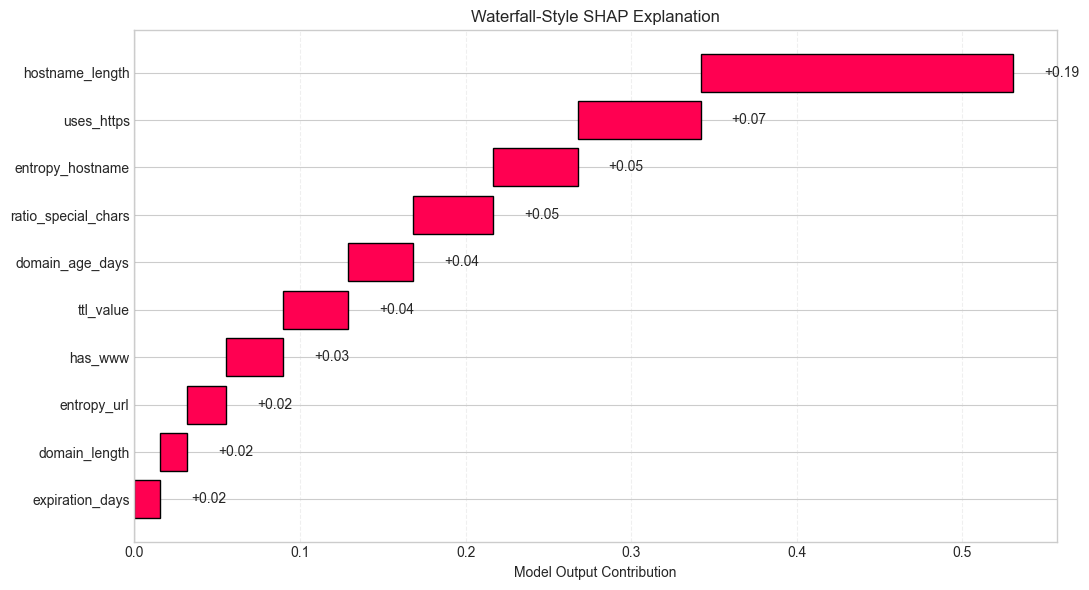

In [10]:
plot_shap_waterfall_like(shap_df, selected_sample_id)

In [11]:
# =========================================================
# LOCAL XAI - SHAP Waterfall + LIME Diverging Plot
# Publication-quality version for the paper
# =========================================================

import os
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

# ---------------------------------------------------------
# STYLE
# ---------------------------------------------------------
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10
})

# ---------------------------------------------------------
# PATHS
# ---------------------------------------------------------
base_candidates = [
    Path(r"C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale"),
    Path(os.path.expanduser("~/Bitirme_Projesi_Dataset_Olusturma/Makale")),
    Path(".")
]

BASE_DIR = next((p for p in base_candidates if p.exists()), None)
if BASE_DIR is None:
    raise FileNotFoundError("Makale ana klasörü bulunamadı.")

CACHE_DIR = BASE_DIR / "outputs" / "LightGBM" / "cache_v1"
LIME_DIR  = BASE_DIR / "outputs" / "LightGBM" / "lime_local_v2_400"
SHAP_LOCAL_DIR = BASE_DIR / "outputs" / "LightGBM" / "shap_local_v2_400"
SAVE_DIR = BASE_DIR / "outputs" / "LightGBM" / "paper_local_xai_figures"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

X_path = CACHE_DIR / "explain_X.csv"
meta_path = CACHE_DIR / "cache_meta.json"
shap_npz_path = CACHE_DIR / "shap_values.npz"

lime_long_path = LIME_DIR / "light_lime_explanations_long.csv"
shap_long_path = SHAP_LOCAL_DIR / "light_shap_local_long.csv"

# ---------------------------------------------------------
# LOAD
# ---------------------------------------------------------
X = pd.read_csv(X_path)
npz = np.load(shap_npz_path, allow_pickle=True)
shap_values = npz["shap_values"]

with open(meta_path, "r", encoding="utf-8") as f:
    meta = json.load(f)

feature_cols = meta.get("feature_cols", list(X.columns))
X = X[feature_cols].copy()

lime_df = pd.read_csv(lime_long_path)
shap_long_df = pd.read_csv(shap_long_path)

print("BASE_DIR:", BASE_DIR)
print("X shape:", X.shape)
print("SHAP shape:", shap_values.shape)
print("LIME long shape:", lime_df.shape)
print("SHAP long shape:", shap_long_df.shape)

# ---------------------------------------------------------
# SAMPLE SELECTION
# doğru sınıflanmış ve phishing olasılığı en yüksek örnek
# ---------------------------------------------------------
sample_info = lime_df[["sample_id", "y_true", "y_pred", "p_phishing"]].drop_duplicates().copy()

correct_phish = sample_info[
    (sample_info["y_true"] == 1) & (sample_info["y_pred"] == 1)
].copy()

if correct_phish.empty:
    raise ValueError("Doğru sınıflanmış phishing örneği bulunamadı.")

selected_row = correct_phish.sort_values("p_phishing", ascending=False).iloc[0]
selected_sample_id = int(selected_row["sample_id"])

print("\nSelected sample_id:", selected_sample_id)
print("Predicted phishing probability:", selected_row["p_phishing"])

# ---------------------------------------------------------
# SHAP row mapping
# Eğer explain_X içinde sample_id kolonu yoksa sample_id'nin satır indeksi
# ile aynı olduğu varsayılır. Gerekirse burayı elle değiştir.
# ---------------------------------------------------------
if "sample_id" in X.columns:
    matched = X.index[X["sample_id"] == selected_sample_id].tolist()
    if not matched:
        raise ValueError("X içinde sample_id eşleşmesi bulunamadı.")
    shap_row_idx = matched[0]
else:
    shap_row_idx = selected_sample_id
    if shap_row_idx >= len(X):
        raise ValueError(
            f"sample_id={selected_sample_id} explain_X satır sayısını aşıyor. "
            "Bu durumda shap_row_idx'yi elle belirlemelisin."
        )

print("Mapped SHAP row index:", shap_row_idx)

BASE_DIR: C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale
X shape: (10000, 75)
SHAP shape: (10000, 75)
LIME long shape: (12000, 12)
SHAP long shape: (12000, 8)

Selected sample_id: 15209
Predicted phishing probability: 0.9999997630185282


ValueError: sample_id=15209 explain_X satır sayısını aşıyor. Bu durumda shap_row_idx'yi elle belirlemelisin.

SHAP long shape: (12000, 8)
LIME long shape: (12000, 12)

Selected sample_id: 15209
Predicted phishing probability: 0.9999997630185282


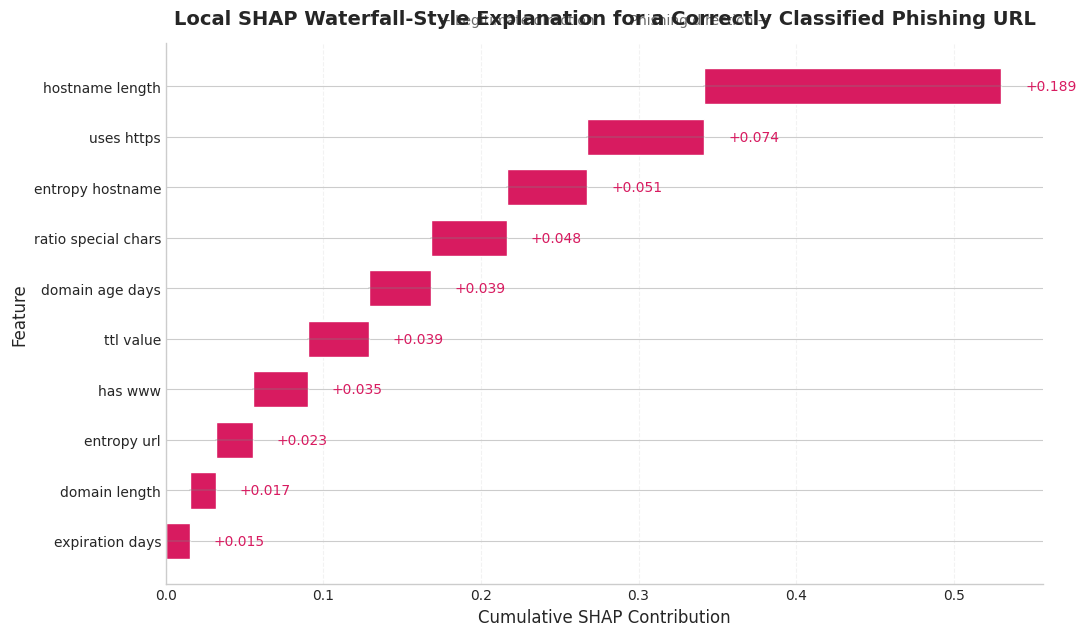

Saved SHAP figure:
C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\paper_local_xai_figures\fig_local_shap_waterfall_style.png
C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\paper_local_xai_figures\fig_local_shap_waterfall_style.pdf


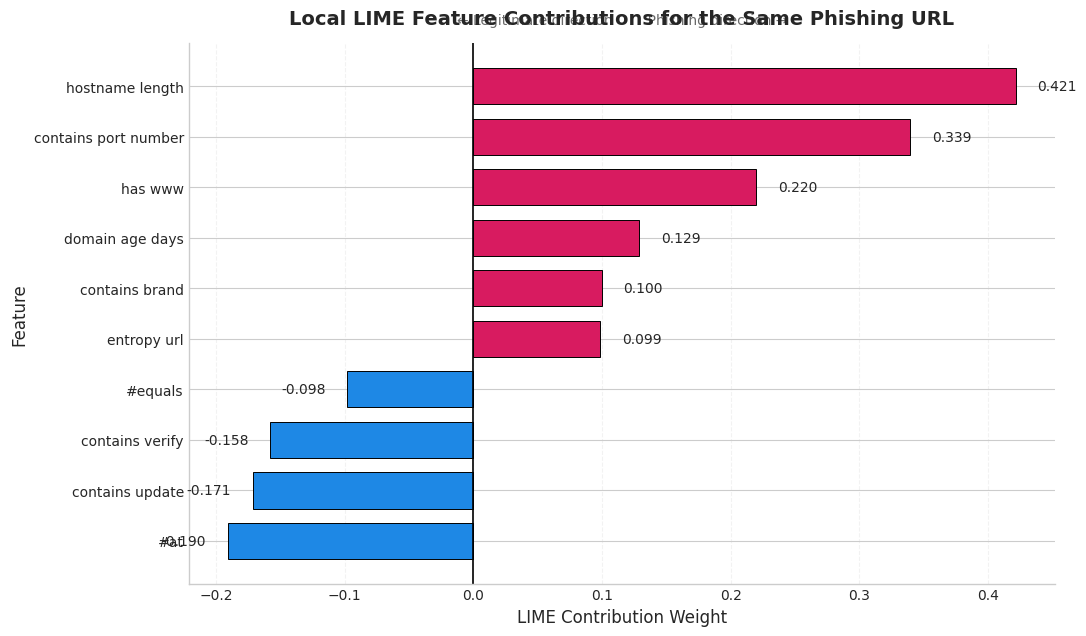

Saved LIME figure:
C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\paper_local_xai_figures\fig_local_lime_diverging.png
C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\paper_local_xai_figures\fig_local_lime_diverging.pdf


In [12]:
# =========================================================
# FINAL LOCAL XAI FIGURES
# SHAP waterfall-style + LIME diverging bar
# Works directly from local long CSV files
# =========================================================

import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# STYLE (publication quality)
# ---------------------------------------------------------
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10
})

# ---------------------------------------------------------
# PATHS
# ---------------------------------------------------------
base_candidates = [
    Path(r"C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale"),
    Path(os.path.expanduser("~/Bitirme_Projesi_Dataset_Olusturma/Makale")),
    Path(".")
]

BASE_DIR = next((p for p in base_candidates if p.exists()), None)
if BASE_DIR is None:
    raise FileNotFoundError("Makale ana klasörü bulunamadı.")

shap_path = BASE_DIR / "outputs" / "LightGBM" / "shap_local_v2_400" / "light_shap_local_long.csv"
lime_path = BASE_DIR / "outputs" / "LightGBM" / "lime_local_v2_400" / "light_lime_explanations_long.csv"

SAVE_DIR = BASE_DIR / "outputs" / "LightGBM" / "paper_local_xai_figures"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------
# LOAD
# ---------------------------------------------------------
shap_df = pd.read_csv(shap_path)
lime_df = pd.read_csv(lime_path)

print("SHAP long shape:", shap_df.shape)
print("LIME long shape:", lime_df.shape)

# ---------------------------------------------------------
# SAMPLE SELECTION
# doğru sınıflanmış ve phishing olasılığı en yüksek örnek
# ---------------------------------------------------------
sample_info = lime_df[
    ["sample_id", "y_true", "y_pred", "p_phishing"]
].drop_duplicates().copy()

correct_phish = sample_info[
    (sample_info["y_true"] == 1) & (sample_info["y_pred"] == 1)
].copy()

if correct_phish.empty:
    raise ValueError("Doğru sınıflanmış phishing örneği bulunamadı.")

selected_row = correct_phish.sort_values("p_phishing", ascending=False).iloc[0]
selected_sample_id = int(selected_row["sample_id"])

print("\nSelected sample_id:", selected_sample_id)
print("Predicted phishing probability:", selected_row["p_phishing"])

# ---------------------------------------------------------
# CLEAN LABELS
# ---------------------------------------------------------
def pretty_feature_name(s):
    s = str(s).replace("_", " ")
    s = s.replace("num ", "#")
    return s

# ---------------------------------------------------------
# FIGURE 1 — SHAP WATERFALL-STYLE
# ---------------------------------------------------------
sample_shap = shap_df[shap_df["sample_id"] == selected_sample_id].copy()

if sample_shap.empty:
    raise ValueError(f"SHAP içinde sample_id={selected_sample_id} bulunamadı.")

TOP_K = 10
sample_shap = (
    sample_shap.sort_values("abs_shap", ascending=False)
    .head(TOP_K)
    .copy()
)

# küçükten büyüğe değil, waterfall görünüm için en küçükten başlayıp en büyüğe doğru
sample_shap = sample_shap.sort_values("abs_shap", ascending=True).reset_index(drop=True)
sample_shap["feature_label"] = sample_shap["feature_name"].apply(pretty_feature_name)

values = sample_shap["shap_value"].values
labels = sample_shap["feature_label"].values

starts = []
current = 0.0
for v in values:
    starts.append(current)
    current += v
ends = np.array(starts) + values

colors = ["#1E88E5" if v < 0 else "#D81B60" for v in values]

fig, ax = plt.subplots(figsize=(11, 6.5))

for i, (start, end, val, color) in enumerate(zip(starts, ends, values, colors)):
    left = min(start, end)
    width = abs(val)

    ax.barh(
        y=i,
        width=width,
        left=left,
        height=0.72,
        color=color,
        edgecolor="white",
        linewidth=1.0
    )

    # bağlantı çizgisi
    ax.plot([start, end], [i, i], color="gray", alpha=0.35, linewidth=1.2)

    # ok ucu hissi için küçük üçgenimsi etki yerine metin
    offset = max(np.abs(values)) * 0.08 if len(values) else 0.05
    if val >= 0:
        ax.text(end + offset, i, f"+{val:.3f}", va="center", ha="left", fontsize=10, color=color)
    else:
        ax.text(end - offset, i, f"{val:.3f}", va="center", ha="right", fontsize=10, color=color)

ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels)

ax.axvline(0, color="black", linewidth=1.2)
ax.grid(axis="x", linestyle="--", alpha=0.25)

ax.set_xlabel("Cumulative SHAP Contribution")
ax.set_ylabel("Feature")
ax.set_title("Local SHAP Waterfall-Style Explanation for a Correctly Classified Phishing URL", pad=14)

ax.text(
    0.5, 1.03,
    "← Legitimate direction        Phishing direction →",
    transform=ax.transAxes,
    ha="center",
    va="bottom",
    fontsize=10,
    color="dimgray"
)

plt.tight_layout()

shap_png = SAVE_DIR / "fig_local_shap_waterfall_style.png"
shap_pdf = SAVE_DIR / "fig_local_shap_waterfall_style.pdf"

plt.savefig(shap_png, dpi=600, bbox_inches="tight")
plt.savefig(shap_pdf, bbox_inches="tight")
plt.show()

print("Saved SHAP figure:")
print(shap_png)
print(shap_pdf)

# ---------------------------------------------------------
# FIGURE 2 — LIME DIVERGING BAR
# ---------------------------------------------------------
sample_lime = lime_df[lime_df["sample_id"] == selected_sample_id].copy()

if sample_lime.empty:
    raise ValueError(f"LIME içinde sample_id={selected_sample_id} bulunamadı.")

sample_lime = (
    sample_lime.sort_values("abs_weight", ascending=False)
    .head(TOP_K)
    .sort_values("weight", ascending=True)
    .copy()
)

sample_lime["feature_label"] = sample_lime["feature_name"].apply(pretty_feature_name)

lime_values = sample_lime["weight"].values
lime_labels = sample_lime["feature_label"].values
lime_colors = ["#1E88E5" if v < 0 else "#D81B60" for v in lime_values]

fig, ax = plt.subplots(figsize=(11, 6.5))

bars = ax.barh(
    lime_labels,
    lime_values,
    color=lime_colors,
    edgecolor="black",
    linewidth=0.7,
    height=0.72
)

ax.axvline(0, color="black", linewidth=1.2)
ax.grid(axis="x", linestyle="--", alpha=0.25)

ax.set_xlabel("LIME Contribution Weight")
ax.set_ylabel("Feature")
ax.set_title("Local LIME Feature Contributions for the Same Phishing URL", pad=14)

ax.text(
    0.5, 1.03,
    "← Legitimate direction        Phishing direction →",
    transform=ax.transAxes,
    ha="center",
    va="bottom",
    fontsize=10,
    color="dimgray"
)

xmax = max(abs(lime_values.min()), abs(lime_values.max())) if len(lime_values) else 1
offset = xmax * 0.04

for i, v in enumerate(lime_values):
    if v >= 0:
        ax.text(v + offset, i, f"{v:.3f}", va="center", ha="left", fontsize=10)
    else:
        ax.text(v - offset, i, f"{v:.3f}", va="center", ha="right", fontsize=10)

plt.tight_layout()

lime_png = SAVE_DIR / "fig_local_lime_diverging.png"
lime_pdf = SAVE_DIR / "fig_local_lime_diverging.pdf"

plt.savefig(lime_png, dpi=600, bbox_inches="tight")
plt.savefig(lime_pdf, bbox_inches="tight")
plt.show()

print("Saved LIME figure:")
print(lime_png)
print(lime_pdf)

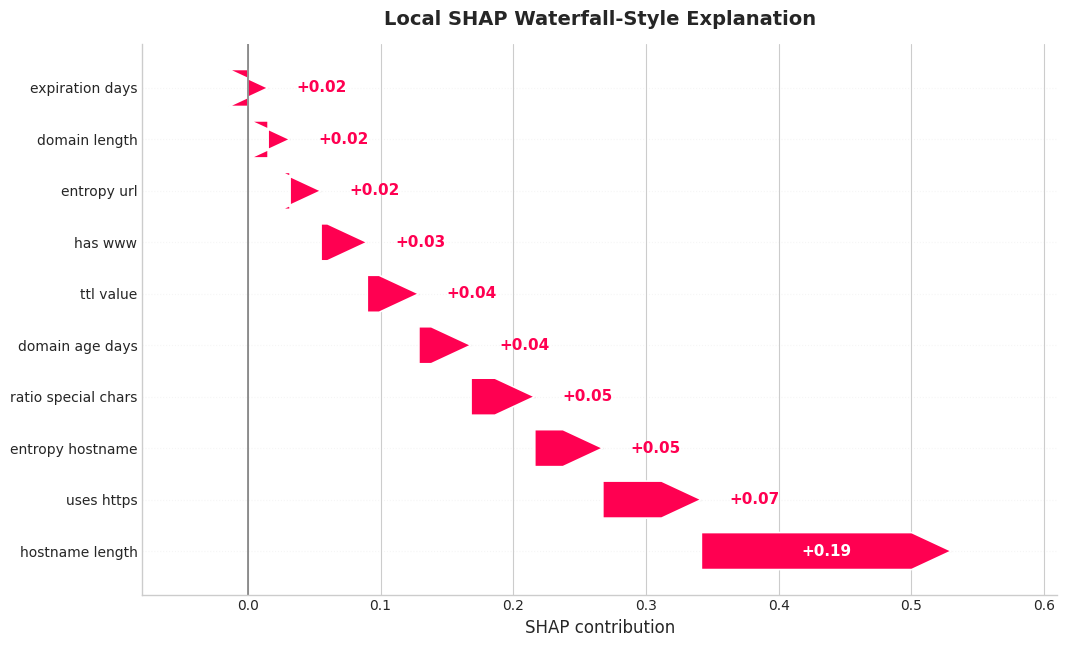

In [13]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10
})

BASE_DIR = Path(r"C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale")
shap_path = BASE_DIR / "outputs" / "LightGBM" / "shap_local_v2_400" / "light_shap_local_long.csv"
lime_path = BASE_DIR / "outputs" / "LightGBM" / "lime_local_v2_400" / "light_lime_explanations_long.csv"
SAVE_DIR = BASE_DIR / "outputs" / "LightGBM" / "paper_local_xai_figures"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

shap_df = pd.read_csv(shap_path)
lime_df = pd.read_csv(lime_path)

sample_info = lime_df[["sample_id", "y_true", "y_pred", "p_phishing"]].drop_duplicates()
selected_sample_id = int(
    sample_info[(sample_info["y_true"] == 1) & (sample_info["y_pred"] == 1)]
    .sort_values("p_phishing", ascending=False)
    .iloc[0]["sample_id"]
)

def pretty_name(x):
    return str(x).replace("_", " ")

def draw_waterfall_arrows(ax, labels, values, title, xlabel,
                          pos_color="#ff0051", neg_color="#1e88e5",
                          line_color="#bdbdbd", start_value=0.0):
    values = np.array(values, dtype=float)
    n = len(values)

    starts = [start_value]
    for v in values[:-1]:
        starts.append(starts[-1] + v)
    starts = np.array(starts)
    ends = starts + values

    h = 0.72
    tip = max(np.max(np.abs(values)) * 0.12, 0.03)

    for i, (lab, s, e, v) in enumerate(zip(labels, starts, ends, values)):
        y = i
        color = pos_color if v > 0 else neg_color

        if v >= 0:
            pts = [
                (s, y - h/2),
                (e - tip, y - h/2),
                (e, y),
                (e - tip, y + h/2),
                (s, y + h/2)
            ]
        else:
            pts = [
                (s, y - h/2),
                (e + tip, y - h/2),
                (e, y),
                (e + tip, y + h/2),
                (s, y + h/2)
            ]

        poly = Polygon(pts, closed=True, facecolor=color, edgecolor="white", linewidth=1.2)
        ax.add_patch(poly)

        ax.hlines(y, min(s, e), max(s, e), color=line_color, linewidth=1.0, alpha=0.5, zorder=0)

        txt = f"{v:+.2f}"
        if abs(v) > 0.18:
            ax.text((s + e) / 2, y, txt, color="white", ha="center", va="center",
                    fontsize=11, fontweight="bold")
        else:
            if v > 0:
                ax.text(e + tip*0.7, y, txt, color=color, ha="left", va="center",
                        fontsize=11, fontweight="bold")
            else:
                ax.text(e - tip*0.7, y, txt, color=color, ha="right", va="center",
                        fontsize=11, fontweight="bold")

    ax.axvline(0, color="gray", linewidth=1.2)
    ax.set_yticks(range(n))
    ax.set_yticklabels(labels)
    ax.invert_yaxis()
    ax.grid(axis="y", linestyle=":", alpha=0.18)
    ax.set_xlabel(xlabel)
    ax.set_title(title, pad=14)

    xmin = min(np.min(starts), np.min(ends))
    xmax = max(np.max(starts), np.max(ends))
    pad = (xmax - xmin) * 0.15 if xmax > xmin else 0.5
    ax.set_xlim(xmin - pad, xmax + pad)

# SHAP
sample_shap = shap_df[shap_df["sample_id"] == selected_sample_id].copy()
sample_shap = sample_shap.sort_values("abs_shap", ascending=False).head(10).copy()

# küçükten büyüğe değil, görsel etkisi için büyük katkıyı üste almak daha iyi
sample_shap["feature_label"] = [
    f"{row.shap_value:.2f} = {pretty_name(row.feature_name)}" if False else pretty_name(row.feature_name)
    for row in sample_shap.itertuples()
]

# waterfall görünümü için sıralama
sample_shap = sample_shap.sort_values("abs_shap", ascending=False).reset_index(drop=True)
# alttan üste daha estetik dursun diye ters çevir
sample_shap = sample_shap.iloc[::-1].reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10.8, 6.6))
draw_waterfall_arrows(
    ax=ax,
    labels=sample_shap["feature_label"].tolist(),
    values=sample_shap["shap_value"].tolist(),
    title="Local SHAP Waterfall-Style Explanation",
    xlabel="SHAP contribution"
)
plt.tight_layout()
plt.savefig(SAVE_DIR / "fig_shap_waterfall_style_pro.png", dpi=600, bbox_inches="tight")
plt.savefig(SAVE_DIR / "fig_shap_waterfall_style_pro.pdf", bbox_inches="tight")
plt.show()

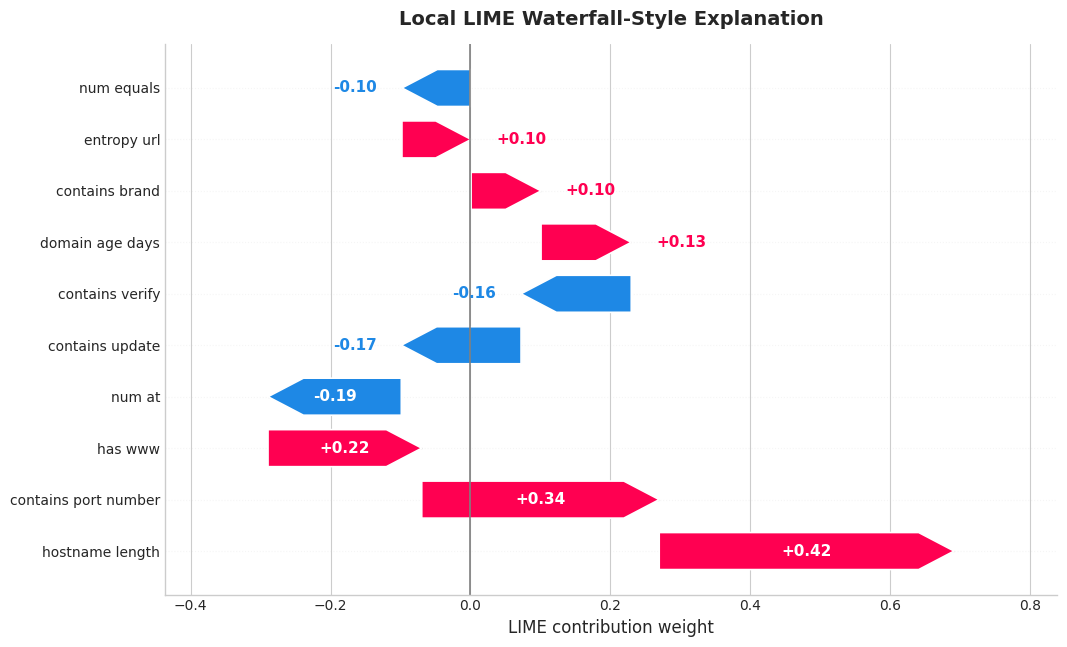

In [14]:
# LIME
sample_lime = lime_df[lime_df["sample_id"] == selected_sample_id].copy()
sample_lime = sample_lime.sort_values("abs_weight", ascending=False).head(10).copy()
sample_lime["feature_label"] = sample_lime["feature_name"].apply(pretty_name)

# aynı görsel aile için benzer sıralama
sample_lime = sample_lime.sort_values("abs_weight", ascending=False).reset_index(drop=True)
sample_lime = sample_lime.iloc[::-1].reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10.8, 6.6))
draw_waterfall_arrows(
    ax=ax,
    labels=sample_lime["feature_label"].tolist(),
    values=sample_lime["weight"].tolist(),
    title="Local LIME Waterfall-Style Explanation",
    xlabel="LIME contribution weight",
    pos_color="#ff0051",
    neg_color="#1e88e5"
)
plt.tight_layout()
plt.savefig(SAVE_DIR / "fig_lime_waterfall_style_pro.png", dpi=600, bbox_inches="tight")
plt.savefig(SAVE_DIR / "fig_lime_waterfall_style_pro.pdf", bbox_inches="tight")
plt.show()

SHAP long shape: (12000, 8)
LIME long shape: (12000, 12)

Selected sample_id: 15209
Predicted phishing probability: 0.9999997630185282


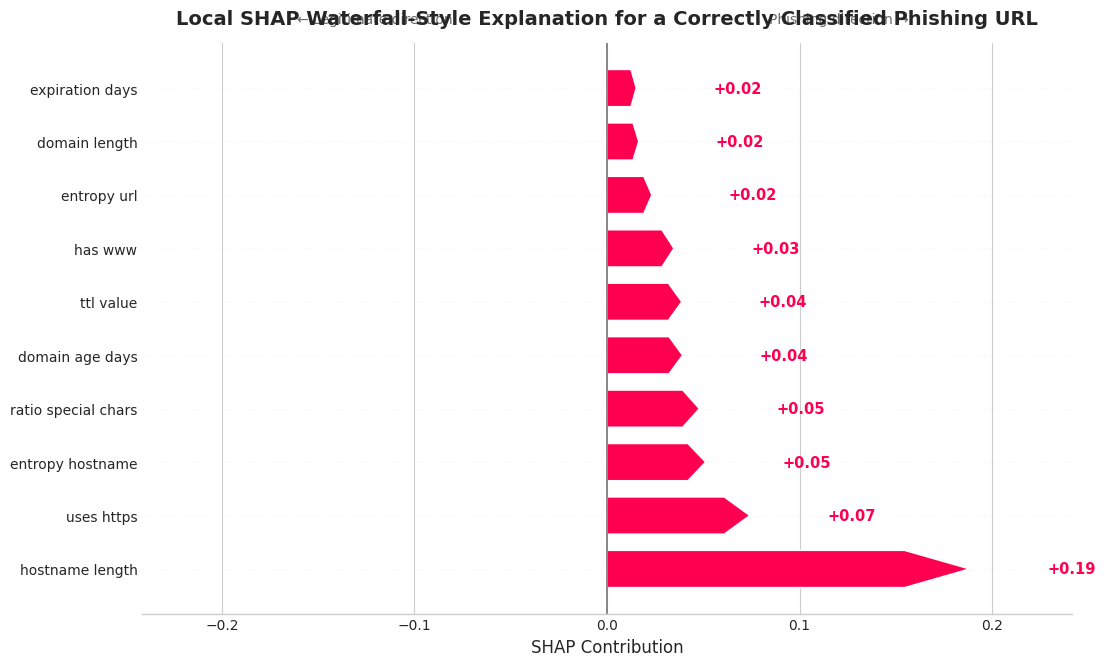

Saved SHAP figure:
C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\paper_local_xai_figures\fig_local_shap_mirrored_premium.png
C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\paper_local_xai_figures\fig_local_shap_mirrored_premium.pdf


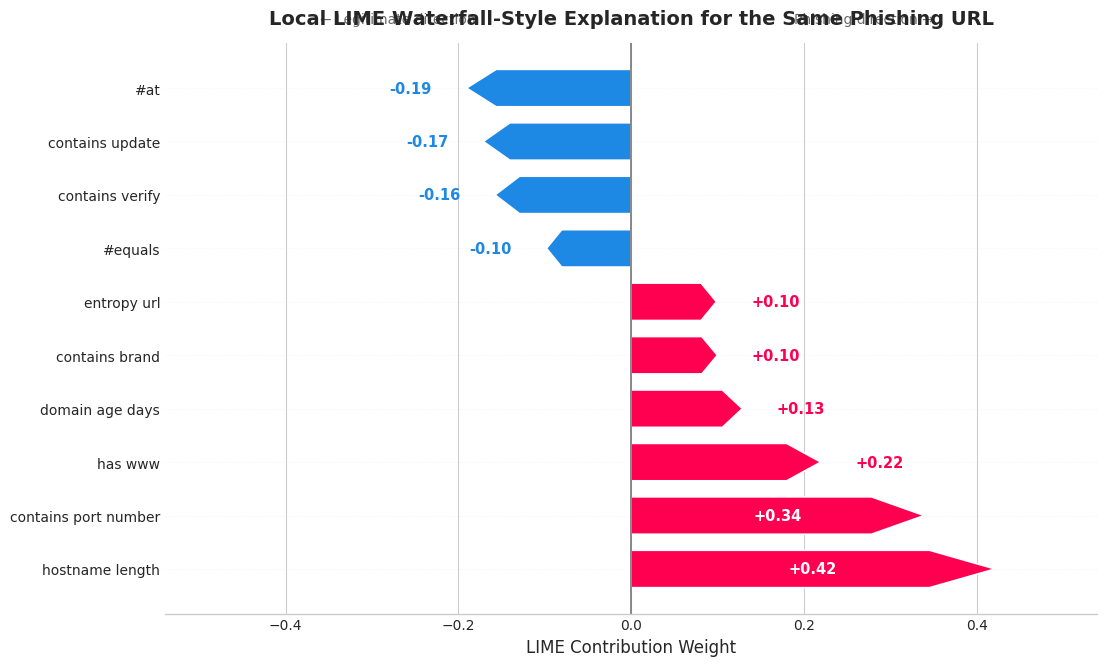

Saved LIME figure:
C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\paper_local_xai_figures\fig_local_lime_mirrored_premium.png
C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\paper_local_xai_figures\fig_local_lime_mirrored_premium.pdf


In [15]:
# =========================================================
# PREMIUM LOCAL XAI FIGURES
# Mirrored waterfall-style plots for SHAP and LIME
# =========================================================

import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

# ---------------------------------------------------------
# STYLE
# ---------------------------------------------------------
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10
})

# ---------------------------------------------------------
# PATHS
# ---------------------------------------------------------
BASE_DIR = Path(r"C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale")
shap_path = BASE_DIR / "outputs" / "LightGBM" / "shap_local_v2_400" / "light_shap_local_long.csv"
lime_path = BASE_DIR / "outputs" / "LightGBM" / "lime_local_v2_400" / "light_lime_explanations_long.csv"
SAVE_DIR = BASE_DIR / "outputs" / "LightGBM" / "paper_local_xai_figures"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------
# LOAD
# ---------------------------------------------------------
shap_df = pd.read_csv(shap_path)
lime_df = pd.read_csv(lime_path)

print("SHAP long shape:", shap_df.shape)
print("LIME long shape:", lime_df.shape)

# ---------------------------------------------------------
# SAMPLE SELECTION
# ---------------------------------------------------------
sample_info = lime_df[["sample_id", "y_true", "y_pred", "p_phishing"]].drop_duplicates()

correct_phish = sample_info[
    (sample_info["y_true"] == 1) & (sample_info["y_pred"] == 1)
].copy()

if correct_phish.empty:
    raise ValueError("Doğru sınıflanmış phishing örneği bulunamadı.")

selected_row = correct_phish.sort_values("p_phishing", ascending=False).iloc[0]
selected_sample_id = int(selected_row["sample_id"])

print("\nSelected sample_id:", selected_sample_id)
print("Predicted phishing probability:", selected_row["p_phishing"])

# ---------------------------------------------------------
# HELPERS
# ---------------------------------------------------------
def pretty_feature_name(s):
    s = str(s).replace("_", " ")
    s = s.replace("num ", "#")
    return s

def add_arrow_patch(ax, x0, x1, y, height, color, edgecolor="white", lw=1.2):
    """
    Draw a horizontal arrow-like polygon from x0 to x1 centered at y.
    """
    width = abs(x1 - x0)
    if width == 0:
        return
    
    tip = min(width * 0.18, 0.10 * max(1.0, width))
    tip = max(tip, width * 0.08)

    y0 = y - height / 2
    y1 = y + height / 2

    if x1 > x0:  # right arrow
        pts = [
            (x0, y0),
            (x1 - tip, y0),
            (x1, y),
            (x1 - tip, y1),
            (x0, y1)
        ]
    else:  # left arrow
        pts = [
            (x0, y0),
            (x1 + tip, y0),
            (x1, y),
            (x1 + tip, y1),
            (x0, y1)
        ]

    poly = Polygon(
        pts,
        closed=True,
        facecolor=color,
        edgecolor=edgecolor,
        linewidth=lw,
        joinstyle="miter"
    )
    ax.add_patch(poly)

def plot_mirrored_contributions(
    df,
    value_col,
    abs_col,
    title,
    xlabel,
    out_png,
    out_pdf,
    top_k=10,
    pos_color="#ff0051",
    neg_color="#1e88e5",
    direction_labels=("Legitimate direction", "Phishing direction")
):
    """
    Premium mirrored contribution plot:
    negative features extend to the left of zero,
    positive features extend to the right of zero.
    """
    plot_df = (
        df.sort_values(abs_col, ascending=False)
        .head(top_k)
        .copy()
    )

    if plot_df.empty:
        raise ValueError("Plot için veri bulunamadı.")

    plot_df["feature_label"] = plot_df["feature_name"].apply(pretty_feature_name)

    # Sort for visual balance: strongest negative at top-left, strongest positive at bottom-right
    neg_df = plot_df[plot_df[value_col] < 0].sort_values(value_col, ascending=True).copy()
    pos_df = plot_df[plot_df[value_col] >= 0].sort_values(value_col, ascending=True).copy()
    plot_df = pd.concat([neg_df, pos_df], axis=0).reset_index(drop=True)

    values = plot_df[value_col].values
    labels = plot_df["feature_label"].values
    n = len(plot_df)

    fig, ax = plt.subplots(figsize=(11.2, 6.8))
    bar_h = 0.70

    for i, (lab, val) in enumerate(zip(labels, values)):
        color = pos_color if val >= 0 else neg_color

        # anchor all bars at zero so both sides are visually balanced
        x0 = 0
        x1 = val

        add_arrow_patch(ax, x0, x1, i, bar_h, color=color, edgecolor="white", lw=1.2)

        # subtle connector guide
        ax.hlines(i, min(0, val), max(0, val), color="lightgray", linewidth=1.0, alpha=0.4, zorder=0)

        # value labels
        txt = f"{val:+.2f}"
        if abs(val) >= 0.22:
            ax.text(
                val / 2, i, txt,
                ha="center", va="center",
                fontsize=10.5, color="white", fontweight="bold"
            )
        else:
            offset = max(np.max(np.abs(values)) * 0.04, 0.04)
            if val >= 0:
                ax.text(
                    val + offset, i, txt,
                    ha="left", va="center",
                    fontsize=10.5, color=pos_color, fontweight="bold"
                )
            else:
                ax.text(
                    val - offset, i, txt,
                    ha="right", va="center",
                    fontsize=10.5, color=neg_color, fontweight="bold"
                )

    # axes / labels
    ax.set_yticks(range(n))
    ax.set_yticklabels(labels)
    ax.invert_yaxis()

    ax.axvline(0, color="gray", linewidth=1.3)
    ax.grid(axis="y", linestyle=":", alpha=0.18)

    ax.set_xlabel(xlabel)
    ax.set_title(title, pad=14)

    # symmetric x-limits
    xmax = np.max(np.abs(values)) if len(values) else 1.0
    pad = xmax * 0.28
    ax.set_xlim(-(xmax + pad), xmax + pad)

    # top direction labels
    ax.text(
        0.25, 1.03,
        f"← {direction_labels[0]}",
        transform=ax.transAxes,
        ha="center", va="bottom",
        fontsize=10, color="dimgray"
    )
    ax.text(
        0.75, 1.03,
        f"{direction_labels[1]} →",
        transform=ax.transAxes,
        ha="center", va="bottom",
        fontsize=10, color="dimgray"
    )

    plt.tight_layout()
    plt.savefig(out_png, dpi=600, bbox_inches="tight")
    plt.savefig(out_pdf, bbox_inches="tight")
    plt.show()

# ---------------------------------------------------------
# FIGURE 1 — SHAP PREMIUM MIRRORED WATERFALL-STYLE
# ---------------------------------------------------------
sample_shap = shap_df[shap_df["sample_id"] == selected_sample_id].copy()

if sample_shap.empty:
    raise ValueError(f"SHAP içinde sample_id={selected_sample_id} bulunamadı.")

plot_mirrored_contributions(
    df=sample_shap,
    value_col="shap_value",
    abs_col="abs_shap",
    title="Local SHAP Waterfall-Style Explanation for a Correctly Classified Phishing URL",
    xlabel="SHAP Contribution",
    out_png=SAVE_DIR / "fig_local_shap_mirrored_premium.png",
    out_pdf=SAVE_DIR / "fig_local_shap_mirrored_premium.pdf",
    top_k=10,
    pos_color="#ff0051",
    neg_color="#1e88e5",
    direction_labels=("Legitimate direction", "Phishing direction")
)

print("Saved SHAP figure:")
print(SAVE_DIR / "fig_local_shap_mirrored_premium.png")
print(SAVE_DIR / "fig_local_shap_mirrored_premium.pdf")

# ---------------------------------------------------------
# FIGURE 2 — LIME PREMIUM MIRRORED WATERFALL-STYLE
# ---------------------------------------------------------
sample_lime = lime_df[lime_df["sample_id"] == selected_sample_id].copy()

if sample_lime.empty:
    raise ValueError(f"LIME içinde sample_id={selected_sample_id} bulunamadı.")

plot_mirrored_contributions(
    df=sample_lime,
    value_col="weight",
    abs_col="abs_weight",
    title="Local LIME Waterfall-Style Explanation for the Same Phishing URL",
    xlabel="LIME Contribution Weight",
    out_png=SAVE_DIR / "fig_local_lime_mirrored_premium.png",
    out_pdf=SAVE_DIR / "fig_local_lime_mirrored_premium.pdf",
    top_k=10,
    pos_color="#ff0051",
    neg_color="#1e88e5",
    direction_labels=("Legitimate direction", "Phishing direction")
)

print("Saved LIME figure:")
print(SAVE_DIR / "fig_local_lime_mirrored_premium.png")
print(SAVE_DIR / "fig_local_lime_mirrored_premium.pdf")

SHAP long shape: (12000, 8)
LIME long shape: (12000, 12)

Selected sample_id: 15209
Predicted phishing probability: 0.9999997630185282


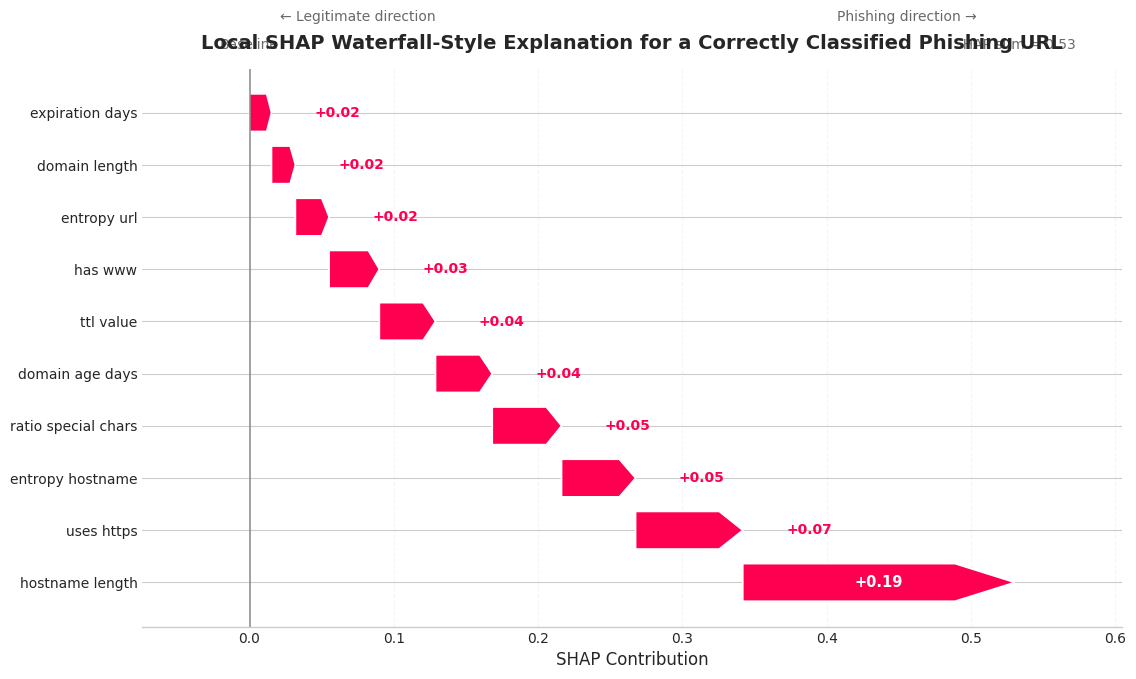

Saved SHAP figure:
C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\paper_local_xai_figures\fig_local_shap_true_cumulative_waterfall.png
C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\paper_local_xai_figures\fig_local_shap_true_cumulative_waterfall.pdf


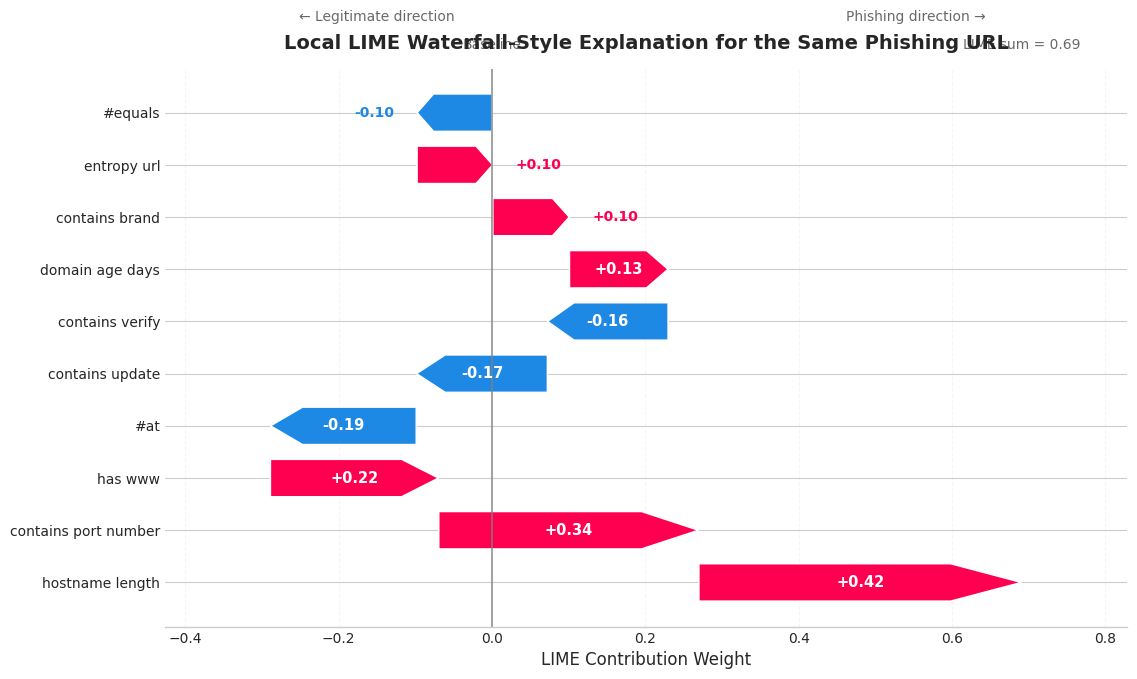

Saved LIME figure:
C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\paper_local_xai_figures\fig_local_lime_true_cumulative_waterfall.png
C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\paper_local_xai_figures\fig_local_lime_true_cumulative_waterfall.pdf


In [16]:
# =========================================================
# TRUE CUMULATIVE PREMIUM WATERFALL PLOTS
# SHAP + LIME
# =========================================================

import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

# ---------------------------------------------------------
# STYLE
# ---------------------------------------------------------
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10
})

# ---------------------------------------------------------
# PATHS
# ---------------------------------------------------------
BASE_DIR = Path(r"C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale")
shap_path = BASE_DIR / "outputs" / "LightGBM" / "shap_local_v2_400" / "light_shap_local_long.csv"
lime_path = BASE_DIR / "outputs" / "LightGBM" / "lime_local_v2_400" / "light_lime_explanations_long.csv"
SAVE_DIR = BASE_DIR / "outputs" / "LightGBM" / "paper_local_xai_figures"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------
# LOAD
# ---------------------------------------------------------
shap_df = pd.read_csv(shap_path)
lime_df = pd.read_csv(lime_path)

print("SHAP long shape:", shap_df.shape)
print("LIME long shape:", lime_df.shape)

# ---------------------------------------------------------
# SAMPLE SELECTION
# ---------------------------------------------------------
sample_info = lime_df[["sample_id", "y_true", "y_pred", "p_phishing"]].drop_duplicates()

correct_phish = sample_info[
    (sample_info["y_true"] == 1) & (sample_info["y_pred"] == 1)
].copy()

if correct_phish.empty:
    raise ValueError("Doğru sınıflanmış phishing örneği bulunamadı.")

selected_row = correct_phish.sort_values("p_phishing", ascending=False).iloc[0]
selected_sample_id = int(selected_row["sample_id"])

print("\nSelected sample_id:", selected_sample_id)
print("Predicted phishing probability:", selected_row["p_phishing"])

# ---------------------------------------------------------
# HELPERS
# ---------------------------------------------------------
def pretty_feature_name(s):
    s = str(s).replace("_", " ")
    s = s.replace("num ", "#")
    return s

def add_step_arrow(ax, start, end, y, height, color, edgecolor="white", lw=1.2):
    """
    Draw a waterfall segment with an arrow head at the end.
    """
    width = abs(end - start)
    if width == 0:
        return

    tip = min(width * 0.22, 0.12 * max(1.0, width))
    tip = max(tip, width * 0.10)

    y0 = y - height / 2
    y1 = y + height / 2

    if end > start:  # move right
        pts = [
            (start, y0),
            (end - tip, y0),
            (end, y),
            (end - tip, y1),
            (start, y1)
        ]
    else:  # move left
        pts = [
            (start, y0),
            (end + tip, y0),
            (end, y),
            (end + tip, y1),
            (start, y1)
        ]

    poly = Polygon(
        pts,
        closed=True,
        facecolor=color,
        edgecolor=edgecolor,
        linewidth=lw,
        joinstyle="miter"
    )
    ax.add_patch(poly)

def prepare_cumulative_df(df, value_col, abs_col, top_k=10):
    """
    Prepare dataframe for true cumulative waterfall.
    Smallest absolute contributions first, largest last,
    so the largest effects appear most prominently.
    """
    plot_df = (
        df.sort_values(abs_col, ascending=False)
        .head(top_k)
        .copy()
    )

    if plot_df.empty:
        raise ValueError("Grafik için veri bulunamadı.")

    # small -> large for cumulative waterfall
    plot_df = plot_df.sort_values(abs_col, ascending=True).reset_index(drop=True)
    plot_df["feature_label"] = plot_df["feature_name"].apply(pretty_feature_name)

    current = 0.0
    starts = []
    ends = []

    for v in plot_df[value_col].values:
        starts.append(current)
        current += v
        ends.append(current)

    plot_df["start"] = starts
    plot_df["end"] = ends
    return plot_df

def plot_true_cumulative_waterfall(
    df,
    value_col,
    abs_col,
    title,
    xlabel,
    out_png,
    out_pdf,
    top_k=10,
    pos_color="#ff0051",
    neg_color="#1e88e5",
    baseline_label="Baseline",
    final_label="Final score"
):
    plot_df = prepare_cumulative_df(df, value_col=value_col, abs_col=abs_col, top_k=top_k)

    values = plot_df[value_col].values
    starts = plot_df["start"].values
    ends = plot_df["end"].values
    labels = plot_df["feature_label"].values

    fig, ax = plt.subplots(figsize=(11.5, 6.9))
    bar_h = 0.72

    for i, (lab, val, start, end) in enumerate(zip(labels, values, starts, ends)):
        color = pos_color if val >= 0 else neg_color

        # faint connector to next stage feel
        ax.hlines(i, min(start, end), max(start, end), color="lightgray", linewidth=1.0, alpha=0.45, zorder=0)

        add_step_arrow(
            ax=ax,
            start=start,
            end=end,
            y=i,
            height=bar_h,
            color=color,
            edgecolor="white",
            lw=1.2
        )

        txt = f"{val:+.2f}"
        if abs(val) >= max(np.max(np.abs(values)) * 0.16, 0.10):
            ax.text(
                (start + end) / 2,
                i,
                txt,
                ha="center",
                va="center",
                fontsize=10.5,
                color="white",
                fontweight="bold"
            )
        else:
            offset = max(np.max(np.abs(values)) * 0.06, 0.03)
            if val >= 0:
                ax.text(
                    end + offset,
                    i,
                    txt,
                    ha="left",
                    va="center",
                    fontsize=10,
                    color=pos_color,
                    fontweight="bold"
                )
            else:
                ax.text(
                    end - offset,
                    i,
                    txt,
                    ha="right",
                    va="center",
                    fontsize=10,
                    color=neg_color,
                    fontweight="bold"
                )

    # y axis
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels)
    ax.invert_yaxis()

    # zero line
    ax.axvline(0, color="gray", linewidth=1.2, alpha=0.85)

    # x grid
    ax.grid(axis="x", linestyle="--", alpha=0.18)

    ax.set_xlabel(xlabel)
    ax.set_title(title, pad=14)

    # limits
    xmin = min(np.min(starts), np.min(ends), 0)
    xmax = max(np.max(starts), np.max(ends), 0)
    span = xmax - xmin if xmax > xmin else 1.0
    pad = span * 0.14
    ax.set_xlim(xmin - pad, xmax + pad)

    # baseline and final markers
    final_score = ends[-1] if len(ends) else 0.0
    ax.text(
        0, 1.03,
        baseline_label,
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="bottom",
        fontsize=10,
        color="dimgray"
    )
    ax.text(
        final_score, 1.03,
        f"{final_label} = {final_score:.2f}",
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="bottom",
        fontsize=10,
        color="dimgray"
    )

    # direction labels
    ax.text(
        0.22, 1.08,
        "← Legitimate direction",
        transform=ax.transAxes,
        ha="center",
        va="bottom",
        fontsize=10,
        color="dimgray"
    )
    ax.text(
        0.78, 1.08,
        "Phishing direction →",
        transform=ax.transAxes,
        ha="center",
        va="bottom",
        fontsize=10,
        color="dimgray"
    )

    plt.tight_layout()
    plt.savefig(out_png, dpi=600, bbox_inches="tight")
    plt.savefig(out_pdf, bbox_inches="tight")
    plt.show()

    return plot_df

# ---------------------------------------------------------
# FIGURE 1 — SHAP TRUE CUMULATIVE WATERFALL
# ---------------------------------------------------------
sample_shap = shap_df[shap_df["sample_id"] == selected_sample_id].copy()

if sample_shap.empty:
    raise ValueError(f"SHAP içinde sample_id={selected_sample_id} bulunamadı.")

shap_plot_df = plot_true_cumulative_waterfall(
    df=sample_shap,
    value_col="shap_value",
    abs_col="abs_shap",
    title="Local SHAP Waterfall-Style Explanation for a Correctly Classified Phishing URL",
    xlabel="SHAP Contribution",
    out_png=SAVE_DIR / "fig_local_shap_true_cumulative_waterfall.png",
    out_pdf=SAVE_DIR / "fig_local_shap_true_cumulative_waterfall.pdf",
    top_k=10,
    pos_color="#ff0051",
    neg_color="#1e88e5",
    baseline_label="Baseline",
    final_label="SHAP sum"
)

print("Saved SHAP figure:")
print(SAVE_DIR / "fig_local_shap_true_cumulative_waterfall.png")
print(SAVE_DIR / "fig_local_shap_true_cumulative_waterfall.pdf")

# ---------------------------------------------------------
# FIGURE 2 — LIME TRUE CUMULATIVE WATERFALL
# ---------------------------------------------------------
sample_lime = lime_df[lime_df["sample_id"] == selected_sample_id].copy()

if sample_lime.empty:
    raise ValueError(f"LIME içinde sample_id={selected_sample_id} bulunamadı.")

lime_plot_df = plot_true_cumulative_waterfall(
    df=sample_lime,
    value_col="weight",
    abs_col="abs_weight",
    title="Local LIME Waterfall-Style Explanation for the Same Phishing URL",
    xlabel="LIME Contribution Weight",
    out_png=SAVE_DIR / "fig_local_lime_true_cumulative_waterfall.png",
    out_pdf=SAVE_DIR / "fig_local_lime_true_cumulative_waterfall.pdf",
    top_k=10,
    pos_color="#ff0051",
    neg_color="#1e88e5",
    baseline_label="Baseline",
    final_label="LIME sum"
)

print("Saved LIME figure:")
print(SAVE_DIR / "fig_local_lime_true_cumulative_waterfall.png")
print(SAVE_DIR / "fig_local_lime_true_cumulative_waterfall.pdf")

In [17]:
# ---------------------------------------------------------
# MORE VISUALLY BALANCED SAMPLE SELECTION
# ---------------------------------------------------------
sample_info = lime_df[["sample_id", "y_true", "y_pred", "p_phishing"]].drop_duplicates().copy()

# doğru sınıflanmış phishing örnekleri
correct_phish = sample_info[
    (sample_info["y_true"] == 1) & (sample_info["y_pred"] == 1)
].copy()

if correct_phish.empty:
    raise ValueError("Doğru sınıflanmış phishing örneği bulunamadı.")

# 0.5'e daha yakın ama hâlâ phishing olan örnekler daha dengeli grafik verir
correct_phish["distance_from_half"] = (correct_phish["p_phishing"] - 0.5).abs()

# çok aşırı uç örneği değil, daha dengeli bir case seç
selected_row = correct_phish.sort_values("distance_from_half", ascending=True).iloc[0]
selected_sample_id = int(selected_row["sample_id"])

print("Selected balanced sample_id:", selected_sample_id)
print("Predicted phishing probability:", selected_row["p_phishing"])

Selected balanced sample_id: 88836
Predicted phishing probability: 0.6665669450725348


Loaded explain_X from: C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\cache_v1\explain_X.csv


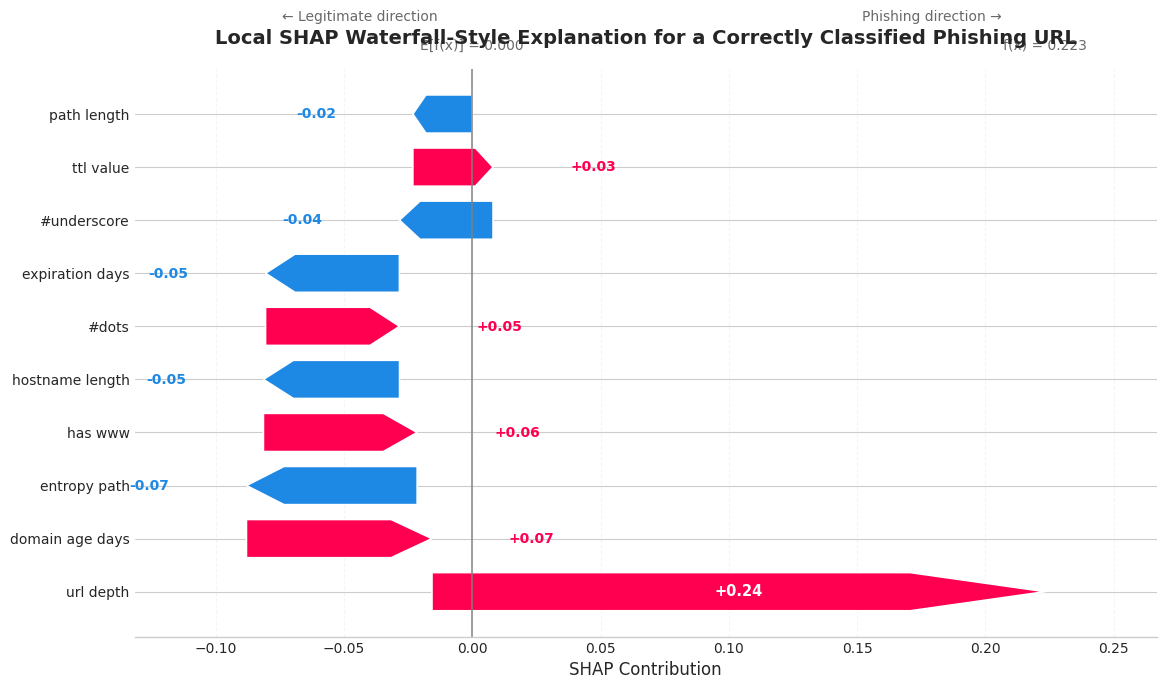

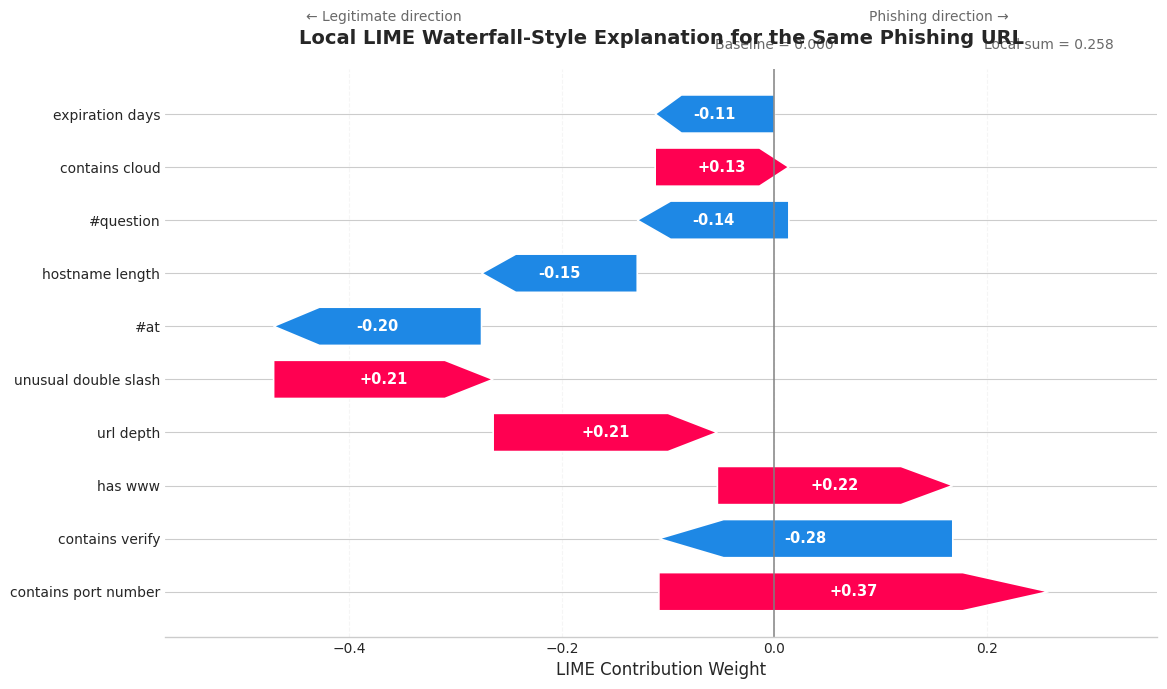

In [18]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10
})

BASE_DIR = Path(r"C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale")
shap_path = BASE_DIR / "outputs" / "LightGBM" / "shap_local_v2_400" / "light_shap_local_long.csv"
lime_path = BASE_DIR / "outputs" / "LightGBM" / "lime_local_v2_400" / "light_lime_explanations_long.csv"
save_dir = BASE_DIR / "outputs" / "LightGBM" / "paper_local_xai_figures"
save_dir.mkdir(parents=True, exist_ok=True)

shap_df = pd.read_csv(shap_path)
lime_df = pd.read_csv(lime_path)

# ---------------------------------------------------------
# TRY LOAD EXPLAIN_X FOR FEATURE VALUES
# ---------------------------------------------------------
x_candidates = [
    BASE_DIR / "outputs" / "LightGBM" / "cache_v1" / "explain_X.csv",
    BASE_DIR / "outputs" / "LightGBM" / "cache" / "explain_X.csv",
]

X_df = None
for p in x_candidates:
    if p.exists():
        try:
            X_df = pd.read_csv(p)
            print("Loaded explain_X from:", p)
            break
        except Exception:
            pass

# ---------------------------------------------------------
# PRETTY LABEL HELPERS
# ---------------------------------------------------------
def pretty_feature_name(s):
    s = str(s).replace("_", " ")
    s = s.replace("num ", "#")
    return s

def format_feature_value(v):
    try:
        fv = float(v)
        if abs(fv - round(fv)) < 1e-8:
            return str(int(round(fv)))
        return f"{fv:.3f}".rstrip("0").rstrip(".")
    except Exception:
        return str(v)

def build_label(feature_name, feature_value=None):
    pname = pretty_feature_name(feature_name)
    if feature_value is None:
        return pname
    return f"{format_feature_value(feature_value)} = {pname}"

# ---------------------------------------------------------
# TRY TO GET FEATURE VALUES FOR SELECTED SAMPLE
# IMPORTANT:
# This only works if selected_sample_id matches row index OR sample_id column exists in X_df
# ---------------------------------------------------------
def get_feature_value_map(sample_id, X_df):
    if X_df is None:
        return {}

    # 1) if X_df has sample_id column
    if "sample_id" in X_df.columns:
        row_match = X_df[X_df["sample_id"] == sample_id]
        if len(row_match) == 1:
            row = row_match.iloc[0]
            return row.to_dict()

    # 2) fallback: if sample_id may equal row index
    if 0 <= sample_id < len(X_df):
        row = X_df.iloc[sample_id]
        return row.to_dict()

    return {}

feature_value_map = get_feature_value_map(selected_sample_id, X_df)

# ---------------------------------------------------------
# ARROW PATCH
# ---------------------------------------------------------
def add_step_arrow(ax, start, end, y, height, color, edgecolor="white", lw=1.2):
    width = abs(end - start)
    if width == 0:
        return

    tip = min(width * 0.22, 0.12 * max(1.0, width))
    tip = max(tip, width * 0.10)

    y0 = y - height / 2
    y1 = y + height / 2

    if end > start:
        pts = [
            (start, y0),
            (end - tip, y0),
            (end, y),
            (end - tip, y1),
            (start, y1)
        ]
    else:
        pts = [
            (start, y0),
            (end + tip, y0),
            (end, y),
            (end + tip, y1),
            (start, y1)
        ]

    poly = Polygon(
        pts,
        closed=True,
        facecolor=color,
        edgecolor=edgecolor,
        linewidth=lw,
        joinstyle="miter"
    )
    ax.add_patch(poly)

# ---------------------------------------------------------
# PREPARE CUMULATIVE DF
# ---------------------------------------------------------
def prepare_cumulative_df(df, value_col, abs_col, sample_id, feature_value_map, top_k=10):
    plot_df = (
        df.sort_values(abs_col, ascending=False)
        .head(top_k)
        .copy()
    )

    if plot_df.empty:
        raise ValueError("Grafik için veri bulunamadı.")

    plot_df = plot_df.sort_values(abs_col, ascending=True).reset_index(drop=True)

    labels = []
    for feat in plot_df["feature_name"]:
        feat_val = feature_value_map.get(feat, None)
        labels.append(build_label(feat, feat_val))

    plot_df["feature_label"] = labels

    current = 0.0
    starts, ends = [], []

    for v in plot_df[value_col].values:
        starts.append(current)
        current += v
        ends.append(current)

    plot_df["start"] = starts
    plot_df["end"] = ends
    return plot_df

# ---------------------------------------------------------
# PLOT FUNCTION
# ---------------------------------------------------------
def plot_premium_waterfall(
    df,
    value_col,
    abs_col,
    title,
    xlabel,
    out_png,
    out_pdf,
    feature_value_map=None,
    top_k=10,
    pos_color="#ff0051",
    neg_color="#1e88e5",
    baseline_value=0.0,
    baseline_label="E[f(x)]",
    final_label="f(x)"
):
    if feature_value_map is None:
        feature_value_map = {}

    plot_df = prepare_cumulative_df(
        df=df,
        value_col=value_col,
        abs_col=abs_col,
        sample_id=selected_sample_id,
        feature_value_map=feature_value_map,
        top_k=top_k
    )

    values = plot_df[value_col].values
    starts = baseline_value + plot_df["start"].values
    ends = baseline_value + plot_df["end"].values
    labels = plot_df["feature_label"].values

    fig, ax = plt.subplots(figsize=(11.8, 7.0))
    bar_h = 0.72

    for i, (val, start, end) in enumerate(zip(values, starts, ends)):
        color = pos_color if val >= 0 else neg_color

        ax.hlines(i, min(start, end), max(start, end), color="lightgray", linewidth=1.0, alpha=0.45, zorder=0)

        add_step_arrow(
            ax=ax,
            start=start,
            end=end,
            y=i,
            height=bar_h,
            color=color,
            edgecolor="white",
            lw=1.2
        )

        txt = f"{val:+.2f}"
        if abs(val) >= max(np.max(np.abs(values)) * 0.16, 0.10):
            ax.text(
                (start + end) / 2,
                i,
                txt,
                ha="center",
                va="center",
                fontsize=10.5,
                color="white",
                fontweight="bold"
            )
        else:
            offset = max(np.max(np.abs(values)) * 0.06, 0.03)
            if val >= 0:
                ax.text(
                    end + offset,
                    i,
                    txt,
                    ha="left",
                    va="center",
                    fontsize=10,
                    color=pos_color,
                    fontweight="bold"
                )
            else:
                ax.text(
                    end - offset,
                    i,
                    txt,
                    ha="right",
                    va="center",
                    fontsize=10,
                    color=neg_color,
                    fontweight="bold"
                )

    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels)
    ax.invert_yaxis()

    ax.axvline(baseline_value, color="gray", linewidth=1.2, alpha=0.9)
    ax.grid(axis="x", linestyle="--", alpha=0.18)

    ax.set_xlabel(xlabel)
    ax.set_title(title, pad=18)

    xmin = min(np.min(starts), np.min(ends), baseline_value)
    xmax = max(np.max(starts), np.max(ends), baseline_value)
    span = xmax - xmin if xmax > xmin else 1.0
    pad = span * 0.14
    ax.set_xlim(xmin - pad, xmax + pad)

    final_score = ends[-1] if len(ends) else baseline_value

    ax.text(
        baseline_value,
        1.03,
        f"{baseline_label} = {baseline_value:.3f}",
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="bottom",
        fontsize=10,
        color="dimgray"
    )

    ax.text(
        final_score,
        1.03,
        f"{final_label} = {final_score:.3f}",
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="bottom",
        fontsize=10,
        color="dimgray"
    )

    ax.text(
        0.22, 1.08,
        "← Legitimate direction",
        transform=ax.transAxes,
        ha="center",
        va="bottom",
        fontsize=10,
        color="dimgray"
    )
    ax.text(
        0.78, 1.08,
        "Phishing direction →",
        transform=ax.transAxes,
        ha="center",
        va="bottom",
        fontsize=10,
        color="dimgray"
    )

    plt.tight_layout()
    plt.savefig(out_png, dpi=600, bbox_inches="tight")
    plt.savefig(out_pdf, bbox_inches="tight")
    plt.show()

# ---------------------------------------------------------
# BASELINES
# ---------------------------------------------------------
# SHAP için gerçek expected value yoksa 0.0 kullanıyoruz
shap_baseline = 0.0

# LIME için en mantıklı taban da 0.0
lime_baseline = 0.0

# ---------------------------------------------------------
# SELECT DATA
# ---------------------------------------------------------
sample_shap = shap_df[shap_df["sample_id"] == selected_sample_id].copy()
sample_lime = lime_df[lime_df["sample_id"] == selected_sample_id].copy()

# ---------------------------------------------------------
# SHAP FIGURE
# ---------------------------------------------------------
plot_premium_waterfall(
    df=sample_shap,
    value_col="shap_value",
    abs_col="abs_shap",
    title="Local SHAP Waterfall-Style Explanation for a Correctly Classified Phishing URL",
    xlabel="SHAP Contribution",
    out_png=save_dir / "fig_local_shap_premium_final.png",
    out_pdf=save_dir / "fig_local_shap_premium_final.pdf",
    feature_value_map=feature_value_map,
    top_k=10,
    pos_color="#ff0051",
    neg_color="#1e88e5",
    baseline_value=shap_baseline,
    baseline_label="E[f(x)]",
    final_label="f(x)"
)

# ---------------------------------------------------------
# LIME FIGURE
# ---------------------------------------------------------
plot_premium_waterfall(
    df=sample_lime,
    value_col="weight",
    abs_col="abs_weight",
    title="Local LIME Waterfall-Style Explanation for the Same Phishing URL",
    xlabel="LIME Contribution Weight",
    out_png=save_dir / "fig_local_lime_premium_final.png",
    out_pdf=save_dir / "fig_local_lime_premium_final.pdf",
    feature_value_map=feature_value_map,
    top_k=10,
    pos_color="#ff0051",
    neg_color="#1e88e5",
    baseline_value=lime_baseline,
    baseline_label="Baseline",
    final_label="Local sum"
)

In [20]:
# =========================================================
# FINAL LOCAL XAI FIGURES
# 1 phishing URL + 1 legitimate URL
# SHAP waterfall-style + LIME bar plot
# =========================================================

import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")  # Ekran göstermeden sadece kaydet
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

# ---------------------------------------------------------
# STYLE
# ---------------------------------------------------------
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10
})

# ---------------------------------------------------------
# PATHS
# ---------------------------------------------------------
BASE_DIR = Path(r"C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale")
shap_path = BASE_DIR / "outputs" / "LightGBM" / "shap_local_v2_400" / "light_shap_local_long.csv"
lime_path = BASE_DIR / "outputs" / "LightGBM" / "lime_local_v2_400" / "light_lime_explanations_long.csv"
SAVE_DIR = BASE_DIR / "outputs" / "LightGBM" / "paper_local_xai_figures"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------
# LOAD
# ---------------------------------------------------------
shap_df = pd.read_csv(shap_path)
lime_df = pd.read_csv(lime_path)

# ---------------------------------------------------------
# SAMPLE SELECTION
# ---------------------------------------------------------
sample_info = lime_df[["sample_id", "y_true", "y_pred", "p_phishing"]].drop_duplicates().copy()

phish_pool = sample_info[
    (sample_info["y_true"] == 1) &
    (sample_info["y_pred"] == 1)
].copy()

legit_pool = sample_info[
    (sample_info["y_true"] == 0) &
    (sample_info["y_pred"] == 0)
].copy()

if phish_pool.empty:
    raise ValueError("Dogru siniflanmis phishing ornegi bulunamadi.")
if legit_pool.empty:
    raise ValueError("Dogru siniflanmis legitimate ornegi bulunamadi.")

phish_pool["balance_score"] = (phish_pool["p_phishing"] - 0.75).abs()
legit_pool["balance_score"] = (legit_pool["p_phishing"] - 0.25).abs()

phish_sample_id = int(phish_pool.sort_values("balance_score").iloc[0]["sample_id"])
legit_sample_id = int(legit_pool.sort_values("balance_score").iloc[0]["sample_id"])

phish_prob = float(phish_pool.sort_values("balance_score").iloc[0]["p_phishing"])
legit_prob = float(legit_pool.sort_values("balance_score").iloc[0]["p_phishing"])

# ---------------------------------------------------------
# HELPERS
# ---------------------------------------------------------
def pretty_feature_name(s):
    s = str(s).replace("_", " ")
    s = s.replace("num ", "#")
    return s

def add_step_arrow(ax, start, end, y, height, color, edgecolor="white", lw=1.0):
    width = abs(end - start)
    if width == 0:
        return

    tip = min(width * 0.22, 0.12 * max(1.0, width))
    tip = max(tip, width * 0.10)

    y0 = y - height / 2
    y1 = y + height / 2

    if end > start:
        pts = [
            (start, y0),
            (end - tip, y0),
            (end, y),
            (end - tip, y1),
            (start, y1)
        ]
    else:
        pts = [
            (start, y0),
            (end + tip, y0),
            (end, y),
            (end + tip, y1),
            (start, y1)
        ]

    poly = Polygon(
        pts,
        closed=True,
        facecolor=color,
        edgecolor=edgecolor,
        linewidth=lw,
        joinstyle="miter"
    )
    ax.add_patch(poly)

def prepare_cumulative_df(df, value_col, abs_col, top_k=8):
    plot_df = (
        df.sort_values(abs_col, ascending=False)
        .head(top_k)
        .copy()
    )
    if plot_df.empty:
        raise ValueError("Grafik icin veri bulunamadi.")

    plot_df = plot_df.sort_values(abs_col, ascending=True).reset_index(drop=True)
    plot_df["feature_label"] = plot_df["feature_name"].apply(pretty_feature_name)

    current = 0.0
    starts, ends = [], []
    for v in plot_df[value_col].values:
        starts.append(current)
        current += v
        ends.append(current)

    plot_df["start"] = starts
    plot_df["end"] = ends
    return plot_df

def plot_shap_waterfall(ax, sample_shap, title, top_k=8,
                        pos_color="#ff0051", neg_color="#1e88e5"):
    plot_df = prepare_cumulative_df(sample_shap, value_col="shap_value", abs_col="abs_shap", top_k=top_k)

    values = plot_df["shap_value"].values
    starts = plot_df["start"].values
    ends = plot_df["end"].values
    labels = plot_df["feature_label"].values

    bar_h = 0.70

    for i, (val, start, end) in enumerate(zip(values, starts, ends)):
        color = pos_color if val >= 0 else neg_color

        ax.hlines(i, min(start, end), max(start, end), color="lightgray", linewidth=0.9, alpha=0.35, zorder=0)
        add_step_arrow(ax, start, end, i, bar_h, color=color, edgecolor="white", lw=1.0)

        txt = f"{val:+.2f}"
        if abs(val) >= max(np.max(np.abs(values)) * 0.17, 0.08):
            ax.text((start + end) / 2, i, txt, ha="center", va="center",
                    fontsize=9, color="white", fontweight="bold")
        else:
            offset = max(np.max(np.abs(values)) * 0.05, 0.02)
            if val >= 0:
                ax.text(end + offset, i, txt, ha="left", va="center",
                        fontsize=8.5, color=pos_color, fontweight="bold")
            else:
                ax.text(end - offset, i, txt, ha="right", va="center",
                        fontsize=8.5, color=neg_color, fontweight="bold")

    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels)
    ax.invert_yaxis()
    ax.axvline(0, color="gray", linewidth=1.1)
    ax.grid(axis="x", linestyle=":", alpha=0.10)

    ax.set_xlabel("SHAP Contribution")
    ax.set_title(title, pad=10)

    xmin = min(np.min(starts), np.min(ends), 0)
    xmax = max(np.max(starts), np.max(ends), 0)
    span = xmax - xmin if xmax > xmin else 1.0
    pad = span * 0.14
    ax.set_xlim(xmin - pad, xmax + pad)

    final_score = ends[-1]
    ax.text(0, 1.02, "Baseline", transform=ax.get_xaxis_transform(),
            ha="center", va="bottom", fontsize=8.5, color="dimgray")
    ax.text(final_score, 1.02, f"Final = {final_score:.2f}", transform=ax.get_xaxis_transform(),
            ha="center", va="bottom", fontsize=8.5, color="dimgray")

def plot_lime_bar(ax, sample_lime, title, top_k=8,
                  pos_color="#ff0051", neg_color="#1e88e5"):
    plot_df = (
        sample_lime.sort_values("abs_weight", ascending=False)
        .head(top_k)
        .sort_values("weight", ascending=True)
        .copy()
    )
    plot_df["feature_label"] = plot_df["feature_name"].apply(pretty_feature_name)

    values = plot_df["weight"].values
    labels = plot_df["feature_label"].values
    colors = [neg_color if v < 0 else pos_color for v in values]

    ax.barh(labels, values, color=colors, edgecolor="black", linewidth=0.6, height=0.68)
    ax.axvline(0, color="gray", linewidth=1.1)
    ax.grid(axis="x", linestyle=":", alpha=0.10)

    xmax = max(abs(values.min()), abs(values.max())) if len(values) else 1.0
    offset = xmax * 0.04 if xmax > 0 else 0.02

    for i, v in enumerate(values):
        if v >= 0:
            ax.text(v + offset, i, f"{v:+.2f}", va="center", ha="left",
                    fontsize=8.5, color=pos_color, fontweight="bold")
        else:
            ax.text(v - offset, i, f"{v:+.2f}", va="center", ha="right",
                    fontsize=8.5, color=neg_color, fontweight="bold")

    ax.set_xlabel("LIME Contribution Weight")
    ax.set_title(title, pad=10)

def build_combined_figure(sample_id, label_name, prob_value, out_name_prefix):
    sample_shap = shap_df[shap_df["sample_id"] == sample_id].copy()
    sample_lime = lime_df[lime_df["sample_id"] == sample_id].copy()

    if sample_shap.empty:
        raise ValueError(f"SHAP icinde sample_id={sample_id} bulunamadi.")
    if sample_lime.empty:
        raise ValueError(f"LIME icinde sample_id={sample_id} bulunamadi.")

    fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
    fig.suptitle(
        f"Local Explanations for a Correctly Classified {label_name} URL (p_phishing = {prob_value:.3f})",
        fontsize=13,
        fontweight="bold",
        y=1.00
    )

    plot_shap_waterfall(
        ax=axes[0],
        sample_shap=sample_shap,
        title="(a) SHAP Waterfall-Style Plot",
        top_k=8
    )

    plot_lime_bar(
        ax=axes[1],
        sample_lime=sample_lime,
        title="(b) LIME Bar Plot",
        top_k=8
    )

    plt.tight_layout()

    png_path = SAVE_DIR / f"{out_name_prefix}.png"
    pdf_path = SAVE_DIR / f"{out_name_prefix}.pdf"

    fig.savefig(png_path, dpi=600, bbox_inches="tight")
    fig.savefig(pdf_path, bbox_inches="tight")
    plt.close(fig)  # Belleği temizle, ekranda gösterme

# ---------------------------------------------------------
# BUILD FIGURES
# ---------------------------------------------------------
build_combined_figure(
    sample_id=phish_sample_id,
    label_name="Phishing",
    prob_value=phish_prob,
    out_name_prefix="fig_phishing_local_xai"
)

build_combined_figure(
    sample_id=legit_sample_id,
    label_name="Legitimate",
    prob_value=legit_prob,
    out_name_prefix="fig_legitimate_local_xai"
)

In [22]:
# =========================================================
# FINAL LOCAL XAI FIGURES
# 1 phishing URL + 1 legitimate URL
# SHAP waterfall-style + LIME bar plot
# FULL CLEAN VERSION
# =========================================================

import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

# ---------------------------------------------------------
# STYLE
# ---------------------------------------------------------
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 11.5,
    "axes.titleweight": "bold",
    "axes.labelsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5
})

# ---------------------------------------------------------
# PATHS
# ---------------------------------------------------------
BASE_DIR = Path(r"C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale")
shap_path = BASE_DIR / "outputs" / "LightGBM" / "shap_local_v2_400" / "light_shap_local_long.csv"
lime_path = BASE_DIR / "outputs" / "LightGBM" / "lime_local_v2_400" / "light_lime_explanations_long.csv"
SAVE_DIR = BASE_DIR / "outputs" / "LightGBM" / "paper_local_xai_figures"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------
# LOAD
# ---------------------------------------------------------
shap_df = pd.read_csv(shap_path)
lime_df = pd.read_csv(lime_path)

print("SHAP long shape:", shap_df.shape)
print("LIME long shape:", lime_df.shape)

# ---------------------------------------------------------
# SAMPLE SELECTION
# balanced and correctly classified
# ---------------------------------------------------------
sample_info = lime_df[["sample_id", "y_true", "y_pred", "p_phishing"]].drop_duplicates().copy()

phish_pool = sample_info[
    (sample_info["y_true"] == 1) &
    (sample_info["y_pred"] == 1)
].copy()

legit_pool = sample_info[
    (sample_info["y_true"] == 0) &
    (sample_info["y_pred"] == 0)
].copy()

if phish_pool.empty:
    raise ValueError("Doğru sınıflanmış phishing örneği bulunamadı.")
if legit_pool.empty:
    raise ValueError("Doğru sınıflanmış legitimate örneği bulunamadı.")

# Dengeli örnek seçimi
phish_pool["balance_score"] = (phish_pool["p_phishing"] - 0.75).abs()
legit_pool["balance_score"] = (legit_pool["p_phishing"] - 0.25).abs()

phish_row = phish_pool.sort_values("balance_score").iloc[0]
legit_row = legit_pool.sort_values("balance_score").iloc[0]

phish_sample_id = int(phish_row["sample_id"])
legit_sample_id = int(legit_row["sample_id"])

phish_prob = float(phish_row["p_phishing"])
legit_prob = float(legit_row["p_phishing"])

print("\nSelected phishing sample_id:", phish_sample_id, "p_phishing =", phish_prob)
print("Selected legitimate sample_id:", legit_sample_id, "p_phishing =", legit_prob)

# ---------------------------------------------------------
# HELPERS
# ---------------------------------------------------------
def pretty_feature_name(s):
    s = str(s).replace("_", " ").strip()

    replacements = {
        "contains": "has",
        "number": "num",
        "length": "len",
        "hostname": "host",
        "domain": "dom",
        "expiration": "exp",
        "question": "question",
        "ampersand": "amp",
        "underscore": "underscore",
        "unusual": "unusual",
        "double slash": "double slash",
        "directory": "dir",
        "ratio": "ratio",
        "special chars": "special chars",
        "entropy": "entropy",
        "days": "days",
        "depth": "depth"
    }

    for old, new in replacements.items():
        s = s.replace(old, new)

    # çok uzun etiketleri manuel kısalt
    manual = {
        "contains port num": "has port num",
        "contains verify": "has verify",
        "contains update": "has update",
        "contains secure": "has secure",
        "contains brand": "has brand",
        "contains cloud": "has cloud",
        "first dir len": "1st dir len",
        "host len": "host len",
        "dom age days": "dom age days",
        "dom len": "dom len",
        "entropy host": "entropy host",
        "entropy path": "entropy path",
        "entropy url": "entropy url",
        "ratio special chars": "ratio special chars"
    }

    if s in manual:
        s = manual[s]

    s = s.replace("num ", "#")
    return s

def add_step_arrow(ax, start, end, y, height, color, edgecolor="white", lw=1.0):
    width = abs(end - start)
    if width == 0:
        return

    tip = min(width * 0.22, 0.12 * max(1.0, width))
    tip = max(tip, width * 0.10)

    y0 = y - height / 2
    y1 = y + height / 2

    if end > start:
        pts = [
            (start, y0),
            (end - tip, y0),
            (end, y),
            (end - tip, y1),
            (start, y1)
        ]
    else:
        pts = [
            (start, y0),
            (end + tip, y0),
            (end, y),
            (end + tip, y1),
            (start, y1)
        ]

    poly = Polygon(
        pts,
        closed=True,
        facecolor=color,
        edgecolor=edgecolor,
        linewidth=lw,
        joinstyle="miter"
    )
    ax.add_patch(poly)

def prepare_cumulative_df(df, value_col, abs_col, top_k=8):
    plot_df = (
        df.sort_values(abs_col, ascending=False)
        .head(top_k)
        .copy()
    )

    if plot_df.empty:
        raise ValueError("Grafik için veri bulunamadı.")

    plot_df = plot_df.sort_values(abs_col, ascending=True).reset_index(drop=True)
    plot_df["feature_label"] = plot_df["feature_name"].apply(pretty_feature_name)

    current = 0.0
    starts, ends = [], []
    for v in plot_df[value_col].values:
        starts.append(current)
        current += v
        ends.append(current)

    plot_df["start"] = starts
    plot_df["end"] = ends
    return plot_df

# ---------------------------------------------------------
# PLOT FUNCTIONS
# ---------------------------------------------------------
def plot_shap_waterfall(ax, sample_shap, title, top_k=8,
                        pos_color="#ff0051", neg_color="#1e88e5"):
    plot_df = prepare_cumulative_df(
        sample_shap,
        value_col="shap_value",
        abs_col="abs_shap",
        top_k=top_k
    )

    values = plot_df["shap_value"].values
    starts = plot_df["start"].values
    ends = plot_df["end"].values
    labels = plot_df["feature_label"].values

    bar_h = 0.68

    for i, (val, start, end) in enumerate(zip(values, starts, ends)):
        color = pos_color if val >= 0 else neg_color

        ax.hlines(
            i,
            min(start, end),
            max(start, end),
            color="lightgray",
            linewidth=0.8,
            alpha=0.30,
            zorder=0
        )

        add_step_arrow(ax, start, end, i, bar_h, color=color, edgecolor="white", lw=1.0)

        txt = f"{val:+.2f}"
        threshold = max(np.max(np.abs(values)) * 0.18, 0.08)

        if abs(val) >= threshold:
            ax.text(
                (start + end) / 2,
                i,
                txt,
                ha="center",
                va="center",
                fontsize=8.3,
                color="white",
                fontweight="bold"
            )
        else:
            offset = max(np.max(np.abs(values)) * 0.05, 0.02)
            if val >= 0:
                ax.text(
                    end + offset,
                    i,
                    txt,
                    ha="left",
                    va="center",
                    fontsize=8.0,
                    color=pos_color,
                    fontweight="bold"
                )
            else:
                ax.text(
                    end - offset,
                    i,
                    txt,
                    ha="right",
                    va="center",
                    fontsize=8.0,
                    color=neg_color,
                    fontweight="bold"
                )

    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels)
    ax.invert_yaxis()

    ax.axvline(0, color="gray", linewidth=1.0)
    ax.grid(axis="x", linestyle=":", alpha=0.08)

    ax.set_xlabel("SHAP Contribution")
    ax.set_title(title, pad=8)

    xmin = min(np.min(starts), np.min(ends), 0)
    xmax = max(np.max(starts), np.max(ends), 0)
    span = xmax - xmin if xmax > xmin else 1.0
    pad = span * 0.16
    ax.set_xlim(xmin - pad, xmax + pad)

    final_score = ends[-1] if len(ends) else 0.0

    ax.text(
        0,
        1.015,
        "Baseline",
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="bottom",
        fontsize=8.0,
        color="dimgray"
    )

    ax.text(
        final_score,
        1.015,
        f"Final = {final_score:.2f}",
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="bottom",
        fontsize=8.0,
        color="dimgray"
    )

    ax.text(
        0.18,
        1.06,
        "← Legitimate",
        transform=ax.transAxes,
        ha="center",
        va="bottom",
        fontsize=7.8,
        color="dimgray"
    )

    ax.text(
        0.82,
        1.06,
        "Phishing →",
        transform=ax.transAxes,
        ha="center",
        va="bottom",
        fontsize=7.8,
        color="dimgray"
    )

def plot_lime_bar(ax, sample_lime, title, top_k=8,
                  pos_color="#ff0051", neg_color="#1e88e5"):
    plot_df = (
        sample_lime.sort_values("abs_weight", ascending=False)
        .head(top_k)
        .sort_values("weight", ascending=True)
        .copy()
    )

    if plot_df.empty:
        raise ValueError("LIME plot için veri bulunamadı.")

    plot_df["feature_label"] = plot_df["feature_name"].apply(pretty_feature_name)

    values = plot_df["weight"].values
    labels = plot_df["feature_label"].values
    colors = [neg_color if v < 0 else pos_color for v in values]

    ax.barh(
        labels,
        values,
        color=colors,
        edgecolor="black",
        linewidth=0.55,
        height=0.66
    )

    ax.axvline(0, color="gray", linewidth=1.0)
    ax.grid(axis="x", linestyle=":", alpha=0.08)

    xmax = max(abs(values.min()), abs(values.max())) if len(values) else 1.0
    offset = xmax * 0.04 if xmax > 0 else 0.02

    for i, v in enumerate(values):
        if v >= 0:
            ax.text(
                v + offset,
                i,
                f"{v:+.2f}",
                va="center",
                ha="left",
                fontsize=8.0,
                color=pos_color,
                fontweight="bold"
            )
        else:
            ax.text(
                v - offset,
                i,
                f"{v:+.2f}",
                va="center",
                ha="right",
                fontsize=8.0,
                color=neg_color,
                fontweight="bold"
            )

    ax.set_xlabel("LIME Contribution Weight")
    ax.set_title(title, pad=8)

    ax.text(
        0.18,
        1.06,
        "← Legitimate",
        transform=ax.transAxes,
        ha="center",
        va="bottom",
        fontsize=7.8,
        color="dimgray"
    )

    ax.text(
        0.82,
        1.06,
        "Phishing →",
        transform=ax.transAxes,
        ha="center",
        va="bottom",
        fontsize=7.8,
        color="dimgray"
    )

# ---------------------------------------------------------
# FIGURE BUILDER
# ---------------------------------------------------------
def build_combined_figure(sample_id, label_name, prob_value, out_name_prefix):
    sample_shap = shap_df[shap_df["sample_id"] == sample_id].copy()
    sample_lime = lime_df[lime_df["sample_id"] == sample_id].copy()

    if sample_shap.empty:
        raise ValueError(f"SHAP içinde sample_id={sample_id} bulunamadı.")
    if sample_lime.empty:
        raise ValueError(f"LIME içinde sample_id={sample_id} bulunamadı.")

    fig, axes = plt.subplots(1, 2, figsize=(17, 6.2))

    fig.suptitle(
        f"Local Explanations for a Correctly Classified {label_name} URL (p_phishing = {prob_value:.3f})",
        fontsize=12.5,
        fontweight="bold",
        y=1.03
    )

    plot_shap_waterfall(
        ax=axes[0],
        sample_shap=sample_shap,
        title="(a) SHAP Waterfall-Style Plot",
        top_k=8
    )

    plot_lime_bar(
        ax=axes[1],
        sample_lime=sample_lime,
        title="(b) LIME Bar Plot",
        top_k=8
    )

    plt.subplots_adjust(wspace=0.42, top=0.84, left=0.08, right=0.98, bottom=0.12)

    png_path = SAVE_DIR / f"{out_name_prefix}.png"
    pdf_path = SAVE_DIR / f"{out_name_prefix}.pdf"

    plt.savefig(png_path, dpi=600, bbox_inches="tight")
    plt.savefig(pdf_path, bbox_inches="tight")
    plt.show()

    print("Saved:")
    print(png_path)
    print(pdf_path)

# ---------------------------------------------------------
# BUILD FINAL FIGURES
# ---------------------------------------------------------
build_combined_figure(
    sample_id=phish_sample_id,
    label_name="Phishing",
    prob_value=phish_prob,
    out_name_prefix="fig_phishing_local_xai"
)

build_combined_figure(
    sample_id=legit_sample_id,
    label_name="Legitimate",
    prob_value=legit_prob,
    out_name_prefix="fig_legitimate_local_xai"
)

SHAP long shape: (12000, 8)
LIME long shape: (12000, 12)

Selected phishing sample_id: 11176 p_phishing = 0.6774973456796893
Selected legitimate sample_id: 86799 p_phishing = 0.2424516777974935


C:\Users\elifo\AppData\Local\Temp\ipykernel_13684\1030424053.py:463: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Saved:
C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\paper_local_xai_figures\fig_phishing_local_xai.png
C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\paper_local_xai_figures\fig_phishing_local_xai.pdf
Saved:
C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\paper_local_xai_figures\fig_legitimate_local_xai.png
C:\Users\elifo\Bitirme_Projesi_Dataset_Olusturma\Makale\outputs\LightGBM\paper_local_xai_figures\fig_legitimate_local_xai.pdf


C:\Users\elifo\AppData\Local\Temp\ipykernel_13684\1030424053.py:463: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [23]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Confusion matrix değerleri
cm = np.array([
    [67368, 483],
    [1046, 47080]   # (47,08 → 47080 olarak düzelttim)
])

labels = ["Legitimate", "Phishing"]

# Figure ayarları (IEEE için ideal boyut)
plt.figure(figsize=(5, 4))

# Heatmap
sns.heatmap(
    cm,
    annot=True,
    fmt=",",  # sayıları virgüllü gösterir (67,368 gibi)
    cmap="Blues",
    cbar=False,
    xticklabels=labels,
    yticklabels=labels,
    linewidths=0.5,
    linecolor='black',
    annot_kws={"size": 12}
)

# Axis label
plt.xlabel("Predicted Label", fontsize=11)
plt.ylabel("True Label", fontsize=11)

# Tick font size
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

# Layout düzenleme
plt.tight_layout()

# Kaydet (IEEE için yüksek kalite)
plt.savefig("confusion_matrix_lightgbm.png", dpi=300)
plt.savefig("confusion_matrix_lightgbm.pdf")

plt.show()

C:\Users\elifo\AppData\Local\Temp\ipykernel_13684\3345094733.py:45: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [24]:
# yüzde hesaplama
cm_sum = cm.sum()
cm_percent = cm / cm_sum * 100

annot = np.empty_like(cm).astype(str)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        annot[i, j] = f"{cm[i, j]:,}\n({cm_percent[i, j]:.2f}%)"

plt.figure(figsize=(5,4))

sns.heatmap(
    cm,
    annot=annot,
    fmt="",
    cmap="Blues",
    cbar=False,
    xticklabels=labels,
    yticklabels=labels,
    linewidths=0.5,
    linecolor='black'
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()
plt.savefig("confusion_matrix_lightgbm_with_percent.png", dpi=300)
plt.show()

C:\Users\elifo\AppData\Local\Temp\ipykernel_13684\2165108333.py:30: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [25]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# --- Değerler ---
cm = np.array([[67368,  483],
               [ 1046, 47080]])

labels = ['Legitimate', 'Phishing']

# --- Hesaplamalar ---
row_sums = cm.sum(axis=1, keepdims=True)
cm_pct   = cm / row_sums * 100  # satır bazlı yüzde

# --- Renk matrisi ---
# Doğru sınıflandırmalar (diagonal) koyu, hatalar açık — tek renk tonu
color_matrix = np.array([[0.8, 0.1],   # TN koyu, FP açık
                          [0.1, 0.6]])  # FN açık, TP orta-koyu

cmap = plt.cm.Blues

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(color_matrix, cmap=cmap, vmin=0, vmax=1)

# --- Hücre içerikleri ---
for i in range(2):
    for j in range(2):
        count = cm[i, j]
        pct   = cm_pct[i, j]
        # Koyu hücrelerde beyaz, açık hücrelerde koyu metin
        text_color = 'white' if color_matrix[i, j] > 0.4 else '#1a2a4a'

        ax.text(j, i,
                f'{count:,}\n({pct:.1f}%)',
                ha='center', va='center',
                fontsize=14, fontweight='bold',
                color=text_color)

# --- Eksenler ---
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(labels, fontsize=13)
ax.set_yticklabels(labels, fontsize=13)
ax.set_xlabel('Predicted Label', fontsize=13, labelpad=10)
ax.set_ylabel('True Label',      fontsize=13, labelpad=10)

# --- Başlık ---
ax.set_title('LightGBM — Confusion Matrix (Test Set)',
             fontsize=14, fontweight='bold', pad=15)

# --- İnce kenar çizgisi ---
for spine in ax.spines.values():
    spine.set_linewidth(1.2)
    spine.set_edgecolor('#444')

plt.tight_layout()
plt.savefig('confusion_matrix_lightgbm_improved.png', dpi=200, bbox_inches='tight')
plt.show()
print("Kaydedildi: confusion_matrix_lightgbm_improved.png")

Kaydedildi: confusion_matrix_lightgbm_improved.png


C:\Users\elifo\AppData\Local\Temp\ipykernel_13684\2864159397.py:59: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [26]:
import matplotlib.pyplot as plt
import numpy as np

# --- Değerler ---
cm = np.array([[67368,  483],
               [ 1046, 47080]])

labels = ['Legitimate', 'Phishing']

# --- Satır bazlı yüzde (her satır = o sınıfın gerçek toplamı) ---
row_sums = cm.sum(axis=1, keepdims=True)
cm_pct   = cm / row_sums * 100

# --- Renk matrisi: diagonal koyu, off-diagonal açık ---
color_matrix = np.array([[0.85, 0.08],
                          [0.08, 0.60]])

cmap = plt.cm.Blues

fig, ax = plt.subplots(figsize=(7, 6))

ax.imshow(color_matrix, cmap=cmap, vmin=0, vmax=1)

# --- Hücre çizgileri: ince beyaz ayırıcı ---
for x in [0.5]:
    ax.axhline(x, color='white', linewidth=2)
    ax.axvline(x, color='white', linewidth=2)

# --- Hücre içerikleri ---
for i in range(2):
    for j in range(2):
        count = cm[i, j]
        pct   = cm_pct[i, j]
        text_color = 'white' if color_matrix[i, j] > 0.4 else '#1a3a5c'

        ax.text(j, i,
                f'{count:,}\n({pct:.1f}%)',
                ha='center', va='center',
                fontsize=14, fontweight='bold',
                color=text_color)

# --- Eksenler ---
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(labels, fontsize=13)
ax.set_yticklabels(labels, fontsize=13)
ax.set_xlabel('Predicted Label', fontsize=13, labelpad=10)
ax.set_ylabel('True Label',      fontsize=13, labelpad=10)
ax.set_title('LightGBM — Confusion Matrix (Test Set)',
             fontsize=14, fontweight='bold', pad=15)

# --- Tüm dış/iç çerçeve çizgilerini ve tick işaretlerini kaldır ---
for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(length=0)

plt.tight_layout()
plt.savefig('confusion_matrix_lightgbm_improved.png', dpi=200, bbox_inches='tight')
plt.show()
print("Kaydedildi.")

Kaydedildi.


C:\Users\elifo\AppData\Local\Temp\ipykernel_13684\822361784.py:59: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [29]:
import matplotlib.pyplot as plt
import numpy as np

# --- Değerler ---
cm = np.array([[67427,  424],
               [ 886, 47247]])

labels = ['Legitimate', 'Phishing']

# --- Satır bazlı yüzde (her satır = o sınıfın gerçek toplamı) ---
row_sums = cm.sum(axis=1, keepdims=True)
cm_pct   = cm / row_sums * 100

# --- Renk matrisi: diagonal koyu, off-diagonal açık ---
color_matrix = np.array([[0.85, 0.08],
                          [0.08, 0.60]])

cmap = plt.cm.Blues

fig, ax = plt.subplots(figsize=(7, 6))

ax.imshow(color_matrix, cmap=cmap, vmin=0, vmax=1)

# --- Hücre sınırları: her hücreye ayrı dikdörtgen (axhline/axvline tüm ekseni keser) ---
for i in range(2):
    for j in range(2):
        rect = plt.Rectangle((j - 0.5, i - 0.5), 1, 1,
                              fill=False, edgecolor='white', linewidth=2)
        ax.add_patch(rect)

# --- Hücre içerikleri ---
for i in range(2):
    for j in range(2):
        count = cm[i, j]
        pct   = cm_pct[i, j]
        text_color = 'white' if color_matrix[i, j] > 0.4 else '#1a3a5c'

        ax.text(j, i,
                f'{count:,}\n({pct:.1f}%)',
                ha='center', va='center',
                fontsize=14, fontweight='bold',
                color=text_color)

# --- Eksenler ---
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(labels, fontsize=13)
ax.set_yticklabels(labels, fontsize=13)
ax.set_xlabel('Predicted Label', fontsize=13, labelpad=10)
ax.set_ylabel('True Label',      fontsize=13, labelpad=10)
ax.set_title('EnsembleStacking AllBase — Confusion Matrix',
             fontsize=14, fontweight='bold', pad=15)

# --- Tüm dış/iç çerçeve çizgilerini ve tick işaretlerini kaldır ---
for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(length=0)

plt.tight_layout()
plt.savefig('confusion_matrix_lightgbm_improved_2.png', dpi=200, bbox_inches='tight')
plt.show()
print("Kaydedildi.")

Kaydedildi.


C:\Users\elifo\AppData\Local\Temp\ipykernel_13684\2102350400.py:61: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

# --- SHAP Grafiği ---
plt.figure(figsize=(9, 6))
ax_shap = sns.barplot(
    data=shap_freq,
    y="feature_name",
    x="sample_count",
    color="#5E3C99"   # deep purple
)

ax_shap.set_title(f"Most Frequent Features in Local SHAP Explanations (Top-{TOP_K})", pad=12)
ax_shap.set_xlabel("Number of Samples")
ax_shap.set_ylabel("Feature")

max_val_shap = shap_freq["sample_count"].max()
for i, v in enumerate(shap_freq["sample_count"]):
    ax_shap.text(v + max_val_shap * 0.01, i, str(v), va="center", fontsize=10)

ax_shap.grid(axis="x", linestyle="--", alpha=0.35)
plt.tight_layout()

# Kaydetme ve Kapatma
plt.savefig("shap_features.png", dpi=300) # dpi=300 makaleler için yüksek çözünürlük sağlar
plt.show() 
plt.close() # Belleği temizlemek için önemli

# --- LIME Grafiği ---
plt.figure(figsize=(9, 6))
ax_lime = sns.barplot(
    data=lime_freq,
    y="feature_name",
    x="sample_count",
    color="#1B9E77"   # emerald teal
)

ax_lime.set_title(f"Most Frequent Features in Local LIME Explanations (Top-{TOP_K})", pad=12)
ax_lime.set_xlabel("Number of Samples")
ax_lime.set_ylabel("Feature")

max_val_lime = lime_freq["sample_count"].max()
for i, v in enumerate(lime_freq["sample_count"]):
    ax_lime.text(v + max_val_lime * 0.01, i, str(v), va="center", fontsize=10)

ax_lime.grid(axis="x", linestyle="--", alpha=0.35)
plt.tight_layout()

# Kaydetme ve Kapatma
plt.savefig("lime_features.png", dpi=300)
plt.show()
plt.close()

NameError: name 'shap_freq' is not defined